# Milestone 5. Tích hợp và truy vết: chạy lại toàn bộ dự án và kiểm chứng số liệu của Final Project Report

**Nhóm N02**, học phần Khoa học Phân tích Dữ liệu, Khoa Công nghệ Thông tin, Trường Đại học Khoa học Tự nhiên, ĐHQG-HCM.
Thành viên: Ngô Triệu Gia Gia (25C11037), Trần Duy Khương (25C12004), Nguyễn Hoàng Nhật Quang (25C12033). Giảng viên phụ trách: TS. Nguyễn Trần Minh Thư.

Notebook này đi kèm báo cáo cuối kỳ `N02_MilestoneP5.docx` và **chạy lại toàn bộ dự án từ tệp dữ liệu gốc đến kết luận cuối** chỉ bằng một lần *Run all*:

| Phần | Nội dung | Tương ứng |
|---|---|---|
| A | Chuẩn bị dữ liệu, kiểm định sau xử lý và phân tích khám phá AQ1 đến AQ7 | Notebook Milestone 3 |
| B | Thực nghiệm mô hình, kiểm định chéo lặp, công bằng, hiệu chuẩn | Notebook Milestone 4 |
| C | Đối chiếu từng số liệu trong báo cáo cuối kỳ với kết quả vừa tính, bảng chấm tiêu chí S1 đến S5, ma trận truy vết, AQ Revision Log, bảng trả lời theo AQ, xuất Excel | Milestone 5 |

**Lưu ý trung thực.** SHAP và LIME chưa được chạy trong dự án (thư viện không có trong môi trường thực nghiệm); phần diễn giải phi tuyến dựa vào hoán vị theo nhóm và ablation. Notebook không tạo thêm kết quả nào ngoài những gì nằm trong báo cáo, và không dùng dữ liệu tổng hợp.

## Đọc trước khi chạy (dành cho giảng viên và các thành viên trong nhóm)

**Cách chạy (3 bước, không cần cài đặt gì):**
1. Mở [Google Colab](https://colab.research.google.com), chọn *File → Upload notebook* và chọn tệp này (hoặc mở tệp từ Google Drive bằng *Open with → Google Colaboratory*).
2. Chọn *Runtime → Run all* (Thời gian chạy → Chạy tất cả).
3. Đợi các ô chạy từ trên xuống dưới, tổng cộng khoảng **8 đến 15 phút (Phần A khoảng 2 phút, Phần B khoảng 5 đến 10 phút, Phần C dưới 1 phút)**. Không cần tải dữ liệu lên, không cần Google Drive, không cần cài thêm thư viện, **không tốn phí** (Colab miễn phí là đủ, không cần GPU).

**Toàn bộ chương trình nằm trong các ô của notebook này.** Không có tệp `.py` hay thư mục mã nguồn đi kèm; nhóm không cần triển khai trên máy cá nhân.

**Cấu trúc.** Notebook ghép ba phần nối tiếp nhau (A, B, C). Số mục trong mỗi phần được đánh số riêng (A1, A2... và B1, B2...); khi một ô giải thích nhắc "Mục 2.2" của Phần B thì đó là B2.2. Bảng truy vết, AQ Revision Log và bảng trả lời theo AQ ở Phần C là nội dung do nhóm soạn (không phải kết quả tính toán) và được ghi sẵn trong ô code tương ứng.

**Dữ liệu lấy ở đâu?** Tệp dữ liệu gốc `Students_Performance_data_set.xlsx` (187 KB, công khai trên Mendeley Data, DOI 10.17632/dc3797vf3t.1, giấy phép CC BY 4.0 cho phép phân phối lại khi ghi nguồn) được **nhúng ngay trong một ô của notebook** dưới dạng một chuỗi chữ dài (đã nén bằng zlib và mã hóa base64; ô này được thu gọn, bấm để xem). Khi chạy, ô kế tiếp giải chuỗi đó thành tệp Excel trong bộ nhớ tạm của Colab. Vì vậy notebook không tải gì từ internet và vẫn chạy được nếu đường dẫn trên Mendeley thay đổi.

**Mã băm SHA-256 là gì?** Đó là "dấu vân tay" của một tệp: một chuỗi 64 ký tự được tính từ nội dung tệp. Chỉ cần đổi một ký tự trong tệp thì dấu vân tay thay đổi hoàn toàn. Notebook tính lại dấu vân tay của tệp vừa giải nén và so với giá trị đã ghi sẵn; nếu khớp thì đúng là tệp nhóm đã dùng, không bị sửa hay hỏng. Với các tệp kết quả, nếu thư viện Colab khác phiên bản (ví dụ cách ghi số thập phân), dấu vân tay có thể khác dù nội dung không đổi; vì thế ngoài dấu vân tay, notebook còn kiểm tra trực tiếp các con số quan trọng (số dòng, số ca dương, các chỉ số trong báo cáo).

**Tệp tạo ra nằm ở đâu?** Trong thư mục tạm `/content/` của phiên Colab (bấm biểu tượng thư mục ở thanh bên trái để xem hoặc tải về). Thư mục này bị xóa khi phiên kết thúc; chạy lại notebook sẽ tạo lại y hệt.

**Nếu một ô báo lỗi:** chọn *Runtime → Restart session and run all* để chạy lại từ đầu (các ô phụ thuộc nhau theo thứ tự, không nên chạy riêng lẻ ở giữa).

## PHẦN A. Chuẩn bị dữ liệu và phân tích khám phá (Milestone 3)

### Giới thiệu Phần A

**Nhóm N02**, học phần Khoa học Phân tích Dữ liệu, Khoa Công nghệ Thông tin, Trường Đại học Khoa học Tự nhiên, ĐHQG-HCM.
Thành viên: Ngô Triệu Gia Gia (25C11037), Trần Duy Khương (25C12004), Nguyễn Hoàng Nhật Quang (25C12033).
Giảng viên phụ trách: TS. Nguyễn Trần Minh Thư.

Notebook này là phần mã nguồn đi kèm báo cáo Milestone 3. Notebook đi từ tệp dữ liệu thô đã thu thập ở Milestone 2 đến **Prepared Dataset v1.0**, sau đó thực hiện phân tích khám phá (EDA) để trả lời từng Analytical Question ở mức phù hợp với dữ liệu.

**Cấu trúc notebook**

| Phần | Nội dung | Mục tương ứng trong báo cáo |
|---|---|---|
| 1 | Thiết lập môi trường và nạp tệp dữ liệu thô | Mục 1 |
| 2 | Hằng số cấu hình và quy tắc miền | Mục 5, Mục 6 |
| 3 | Pipeline chuẩn bị dữ liệu, chín bước có nhật ký biến đổi | Mục 6 |
| 4 | Đóng gói sản phẩm, từ điển dữ liệu, lineage và nhật ký chất lượng | Mục 6, Mục 8 |
| 5 | Kiểm định sau xử lý | Mục 6.5 |
| 6 | Phân tích khám phá AQ1 đến AQ7 | Mục 3, Mục 4, Mục 7 |
| 7 | Kiểm tra tái lập và tóm tắt kết quả | Phụ lục |

**Nguyên tắc thiết kế**

1. Dữ liệu thô bất biến: tệp chỉ được mở ở chế độ đọc và được đối chiếu SHA-256 với Milestone 2.
2. Mọi quyết định xử lý dựa trên quy tắc miền giáo dục hoặc bằng chứng về chất lượng, không dựa vào hiệu năng mô hình. Notebook không huấn luyện mô hình dự báo.
3. Các phép biến đổi cần học tham số từ dữ liệu (chuẩn hóa, điền khuyết theo thống kê) **không** được thực hiện ở đây. Chúng chỉ được đặc tả và sẽ được fit riêng trong từng fold huấn luyện ở Milestone 4, nhằm tránh rò rỉ thông tin từ phần kiểm tra sang phần huấn luyện.
4. Mọi thao tác được ghi vào nhật ký biến đổi để truy vết nguồn gốc của từng biến.


### A1. Thiết lập môi trường

#### A1.1. Thư viện và thư mục làm việc

Notebook dùng `pandas`, `numpy`, `scipy`, `scikit-learn` và `matplotlib`, đều có sẵn trên Colab. Cấu trúc thư mục bám theo gói dữ liệu đã nộp: `data/raw` (tệp gốc, chỉ đọc), `data/interim` (bảng trung gian đã chuẩn hóa kiểu), `data/processed` (bảng phân tích), `data/metadata` (từ điển dữ liệu, lineage, nhật ký) và `reports/milestone3` (bảng, hình của EDA).

In [1]:
import hashlib
import json
import platform
import re
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)

BASE = Path("/content") if Path("/content").exists() else Path.cwd()
ROOT = BASE / "N02_Milestone5"
raw_path = ROOT / "data" / "raw" / "Students_Performance_data_set.xlsx"
interim = ROOT / "data" / "interim"
processed = ROOT / "data" / "processed"
meta = ROOT / "data" / "metadata"
FIG = ROOT / "reports" / "milestone3" / "figures"
TAB = ROOT / "reports" / "milestone3" / "tables"
for d in (raw_path.parent, interim, processed, meta, FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)
print("Thư mục gốc:", ROOT)

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | scipy 1.16.3 | scikit-learn 1.6.1
Thư mục gốc: /content/N02_Milestone5


#### A1.2. Nạp tệp dữ liệu thô

Tệp `Students_Performance_data_set.xlsx` (Mendeley Data, DOI 10.17632/dc3797vf3t.1, giấy phép CC BY 4.0) được nhúng nguyên văn trong ô dưới đây. Mã băm SHA-256 được kiểm tra khi giải nén và phải trùng với giá trị đã ghi trong nhật ký thu thập của Milestone 2.

In [2]:
#@title Ghi tệp dữ liệu thô nhúng sẵn vào data/raw (bấm để xem mã)
import base64, hashlib, zlib

EMBEDDED_FILES = {
    "data/raw/Students_Performance_data_set.xlsx": {
        "sha256": "04ebaf9f3a047afe96d9bff22dbe65b2a320e6395f230032735495e7e58277cf",
        "data": (
            "..."
        ),
    },
}

for rel, item in EMBEDDED_FILES.items():
    target = ROOT / rel
    target.parent.mkdir(parents=True, exist_ok=True)
    raw = zlib.decompress(base64.b64decode(item["data"]))
    digest = hashlib.sha256(raw).hexdigest()
    assert digest == item["sha256"], f"Tệp {rel} bị hỏng khi giải nén"
    if target.exists():
        target.chmod(0o644)
    target.write_bytes(raw)
    print(f"{rel}: {len(raw):,} byte".replace(",", ".") + f", SHA-256 {digest[:16]}... khớp bản gốc")

data/raw/Students_Performance_data_set.xlsx: 187.253 byte, SHA-256 04ebaf9f3a047afe... khớp bản gốc


### A2. Hằng số cấu hình và quy tắc miền

Các hằng số dưới đây được cố định trước khi xử lý và không được học từ dữ liệu:

* **Kiểm tra tệp:** mã băm SHA-256 và kích thước 1.194 × 31 của Milestone 2.
* **Ngưỡng nhãn:** ngưỡng chính CGPA < 2,75 và hai ngưỡng độ nhạy 2,50 và 3,00.
* **Cặp giá trị lặp bất thường:** 140 dòng có cùng cặp SGPA 2,68 và CGPA 3,15 ở mọi học kỳ, được phát hiện ở bước profiling.
* **Ngưỡng miền:** chương trình BCSE chuẩn có 12 học kỳ; một hoạt động không vượt quá 16 giờ mỗi ngày; tổng giờ học, mạng xã hội và phát triển kỹ năng hợp lý không quá 18 giờ; chuyên cần dưới 50% được gắn cờ rà soát.
* **Danh sách vai trò biến:** biến rò rỉ (hệ quả hoặc thành phần của CGPA), biến quan hệ ngược chiều, biến nhạy cảm bị loại và biến chỉ dùng để kiểm định công bằng, theo Mục 2.5 và Mục 8.2 của báo cáo Milestone 2.
* **Tập đặc trưng lõi:** 5 biến thói quen học tập (AQ2) và 8 cột điều kiện, bối cảnh học tập (AQ3), tương ứng 12 mục khảo sát vì trình độ tiếng Anh được mã hóa bằng hai biến giả.

In [3]:
EXPECTED_SHA256 = "04ebaf9f3a047afe96d9bff22dbe65b2a320e6395f230032735495e7e58277cf"
EXPECTED_SHAPE = (1194, 31)
RANDOM_STATE = 42
N_FOLDS = 5

THRESHOLDS = {"y_lt_2_50": 2.50, "y_lt_2_75": 2.75, "y_lt_3_00": 3.00}
PRIMARY_TARGET = "y_lt_2_75"

# Cặp giá trị lặp bất thường (140 dòng) phát hiện ở bước profiling
PLACEHOLDER_SGPA = 2.68
PLACEHOLDER_CGPA = 3.15

# Ngưỡng miền (không học từ dữ liệu)
MAX_STANDARD_SEMESTER = 12      # chương trình BCSE chuẩn gồm 12 học kỳ
MAX_DAILY_HOURS = 16            # giới hạn giờ thức tối đa mỗi ngày cho một hoạt động
TIME_BUDGET_LIMIT = 18          # tổng giờ học + mạng xã hội + kỹ năng tối đa hợp lý
LOW_ATTENDANCE_LIMIT = 50       # chuyên cần dưới 50% được gắn cờ để rà soát

RAW_COLUMNS = [
    "University Admission year",
    "Gender",
    "Age",
    "H.S.C passing year",
    "Program",
    "Current Semester",
    "Do you have meritorious scholarship ?",
    "Do you use University transportation?",
    "How many hour do you study daily?",
    "How many times do you seat for study in a day?",
    "What is your preferable learning mode?",
    "Do you use smart phone?",
    "Do you have personal Computer?",
    "How many hour do you spent daily in social media?",
    "Status of your English language proficiency",
    "Average attendance on class",
    "Did you ever fall in probation?",
    "Did you ever got suspension?",
    "Do you attend in teacher consultancy for any kind of academical problems?",
    "What are the skills do you have ?",
    "How many hour do you spent daily on your skill development?",
    "What is you interested area?",
    "What is your relationship status?",
    "Are you engaged with any co-curriculum activities?",
    "With whom you are living with?",
    "Do you have any health issues?",
    "What was your previous SGPA?",
    "Do you have any physical disabilities?",
    "What is your current CGPA?",
    "How many Credit did you have completed?",
    "What is your monthly family income?",
]

COLUMN_MAP = dict(zip(RAW_COLUMNS, [
    "admit_year", "gender", "age", "hsc_year", "program", "semester",
    "scholarship", "transport", "study_hours", "study_sessions", "learning_mode",
    "smartphone", "pc", "social_hours", "english", "attendance", "probation",
    "suspension", "consultancy", "skills", "skill_hours", "interest_area",
    "relationship", "cocurricular", "living_with", "health_issue", "prev_sgpa",
    "disability", "cgpa", "credits_completed", "family_income",
]))

# Danh sách biến theo vai trò (căn cứ Đề cương Mục 10.4, 10.5 và Milestone 2 Mục 6.2)
LEAKAGE_COLUMNS = ["prev_sgpa", "probation", "suspension", "scholarship"]
REVERSE_DIRECTION_COLUMNS = ["consultancy"]            # chỉ dùng chẩn đoán
SENSITIVE_DROP_COLUMNS = ["family_income", "health_issue", "disability", "relationship"]
AUDIT_ONLY_COLUMNS = ["gender", "living_with"]         # chỉ kiểm định công bằng

CORE_AQ2 = ["study_hours", "study_sessions", "attendance_pct", "social_hours", "skill_hours"]
CORE_AQ3 = ["learning_mode_online", "has_pc", "uses_transport", "english_basic", "english_advance",
            "semester_capped", "credits_completed", "cocurricular"]   # 7 mục khảo sát, 8 cột (tiếng Anh = 2 biến giả)
CORE_FEATURES = CORE_AQ2 + CORE_AQ3
DERIVED_CANDIDATES = ["credits_per_semester", "study_hours_per_session", "study_minus_social"]
OPTIONAL_NOISY = ["skills_group", "interest_group"]

#### A2.1. Tiện ích dùng chung

`TransformationLog` ghi lại từng bước xử lý (số dòng vào, số dòng ra, số giá trị bị thay đổi) để tạo bảng lineage. `sha256_of` tính mã băm theo khối. `yes_no_to_int` quy đổi các câu trả lời Yes/No không thống nhất về 1/0 và để giá trị lạ thành khuyết thay vì đoán.

In [4]:
class TransformationLog:
    """Ghi lại từng bước xử lý để phục vụ truy vết nguồn gốc dữ liệu."""

    def __init__(self) -> None:
        self.rows: list[dict] = []

    def add(self, step: str, description: str, rows_in: int, rows_out: int,
            n_changed: int | None = None) -> None:
        self.rows.append({
            "step": step, "description": description, "rows_in": rows_in,
            "rows_out": rows_out, "n_values_changed": n_changed,
        })

    def to_frame(self) -> pd.DataFrame:
        return pd.DataFrame(self.rows)


def sha256_of(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def yes_no_to_int(s: pd.Series) -> pd.Series:
    """Quy đổi Yes/No (không phân biệt hoa thường) về 1/0; giá trị lạ thành NA."""
    m = s.astype("string").str.strip().str.lower().map({"yes": 1, "y": 1, "no": 0, "n": 0})
    return m.astype("Int64")

### A3. Pipeline chuẩn bị dữ liệu

Pipeline gồm chín bước, mỗi bước là một hàm nhận bảng dữ liệu và nhật ký, trả về bảng mới mà không sửa bảng đầu vào. Mỗi bước được định nghĩa, chạy và kiểm tra kết quả ngay sau đó.

In [5]:
log = TransformationLog()
raw_df = pd.read_excel(raw_path, sheet_name="Students_Performance_data_set")
print("Bảng thô dùng để đối chiếu nhật ký chất lượng:", raw_df.shape)

Bảng thô dùng để đối chiếu nhật ký chất lượng: (1194, 31)


#### A3.1. Bước 1: nạp tệp và kiểm tra giả định về tệp

Bước đầu tiên dừng pipeline nếu tệp không trùng với bản đã thu thập ở Milestone 2 (mã băm, kích thước hoặc danh sách tên cột khác). Đây là cổng kiểm soát để mọi kết quả phía sau gắn với đúng một phiên bản dữ liệu.

In [6]:
def step1_load_and_validate(raw_path: Path, log: TransformationLog) -> pd.DataFrame:
    """Bước 1: nạp tệp thô ở chế độ đọc và kiểm tra giả định về tệp và schema."""
    digest = sha256_of(raw_path)
    if digest != EXPECTED_SHA256:
        raise ValueError(f"SHA-256 không khớp Milestone 2: {digest}")
    df = pd.read_excel(raw_path, sheet_name="Students_Performance_data_set")
    if df.shape != EXPECTED_SHAPE:
        raise ValueError(f"Kích thước {df.shape} khác kỳ vọng {EXPECTED_SHAPE}")
    if list(df.columns) != RAW_COLUMNS:
        raise ValueError("Tên cột không khớp schema đã ghi ở Milestone 2")
    log.add("S1_load", "Nạp tệp thô, đối chiếu SHA-256, kích thước 1194x31 và tên 31 cột",
            len(df), len(df))
    return df


df = step1_load_and_validate(raw_path, log)
print(df.shape)

(1194, 31)


#### A3.2. Bước 2: đổi tên cột và tạo mã dòng

Tên cột gốc là nguyên văn câu hỏi khảo sát nên được đổi sang dạng `snake_case`. Vì tệp không có khóa định danh, nhóm tạo `rid` theo thứ tự dòng và ghi rõ giả định mỗi dòng là một sinh viên.

In [7]:
def step2_rename_and_rowid(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 2: đổi tên cột sang dạng snake_case và tạo mã dòng rid (không có khóa gốc)."""
    out = df.rename(columns=COLUMN_MAP).copy()
    out.insert(0, "rid", np.arange(1, len(out) + 1))
    log.add("S2_rename", "Đổi tên 31 cột, thêm rid = thứ tự dòng trong tệp thô (giả định mỗi dòng "
            "là một sinh viên vì không có khóa định danh)", len(df), len(out))
    return out


df = step2_rename_and_rowid(df, log)
display(df.head(3))

,rid,admit_year,gender,age,hsc_year,program,semester,scholarship,transport,study_hours,study_sessions,learning_mode,smartphone,pc,social_hours,english,attendance,probation,suspension,consultancy,skills,skill_hours,interest_area,relationship,cocurricular,living_with,health_issue,prev_sgpa,disability,cgpa,credits_completed,family_income
0,1,2018,Male,24,2016,BCSE,12,Yes,No,3,2,Offline,Yes,Yes,5,Intermediate,90,No,No,Yes,Software Development,2,Data Schince,Single,Yes,Bachelor,No,2.68,No,3.15,75,25000
1,2,2021,Male,22,2020,BCSE,4,Yes,Yes,3,2,Online,Yes,Yes,3,Basic,96,Yes,No,No,Web development,2,Event management,Single,Yes,Family,No,2.68,No,3.15,36,100000
2,3,2020,Female,21,2019,BCSE,5,No,No,3,3,Offline,Yes,Yes,3,Intermediate,80,No,No,Yes,Programming,1,Software,Single,No,Bachelor,No,2.68,No,3.15,50,50000


#### A3.3. Bước 3: chuẩn hóa kiểu dữ liệu và nhãn phân loại

* **Chuyên cần:** cột bị đọc thành kiểu object do một ô dạng khoảng `94-98`; giá trị khoảng được quy về trung điểm và gắn cờ `attendance_range_flag`.
* **Biến nhị phân:** các câu trả lời Yes/No được mã hóa 1/0; hình thức học ưa thích được mã hóa `learning_mode_online`.
* **Trình độ tiếng Anh:** quan hệ với nhãn có dạng chữ U (Basic và Advance đều có tỷ lệ cần hỗ trợ cao hơn Intermediate), nên biến không được mã hóa thứ bậc cho mô hình mà dùng hai biến giả với Intermediate làm nhóm tham chiếu. Biến thứ bậc `english_level` chỉ được giữ để mô tả.
* **Nhãn không chuẩn hóa** ở các biến nhạy cảm được thống nhất, dù các biến này không đi vào tập đặc trưng.
* **Trường văn bản tự do** (kỹ năng 55 giá trị, lĩnh vực quan tâm 25 giá trị) được gom nhóm bằng quy tắc từ khóa và chỉ giữ ở vai trò tùy chọn do nhiễu cao.

In [8]:
def step3_standardize_types(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 3: chuẩn hóa kiểu dữ liệu và nhãn phân loại."""
    out = df.copy()

    # 3a. Chuyên cần: cột bị đọc thành object vì có ô dạng khoảng "94-98"
    raw_att = out["attendance"].astype("string").str.strip()
    is_range = raw_att.str.match(r"^\d+(\.\d+)?\s*-\s*\d+(\.\d+)?$", na=False)

    def parse_att(v: str) -> float:
        if v is pd.NA or v is None:
            return np.nan
        nums = [float(x) for x in re.findall(r"\d+(?:\.\d+)?", str(v))]
        return float(np.mean(nums)) if nums else np.nan

    out["attendance_pct"] = raw_att.map(parse_att).astype(float)
    out["attendance_range_flag"] = is_range.astype(int)
    log.add("S3a_attendance", "Quy đổi chuyên cần về số; ô dạng khoảng lấy trung điểm (94-98 thành 96) "
            "và gắn cờ attendance_range_flag", len(out), len(out), int(is_range.sum()))

    # 3b. Nhãn Yes/No về 0/1
    for src, dst in [("transport", "uses_transport"), ("smartphone", "has_smartphone"),
                     ("pc", "has_pc"), ("cocurricular", "cocurricular_bin"),
                     ("scholarship", "scholarship_bin"), ("probation", "probation_bin"),
                     ("suspension", "suspension_bin"), ("consultancy", "consultancy_bin")]:
        out[dst] = yes_no_to_int(out[src])
    out["cocurricular"] = out["cocurricular_bin"]
    out["learning_mode_online"] = (out["learning_mode"].str.strip().str.lower() == "online").astype(int)
    out["english_level"] = out["english"].str.strip().map(
        {"Basic": 0, "Intermediate": 1, "Advance": 2}).astype(int)
    # Quan hệ giữa tiếng Anh và nhãn có dạng chữ U (xem EDA, AQ3) nên không mã hóa thứ bậc cho mô hình.
    # Dùng hai biến giả với Intermediate làm nhóm tham chiếu.
    out["english_basic"] = (out["english_level"] == 0).astype(int)
    out["english_advance"] = (out["english_level"] == 2).astype(int)
    log.add("S3b_binary", "Mã hóa Yes/No thành 1/0; learning_mode_online (Online = 1); english_level "
            "(Basic 0, Intermediate 1, Advance 2) chỉ giữ để mô tả; tiếng Anh vào mô hình bằng hai biến giả "
            "english_basic và english_advance (tham chiếu Intermediate)", len(out), len(out))

    # 3c. Chuẩn hóa nhãn không nhất quán ở các biến nhạy cảm (chỉ phục vụ kiểm toán)
    health_before = out["health_issue"].astype("string")
    rel_before = out["relationship"].astype("string")
    h = health_before.str.strip().str.lower().replace({"n": "no"})
    out["health_issue"] = h.str.capitalize()
    out["relationship"] = out["relationship"].replace({"In a relationship": "Relationship"})
    n_cat = int((health_before != out["health_issue"]).sum() + (rel_before != out["relationship"]).sum())
    log.add("S3c_labels", "Chuẩn hóa health_issue (Yes/yes/no/N thành Yes/No) và gộp nhãn đồng nghĩa "
            "của relationship; các biến này không đi vào tập đặc trưng", len(out), len(out), n_cat)

    # 3d. Gom nhóm hai trường văn bản tự do theo từ khóa (nhiễu cao, chỉ ở vai trò tùy chọn)
    def group_skill(v) -> str:
        if pd.isna(v):
            return "Unknown"
        t = str(v).lower()
        if re.search(r"nothing|no skill|not yet|haven't|don't|not any|do not know|^i don|learner|basic", t):
            return "None"
        if "cyber" in t:
            return "Cyber security"
        if "network" in t:
            return "Networking"
        if re.search(r"web|frontend", t):
            return "Web development"
        if re.search(r"artificial|machine", t):
            return "AI and ML"
        if re.search(r"program|software|python|app dev|database", t):
            return "Programming and software"
        return "Other"

    def group_interest(v) -> str:
        if pd.isna(v):
            return "Unknown"
        t = str(v).lower()
        if re.search(r"data|machine|artificial", t):
            return "Data and AI"
        if re.search(r"cyber|syber|network", t):
            return "Network and security"
        if re.search(r"ui/ux", t):
            return "UI/UX"
        if "hardware" in t:
            return "Hardware"
        if re.search(r"software|program|web|game|full stack", t):
            return "Software and web"
        return "Other"

    out["skills_group"] = out["skills"].map(group_skill)
    out["interest_group"] = out["interest_area"].map(group_interest)
    log.add("S3d_text_groups", "Gom skills (55 giá trị) và interest_area (25 giá trị) về nhóm rút gọn "
            "bằng quy tắc từ khóa; giá trị khuyết của skills thành Unknown",
            len(out), len(out), int(out["skills"].isna().sum()))
    return out


df = step3_standardize_types(df, log)
display(df[["attendance", "attendance_pct", "attendance_range_flag"]].loc[df["attendance_range_flag"] == 1])
display(df["english_level"].value_counts().sort_index().rename("Số sinh viên theo english_level (0 Basic, 1 Intermediate, 2 Advance)").to_frame())
display(df["skills_group"].value_counts().to_frame("Số sinh viên theo nhóm kỹ năng"))

,attendance,attendance_pct,attendance_range_flag
457,94-98,96.0,1


,"Số sinh viên theo english_level (0 Basic, 1 Intermediate, 2 Advance)"
english_level,
0,304
1,670
2,220


,Số sinh viên theo nhóm kỹ năng
skills_group,
Programming and software,560
Web development,254
Networking,155
AI and ML,88
Cyber security,87
None,26
Other,23
Unknown,1


#### A3.4. Bước 4: gắn cờ chất lượng

Chín cờ chất lượng được gắn theo ngưỡng miền đã cố định ở Mục 2. Bước này **không xóa dòng nào**; quyết định xử lý dựa trên bằng chứng ở bước kế tiếp.

In [9]:
def step4_flag_quality(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 4: gắn cờ chất lượng (không xóa dòng nào)."""
    out = df.copy()
    out["placeholder_flag"] = ((out["prev_sgpa"].round(2) == PLACEHOLDER_SGPA) &
                               (out["cgpa"].round(2) == PLACEHOLDER_CGPA)).astype(int)
    out["cgpa_zero_flag"] = (out["cgpa"] == 0).astype(int)
    out["sgpa_zero_flag"] = (out["prev_sgpa"] == 0).astype(int)
    out["extended_duration_flag"] = (out["semester"] > MAX_STANDARD_SEMESTER).astype(int)
    out["hsc_invalid_flag"] = (out["hsc_year"] > out["admit_year"]).astype(int)
    out["attendance_low_flag"] = (out["attendance_pct"] < LOW_ATTENDANCE_LIMIT).astype(int)
    out["social_over_cap_flag"] = (out["social_hours"] > MAX_DAILY_HOURS).astype(int)
    budget = out["study_hours"] + out["social_hours"] + out["skill_hours"]
    out["time_budget_flag"] = (budget > TIME_BUDGET_LIMIT).astype(int)
    out["cgpa_extreme_low_flag"] = ((out["cgpa"] > 0) & (out["cgpa"] < 1.0)).astype(int)
    log.add("S4_flags", "Gắn 9 cờ chất lượng (placeholder, cgpa_zero, sgpa_zero, extended_duration, "
            "hsc_invalid, attendance_low, social_over_cap, time_budget, cgpa_extreme_low); không xóa dòng nào",
            len(out), len(out))
    return out


df = step4_flag_quality(df, log)
flag_cols = [c for c in df.columns if c.endswith("_flag")]
display(df[flag_cols].sum().rename("Số dòng bị gắn cờ").to_frame())

,Số dòng bị gắn cờ
attendance_range_flag,1
placeholder_flag,140
cgpa_zero_flag,39
sgpa_zero_flag,39
extended_duration_flag,36
hsc_invalid_flag,1
attendance_low_flag,36
social_over_cap_flag,1
time_budget_flag,11
cgpa_extreme_low_flag,2


#### A3.5. Bước 5 và 6: xử lý giá trị khuyết và giá trị bất hợp lệ

Mỗi quyết định được ghi kèm bằng chứng:

* **CGPA bằng 0** (39 dòng): 37 dòng thuộc học kỳ 1 và phần lớn chưa có tín chỉ, nên được hiểu là chưa có điểm tích lũy và chuyển thành khuyết. Các dòng này không có nhãn và bị loại khỏi mẫu có nhãn.
* **SGPA bằng 0** chuyển thành khuyết; biến này thuộc nhóm rò rỉ nên chỉ giữ trong bảng trung gian để đối chứng.
* **Năm tốt nghiệp THPT sau năm nhập học** là lỗi nhập liệu nên chuyển thành khuyết.
* **Học kỳ lớn hơn 12** là sinh viên học kéo dài hợp lệ (năm nhập học và số tín chỉ nhất quán), được giữ nguyên; biến dùng cho mô hình là `semester_capped = min(semester, 12)`.
* **Giờ mạng xã hội** vượt 16 giờ mỗi ngày được chặn theo ngưỡng miền.
* **Chuyên cần thấp và CGPA rất thấp** được giữ nguyên và chỉ gắn cờ, vì không có cơ sở coi là lỗi.

In [10]:
def step5_handle_missing_invalid(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 5 và 6: xử lý giá trị khuyết và giá trị bất hợp lệ theo bằng chứng."""
    out = df.copy()

    # CGPA = 0: 37/39 dòng là sinh viên học kỳ 1 chưa có tín chỉ nên là "chưa có điểm"
    n0 = int(out["cgpa_zero_flag"].sum())
    out["cgpa_clean"] = out["cgpa"].where(out["cgpa"] > 0, np.nan)
    log.add("S5a_cgpa_zero", "CGPA = 0 chuyển thành khuyết (NaN) vì bằng chứng cho thấy đó là chưa có "
            "điểm tích lũy chứ không phải điểm thật", len(out), len(out), n0)

    # SGPA = 0 trong khi CGPA > 0 là mâu thuẫn; prev_sgpa không dùng làm đặc trưng nhưng vẫn làm sạch
    m = (out["prev_sgpa"] == 0) & (out["cgpa"] > 0)
    out["prev_sgpa_clean"] = out["prev_sgpa"].where(~((out["prev_sgpa"] == 0)), np.nan)
    log.add("S5b_sgpa_zero", "prev_sgpa = 0 chuyển thành khuyết; biến này thuộc nhóm rò rỉ nên chỉ giữ "
            "trong bảng trung gian để đối chứng", len(out), len(out), int((out["prev_sgpa"] == 0).sum()))

    # Năm tốt nghiệp THPT 2028 lớn hơn năm nhập học: lỗi nhập liệu
    out["hsc_year_clean"] = out["hsc_year"].where(out["hsc_invalid_flag"] == 0, np.nan)
    log.add("S5c_hsc", "hsc_year lớn hơn admit_year (2028 so với 2020) chuyển thành khuyết",
            len(out), len(out), int(out["hsc_invalid_flag"].sum()))

    # Học kỳ > 12: sinh viên học kéo dài hợp lệ (xem EDA), giữ nguyên và chặn trên ở biến dùng cho mô hình
    out["semester_capped"] = out["semester"].clip(upper=MAX_STANDARD_SEMESTER)
    log.add("S5d_semester", "Giữ nguyên semester; tạo semester_capped = min(semester, 12) và cờ "
            "extended_duration_flag vì các dòng này có tín chỉ và năm nhập học nhất quán",
            len(out), len(out), int(out["extended_duration_flag"].sum()))

    # Giờ mạng xã hội vượt giới hạn giờ thức: chặn theo ngưỡng miền (không học từ dữ liệu)
    n_cap = int((out["social_hours"] > MAX_DAILY_HOURS).sum())
    out["social_hours"] = out["social_hours"].clip(upper=MAX_DAILY_HOURS)
    log.add("S5e_social_cap", f"Chặn social_hours tại {MAX_DAILY_HOURS} giờ/ngày (ngưỡng miền); giá trị "
            "gốc vẫn còn trong tệp raw", len(out), len(out), n_cap)

    # CGPA cực thấp (<1,0): hợp lệ về miền 0-4 và nhãn luôn là dương, nên giữ nguyên
    log.add("S5g_cgpa_extreme", "Giữ nguyên 2 dòng CGPA dưới 1,0 (cùng học kỳ 2); nhãn y=1 ở mọi ngưỡng nên "
            "không ảnh hưởng tỷ lệ ca dương; chỉ gắn cờ cgpa_extreme_low_flag", len(out), len(out),
            int(out["cgpa_extreme_low_flag"].sum()))

    # Chuyên cần thấp (<50%): giữ nguyên, chỉ gắn cờ; không có cơ sở để coi là lỗi
    log.add("S5f_attendance_low", "Giữ nguyên chuyên cần thấp (<50%); chỉ gắn cờ vì không đủ cơ sở xác "
            "minh là lỗi nhập liệu", len(out), len(out), int(out["attendance_low_flag"].sum()))

    out["skills"] = out["skills"].fillna("Unknown")
    return out


df = step5_handle_missing_invalid(df, log)
print("CGPA khuyết sau xử lý:", int(df["cgpa_clean"].isna().sum()))
print("Giá trị lớn nhất của social_hours sau khi chặn:", df["social_hours"].max())
print("Giá trị lớn nhất của semester_capped:", df["semester_capped"].max())

CGPA khuyết sau xử lý: 39
Giá trị lớn nhất của social_hours sau khi chặn: 16
Giá trị lớn nhất của semester_capped: 12


#### A3.6. Bước 8: đặc trưng dẫn xuất

Ba đặc trưng dẫn xuất được tạo từ trường thực tế với công thức ghi rõ (tín chỉ trung bình mỗi học kỳ, giờ học mỗi lần ngồi học, chênh lệch giờ học và giờ mạng xã hội), cùng ba biến phân tầng theo khóa, nhóm học kỳ và nhóm tuổi. Các đặc trưng dẫn xuất chỉ là ứng viên, chưa thuộc tập đặc trưng lõi. (Bước 7, mã hóa và chuẩn hóa, được hoãn sang Milestone 4 để fit trong từng fold.)

In [11]:
def step8_derive_features(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 8: xây dựng đặc trưng dẫn xuất từ trường thực tế, ghi rõ công thức."""
    out = df.copy()
    out["credits_per_semester"] = np.where(
        (out["semester"] > 0) & (out["credits_completed"] > 0),
        out["credits_completed"] / out["semester"], np.nan)
    out["study_hours_per_session"] = np.where(
        out["study_sessions"] > 0, out["study_hours"] / out["study_sessions"], np.nan)
    out["study_minus_social"] = out["study_hours"] - out["social_hours"]
    out["cohort_band"] = pd.cut(out["admit_year"], bins=[0, 2018, 2019, 2020, 2021, 2100],
                                labels=["<=2018", "2019", "2020", "2021", ">=2022"]).astype(str)
    out["semester_band"] = pd.cut(out["semester"], bins=[0, 4, 8, 100],
                                  labels=["Học kỳ 1-4", "Học kỳ 5-8", "Học kỳ từ 9"]).astype(str)
    out["age_band"] = pd.cut(out["age"], bins=[0, 20, 22, 100],
                             labels=["<=20", "21-22", ">=23"]).astype(str)
    log.add("S8_derived", "Tạo credits_per_semester = credits_completed / semester; "
            "study_hours_per_session = study_hours / study_sessions; study_minus_social = "
            "study_hours - social_hours; cohort_band, semester_band, age_band để phân tầng",
            len(out), len(out))
    return out


df = step8_derive_features(df, log)
display(df[["credits_completed", "semester", "credits_per_semester", "study_hours", "study_sessions",
            "study_hours_per_session", "study_minus_social", "cohort_band", "semester_band"]].head())

,credits_completed,semester,credits_per_semester,study_hours,study_sessions,study_hours_per_session,study_minus_social,cohort_band,semester_band
0,75,12,6.25,3,2,1.500000,-2,<=2018,Học kỳ từ 9
1,36,4,9.00,3,2,1.500000,0,2021,Học kỳ 1-4
2,50,5,10.00,3,3,1.000000,0,2020,Học kỳ 5-8
3,36,4,9.00,1,3,0.333333,-1,2021,Học kỳ 1-4
4,36,4,9.00,3,1,3.000000,1,2021,Học kỳ 1-4


#### A3.7. Bước 9: nhãn, mẫu phân tích và chia fold

* Ba nhãn nhị phân được tạo theo ngưỡng 2,50, 2,75 và 3,00 trên CGPA hợp lệ; dòng không có CGPA hợp lệ có nhãn khuyết.
* **Mẫu chính** gồm các dòng có CGPA hợp lệ và không thuộc cặp lặp 2,68/3,15 (1.015 sinh viên). **Mẫu độ nhạy B** giữ lại cặp lặp (1.155 sinh viên) để kiểm tra kết luận có phụ thuộc quyết định loại cặp lặp hay không.
* Mỗi mẫu được chia thành 5 fold phân tầng theo nhãn chính với `random_state = 42`. Không tách tập hold-out vì số ca dương nhỏ; mỗi fold vẫn có 33 đến 34 ca dương.

In [12]:
def step9_targets_and_folds(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 9: xây dựng nhãn nhị phân, mẫu phân tích và chia fold phân tầng."""
    out = df.copy()
    valid = out["cgpa_clean"].notna()
    for name, thr in THRESHOLDS.items():
        out[name] = pd.array(np.where(valid, (out["cgpa_clean"] < thr).astype(int), -1), dtype="Int64")
        out.loc[~valid, name] = pd.NA

    out["in_primary_sample"] = (valid & (out["placeholder_flag"] == 0)).astype(int)
    out["in_sensitivity_B"] = valid.astype(int)

    # Chia fold phân tầng theo nhãn chính; không tách hold-out (số ca dương quá nhỏ)
    for sample_col, fold_col in [("in_primary_sample", "cv_fold_primary"),
                                 ("in_sensitivity_B", "cv_fold_sensB")]:
        out[fold_col] = pd.array([pd.NA] * len(out), dtype="Int64")
        idx = out.index[out[sample_col] == 1]
        y = out.loc[idx, PRIMARY_TARGET].astype(int).to_numpy()
        skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
        for k, (_, test_pos) in enumerate(skf.split(np.zeros(len(idx)), y)):
            out.loc[idx[test_pos], fold_col] = k
    log.add("S9_targets_folds", "Tạo 3 nhãn nhị phân theo ngưỡng CGPA 2.50, 2.75, 3.00; mẫu chính "
            "(CGPA hợp lệ và không thuộc cặp lặp) và mẫu độ nhạy B (giữ cặp lặp); chia 5 fold "
            "phân tầng theo nhãn 2.75 với random_state=42", len(out), int(out["in_primary_sample"].sum()))
    return out


df = step9_targets_and_folds(df, log)
primary_view = df[df["in_primary_sample"] == 1]
fold_check = primary_view.groupby("cv_fold_primary")[PRIMARY_TARGET].agg(
    n="size", positives=lambda s: int(s.astype(int).sum()))
print("Mẫu chính:", len(primary_view), "| mẫu độ nhạy B:", int(df["in_sensitivity_B"].sum()))
display(fold_check)

Mẫu chính: 1015 | mẫu độ nhạy B: 1155


,n,positives
cv_fold_primary,,
0,203,33
1,203,33
2,203,33
3,203,34
4,203,34


### A4. Đóng gói sản phẩm của Milestone 3

#### A4.1. Bảng trung gian và bảng phân tích

Bước 10 lưu bốn sản phẩm dữ liệu:

* `data/interim/m3_typed_standardized.csv`: toàn bộ 1.194 dòng sau chuẩn hóa kiểu, giữ cả biến bị loại để đối chứng.
* `data/processed/m3_analytic_master.csv`: các biến được phép dùng cho phân tích cùng cờ chất lượng, nhãn và fold.
* `data/processed/m3_analytic_primary_model.csv`: bảng mô hình của mẫu chính, chỉ gồm khóa, 13 đặc trưng lõi, ba nhãn và fold. Bảng này không chứa biến rò rỉ hay biến nhạy cảm.
* `data/processed/m3_audit_groups.csv`: giới tính, nơi ở và nhóm tuổi, chỉ dùng để kiểm định công bằng ở AQ6 và chỉ được nối vào sau khi có điểm dự đoán.

In [13]:
df.to_csv(interim / "m3_typed_standardized.csv", index=False)

keep_master = (["rid"] + CORE_FEATURES + DERIVED_CANDIDATES + OPTIONAL_NOISY + ["consultancy_bin"] +
               ["admit_year", "cohort_band", "semester_band", "cgpa_clean"] + list(THRESHOLDS) +
               ["placeholder_flag", "cgpa_zero_flag", "cgpa_extreme_low_flag", "extended_duration_flag", "attendance_low_flag",
                "attendance_range_flag", "time_budget_flag", "in_primary_sample", "in_sensitivity_B",
                "cv_fold_primary", "cv_fold_sensB"])
master = df[keep_master]
master.to_csv(processed / "m3_analytic_master.csv", index=False)

primary = df[df["in_primary_sample"] == 1]
model_cols = ["rid"] + CORE_FEATURES + list(THRESHOLDS) + ["cv_fold_primary"]
primary[model_cols].to_csv(processed / "m3_analytic_primary_model.csv", index=False)
df[["rid", "gender", "living_with", "age_band", "in_primary_sample", "in_sensitivity_B", PRIMARY_TARGET]].to_csv(
    processed / "m3_audit_groups.csv", index=False)

for p in [interim / "m3_typed_standardized.csv", *sorted(processed.glob("*.csv"))]:
    t = pd.read_csv(p)
    print(f"{p.relative_to(ROOT)}: {t.shape[0]} dòng × {t.shape[1]} cột")
display(primary[model_cols].head())

data/interim/m3_typed_standardized.csv: 1194 dòng × 74 cột
data/processed/m3_analytic_master.csv: 1194 dòng × 38 cột
data/processed/m3_analytic_primary_model.csv: 1015 dòng × 18 cột
data/processed/m3_audit_groups.csv: 1194 dòng × 7 cột


,rid,study_hours,study_sessions,attendance_pct,social_hours,skill_hours,learning_mode_online,has_pc,uses_transport,english_basic,english_advance,semester_capped,credits_completed,cocurricular,y_lt_2_50,y_lt_2_75,y_lt_3_00,cv_fold_primary
7,8,2,2,100.0,2,1,0,1,0,1,0,4,35,0,0,0,0,3
11,12,3,2,90.0,2,2,0,1,0,1,0,4,35,0,0,0,0,2
15,16,2,1,95.0,1,3,0,1,1,1,0,4,35,1,0,0,0,0
18,19,1,2,70.0,3,2,1,1,0,0,1,4,35,0,0,0,0,3
20,21,3,2,96.0,2,1,0,1,0,0,0,4,34,1,0,0,0,0


#### A4.2. Từ điển dữ liệu, lineage và nhật ký chất lượng

Từ điển dữ liệu ghi nguồn, phép biến đổi, kiểu, vai trò, mức nhạy cảm và AQ phục vụ của từng biến, kể cả các biến bị loại cùng lý do loại. Bảng lineage truy vết từ trường nguồn đến biến đã chuẩn bị. Nhật ký chất lượng liệt kê 15 vấn đề với bằng chứng được tính trực tiếp từ dữ liệu.

In [14]:
def build_data_dictionary() -> pd.DataFrame:
    """Từ điển dữ liệu phiên bản Milestone 3: nguồn, biến đổi, vai trò, độ nhạy."""
    rows = [
        # (biến chuẩn bị, trường nguồn, biến đổi, kiểu, vai trò, độ nhạy, AQ)
        ("rid", "(thứ tự dòng)", "Số thứ tự dòng trong tệp thô", "int", "id", "Thấp", "Tất cả"),
        ("study_hours", "How many hour do you study daily?", "Giữ nguyên", "int", "core_feature_AQ2", "Thấp", "AQ2,AQ4,AQ5"),
        ("study_sessions", "How many times do you seat for study in a day?", "Giữ nguyên", "int", "core_feature_AQ2", "Thấp", "AQ2,AQ4,AQ5"),
        ("attendance_pct", "Average attendance on class", "Ép kiểu số; '94-98' lấy trung điểm 96", "float", "core_feature_AQ2", "Thấp", "AQ2,AQ4,AQ5"),
        ("social_hours", "How many hour do you spent daily in social media?", "Chặn trên 16 giờ/ngày", "int", "core_feature_AQ2", "Thấp", "AQ2,AQ4,AQ5"),
        ("skill_hours", "How many hour do you spent daily on your skill development?", "Giữ nguyên", "int", "core_feature_AQ2", "Thấp", "AQ2,AQ4,AQ5"),
        ("learning_mode_online", "What is your preferable learning mode?", "Online = 1, Offline = 0", "int", "core_feature_AQ3", "Thấp", "AQ3,AQ4,AQ5"),
        ("has_pc", "Do you have personal Computer?", "Yes = 1, No = 0", "int", "core_feature_AQ3", "Thấp", "AQ3,AQ4,AQ5"),
        ("uses_transport", "Do you use University transportation?", "Yes = 1, No = 0", "int", "core_feature_AQ3", "Thấp", "AQ3,AQ4,AQ5"),
        ("english_basic", "Status of your English language proficiency", "1 nếu Basic (tham chiếu Intermediate)", "int", "core_feature_AQ3", "Thấp", "AQ3,AQ4,AQ5"),
        ("english_advance", "Status of your English language proficiency", "1 nếu Advance (tham chiếu Intermediate)", "int", "core_feature_AQ3", "Thấp", "AQ3,AQ4,AQ5"),
        ("english_level", "Status of your English language proficiency", "Basic 0, Intermediate 1, Advance 2 (chỉ để mô tả)", "int", "descriptive_only (quan hệ chữ U)", "Thấp", "AQ3"),
        ("semester_capped", "Current Semester", "min(semester, 12)", "int", "core_feature_AQ3", "Thấp", "AQ3,AQ4,AQ5"),
        ("credits_completed", "How many Credit did you have completed?", "Giữ nguyên (rủi ro đồng quy, xem Mục 7)", "int", "core_feature_AQ3", "Trung bình", "AQ3,AQ4,AQ5"),
        ("cocurricular", "Are you engaged with any co-curriculum activities?", "Yes = 1, No = 0", "int", "core_feature_AQ3", "Thấp", "AQ3,AQ4,AQ5"),
        ("credits_per_semester", "How many Credit did you have completed?; Current Semester", "credits_completed / semester", "float", "derived_candidate", "Thấp", "AQ3"),
        ("study_hours_per_session", "How many hour do you study daily?; How many times do you seat for study in a day?", "study_hours / study_sessions", "float", "derived_candidate", "Thấp", "AQ2"),
        ("study_minus_social", "How many hour do you study daily?; How many hour do you spent daily in social media?", "study_hours - social_hours", "int", "derived_candidate", "Thấp", "AQ2"),
        ("skills_group", "What are the skills do you have ?", "Gom 55 giá trị về 7 nhóm bằng từ khóa", "category", "optional_noisy", "Thấp", "Tùy chọn"),
        ("interest_group", "What is you interested area?", "Gom 25 giá trị về 6 nhóm bằng từ khóa", "category", "optional_noisy", "Thấp", "Tùy chọn"),
        ("consultancy_bin", "Do you attend in teacher consultancy for any kind of academical problems?", "Yes = 1, No = 0", "int", "diagnostic_only (quan hệ ngược chiều)", "Trung bình", "AQ3 (chẩn đoán)"),
        ("admit_year", "University Admission year", "Giữ nguyên", "int", "context (phân tầng)", "Thấp", "AQ1,AQ3"),
        ("cohort_band", "University Admission year", "Chia nhóm <=2018, 2019, 2020, 2021, >=2022", "category", "context (phân tầng)", "Thấp", "AQ1"),
        ("semester_band", "Current Semester", "Chia 1-4, 5-8, từ 9", "category", "context (phân tầng)", "Thấp", "AQ2,AQ3"),
        ("cgpa_clean", "What is your current CGPA?", "CGPA = 0 thành NaN", "float", "outcome_source", "Cao", "AQ1,AQ4"),
        ("y_lt_2_50", "What is your current CGPA?", "1 nếu cgpa_clean < 2.50", "Int64", "target (độ nhạy)", "Cao", "AQ1,AQ4"),
        ("y_lt_2_75", "What is your current CGPA?", "1 nếu cgpa_clean < 2.75", "Int64", "target (chính)", "Cao", "AQ1,AQ4"),
        ("y_lt_3_00", "What is your current CGPA?", "1 nếu cgpa_clean < 3.00", "Int64", "target (độ nhạy)", "Cao", "AQ1,AQ4"),
        ("in_primary_sample", "(dẫn xuất)", "CGPA hợp lệ và không thuộc cặp lặp 2.68/3.15", "int", "sample_flag", "Thấp", "Tất cả"),
        ("in_sensitivity_B", "(dẫn xuất)", "CGPA hợp lệ (giữ cặp lặp)", "int", "sample_flag", "Thấp", "Độ nhạy"),
        ("cv_fold_primary", "(dẫn xuất)", "StratifiedKFold 5 phần, seed 42, theo y_lt_2_75", "Int64", "split", "Thấp", "AQ4-AQ7"),
        ("cv_fold_sensB", "(dẫn xuất)", "Như trên trên mẫu độ nhạy B", "Int64", "split", "Thấp", "Độ nhạy"),
        ("gender", "Gender", "Giữ nguyên", "category", "audit_only", "Cao (được bảo vệ)", "AQ6"),
        ("living_with", "With whom you are living with?", "Giữ nguyên", "category", "audit_only", "Cao", "AQ6"),
        ("age_band", "Age", "Chia <=20, 21-22, >=23", "category", "audit_only", "Trung bình", "AQ6"),
        # Biến bị loại khỏi sản phẩm xử lý
        ("prev_sgpa", "What was your previous SGPA?", "Loại khỏi bảng processed", "float", "excluded_leakage", "Cao", "(rò rỉ cấu trúc)"),
        ("probation", "Did you ever fall in probation?", "Loại khỏi bảng processed", "category", "excluded_leakage", "Cao", "(hệ quả của kết quả)"),
        ("suspension", "Did you ever got suspension?", "Loại khỏi bảng processed", "category", "excluded_leakage", "Cao", "(hệ quả của kết quả)"),
        ("scholarship", "Do you have meritorious scholarship ?", "Loại khỏi bảng processed", "category", "excluded_leakage", "Cao", "(hệ quả của kết quả)"),
        ("family_income", "What is your monthly family income?", "Loại khỏi bảng processed", "int", "excluded_sensitive", "Rất cao", "(tối thiểu hóa dữ liệu)"),
        ("health_issue", "Do you have any health issues?", "Loại khỏi bảng processed", "category", "excluded_sensitive", "Rất cao", "(tối thiểu hóa dữ liệu)"),
        ("disability", "Do you have any physical disabilities?", "Loại khỏi bảng processed", "category", "excluded_sensitive", "Rất cao", "(tối thiểu hóa dữ liệu)"),
        ("relationship", "What is your relationship status?", "Loại khỏi bảng processed", "category", "excluded_sensitive", "Cao", "(tối thiểu hóa dữ liệu)"),
        ("program", "Program", "Loại: cột hằng số (chỉ BCSE)", "category", "excluded_constant", "Thấp", "(không phân biệt)"),
        ("smartphone", "Do you use smart phone?", "Loại khỏi tập lõi: 98,7% trả lời Yes", "category", "excluded_quasi_constant", "Thấp", "(phương sai quá thấp)"),
        ("age", "Age", "Chỉ giữ age_band cho kiểm định công bằng", "int", "excluded_demographic", "Trung bình", "(không thuộc AQ2, AQ3)"),
        ("hsc_year", "H.S.C passing year", "Loại: không thuộc AQ; 1 giá trị 2028 bất hợp lý", "int", "excluded_context", "Thấp", "(không thuộc AQ)"),
    ]
    cols = ["prepared_variable", "source_field", "transformation", "dtype", "role", "sensitivity", "aq"]
    return pd.DataFrame(rows, columns=cols)


def build_lineage(dd: pd.DataFrame) -> pd.DataFrame:
    """Bảng Data Lineage theo mẫu hướng dẫn Milestone 3 (Mục 13.1)."""
    window = {"in_primary_sample": "Toàn bộ 1194 dòng",
              "cv_fold_primary": "Mẫu chính (n=1015)", "cv_fold_sensB": "Mẫu độ nhạy B"}
    out = dd[~dd["role"].str.startswith("excluded")].copy()
    out["window_filter"] = out["prepared_variable"].map(window).fillna("Toàn bộ 1194 dòng")
    return out.rename(columns={"prepared_variable": "Prepared Variable", "source_field": "Source Field",
                               "transformation": "Transformation", "window_filter": "Window/Filter",
                               "aq": "Purpose/AQ", "sensitivity": "Sensitivity"})[
        ["Prepared Variable", "Source Field", "Transformation", "Window/Filter", "Purpose/AQ", "Sensitivity"]]


def build_quality_log(raw_df: pd.DataFrame, df: pd.DataFrame) -> pd.DataFrame:
    """Nhật ký vấn đề chất lượng với bằng chứng tính trực tiếp từ dữ liệu."""
    n = len(df)
    ph = df["placeholder_flag"] == 1
    z = df["cgpa_zero_flag"] == 1
    sem1_z = int(((df["semester"] == 1) & z).sum())
    z_credit0 = int(((df["credits_completed"] == 0) & z).sum())
    rows = [
        ("DQ01", "prev_sgpa, cgpa", f"{int(ph.sum())} dòng ({ph.mean():.1%}) có cùng cặp SGPA 2.68 và CGPA 3.15 "
         f"dù học kỳ từ {int(df.loc[ph,'semester'].min())} đến {int(df.loc[ph,'semester'].max())}; cặp lặp phổ biến "
         "thứ hai chỉ gồm 37 dòng và là cặp (0, 0)", "AQ1, AQ4", "High",
         "Loại khỏi mẫu chính; giữ ở mẫu độ nhạy B; đề nghị xác minh với tác giả bộ dữ liệu"),
        ("DQ02", "cgpa", f"{int(z.sum())} dòng CGPA = 0; {sem1_z} dòng ở học kỳ 1, {z_credit0} dòng có 0 tín chỉ",
         "AQ1, AQ4", "High", "Chuyển thành khuyết (chưa có điểm), loại khỏi mẫu có nhãn"),
        ("DQ03", "prev_sgpa", f"{int(((df['prev_sgpa']==0)&(df['cgpa']>0)).sum())} dòng prev_sgpa = 0 nhưng CGPA > 0; "
         f"{int(((df['prev_sgpa']>0)&(df['cgpa']==0)).sum())} dòng CGPA = 0 nhưng prev_sgpa > 0", "AQ1", "Medium",
         "Chuyển prev_sgpa = 0 thành khuyết; biến thuộc nhóm rò rỉ nên không vào mô hình"),
        ("DQ04", "attendance", "1 ô dạng khoảng '94-98' làm cột bị đọc thành kiểu object", "AQ2", "Low",
         "Quy đổi trung điểm 96, gắn cờ attendance_range_flag"),
        ("DQ05", "attendance_pct", f"{int(df['attendance_low_flag'].sum())} dòng chuyên cần dưới 50% "
         f"(thấp nhất {df['attendance_pct'].min():.0f}%); trên mẫu chính, CGPA trung vị của nhóm này là "
         f"{df.loc[(df['attendance_low_flag']==1)&(df['in_primary_sample']==1),'cgpa_clean'].median():.2f} so với "
         f"{df.loc[df['in_primary_sample']==1,'cgpa_clean'].median():.2f} của cả mẫu, "
         "tức hành vi nhất quán với chuyên cần thấp thật", "AQ2", "Medium",
         "Giữ nguyên và gắn cờ; theo dõi bằng phân tích độ nhạy ở Milestone 4"),
        ("DQ06", "semester", f"{int(df['extended_duration_flag'].sum())} dòng semester > 12 (tối đa {int(df['semester'].max())}); "
         "năm nhập học 2013-2018 và số tín chỉ 77-143 nhất quán", "AQ3", "Low",
         "Giữ nguyên (học kéo dài hợp lệ); dùng semester_capped cho mô hình"),
        ("DQ07", "hsc_year", f"{int(df['hsc_invalid_flag'].sum())} dòng năm tốt nghiệp THPT 2028 lớn hơn năm nhập học 2020", "AQ3", "Low",
         "Chuyển thành khuyết; biến không dùng làm đặc trưng"),
        ("DQ08", "social_hours", f"{int((raw_df['How many hour do you spent daily in social media?']>MAX_DAILY_HOURS).sum())} dòng vượt 16 giờ/ngày "
         f"(tối đa {int(raw_df['How many hour do you spent daily in social media?'].max())}); {int(df['time_budget_flag'].sum())} dòng "
         f"có tổng giờ học, mạng xã hội, kỹ năng vượt {TIME_BUDGET_LIMIT} giờ", "AQ2", "Low",
         "Chặn trên 16 giờ theo ngưỡng miền; giữ cờ time_budget_flag"),
        ("DQ09", "health_issue, relationship, interest_area, skills",
         "Nhãn không chuẩn hóa: health_issue có Yes/No/no/N; relationship có 'In a relationship'; "
         "interest_area 25 giá trị và skills 55 giá trị (lỗi chính tả, viết hoa tùy ý)", "AQ2, AQ3", "Medium",
         "Chuẩn hóa nhãn; gom nhóm bằng từ khóa; đặt ở vai trò tùy chọn"),
        ("DQ10", "program", "Cột hằng số: 1 giá trị duy nhất (BCSE)", "Tất cả", "Low", "Loại khỏi tập đặc trưng"),
        ("DQ11", "smartphone", f"{(df['smartphone']=='Yes').mean():.1%} trả lời Yes (chỉ {int((df['smartphone']=='No').sum())} dòng No)",
         "AQ3", "Low", "Loại khỏi tập lõi vì phương sai quá thấp; vẫn mô tả ở EDA"),
        ("DQ12", "family_income", f"Giá trị tối đa {int(df['family_income'].max()):,} so với trung vị {int(df['family_income'].median()):,}",
         "(nhạy cảm)", "Low", "Loại khỏi mọi bảng xử lý theo tối thiểu hóa dữ liệu"),
        ("DQ13", "skills", f"{int(raw_df['What are the skills do you have ?'].isna().sum())} ô khuyết", "(tùy chọn)", "Low",
         "Điền 'Unknown' (biến không thuộc tập lõi)"),
        ("DQ14", "(khóa)", "Không có mã định danh; không kiểm tra được trùng người trả lời", "AQ4-AQ6", "Medium",
         "Tạo rid theo thứ tự dòng; ghi giả định mỗi dòng là một sinh viên"),
        ("DQ15", "cgpa", f"{int(df['cgpa_extreme_low_flag'].sum())} dòng CGPA dưới 1,0 (0,13 và 0,50), cùng học kỳ 2; "
         "giá trị 0,13125 có độ chính xác 5 chữ số thập phân, khác mọi giá trị còn lại", "AQ1", "Low",
         "Giữ nguyên và gắn cờ; nhãn luôn là dương nên không đổi tỷ lệ ca dương"),
    ]
    return pd.DataFrame(rows, columns=["Issue ID", "Variable/Table", "Evidence", "Impact on AQ", "Severity", "Decision"])

In [15]:
dd = build_data_dictionary()
dd.to_csv(meta / "data_dictionary_m3.csv", index=False)
build_lineage(dd).to_csv(meta / "data_lineage_m3.csv", index=False)
qlog = build_quality_log(raw_df, df)
qlog.to_csv(meta / "quality_issue_log_m3.csv", index=False)
log.to_frame().to_csv(meta / "transformation_log_m3.csv", index=False)

display(Markdown("**Từ điển dữ liệu (rút gọn)**"))
display(dd[["prepared_variable", "transformation", "role", "sensitivity", "aq"]])
display(Markdown("**Nhật ký chất lượng dữ liệu**"))
display(qlog)
display(Markdown("**Nhật ký biến đổi (transformation log)**"))
display(log.to_frame())

**Từ điển dữ liệu (rút gọn)**

,prepared_variable,transformation,role,sensitivity,aq
0,rid,Số thứ tự dòng trong tệp thô,id,Thấp,Tất cả
1,study_hours,Giữ nguyên,core_feature_AQ2,Thấp,"AQ2,AQ4,AQ5"
2,study_sessions,Giữ nguyên,core_feature_AQ2,Thấp,"AQ2,AQ4,AQ5"
3,attendance_pct,Ép kiểu số; '94-98' lấy trung điểm 96,core_feature_AQ2,Thấp,"AQ2,AQ4,AQ5"
4,social_hours,Chặn trên 16 giờ/ngày,core_feature_AQ2,Thấp,"AQ2,AQ4,AQ5"
5,skill_hours,Giữ nguyên,core_feature_AQ2,Thấp,"AQ2,AQ4,AQ5"
6,learning_mode_online,"Online = 1, Offline = 0",core_feature_AQ3,Thấp,"AQ3,AQ4,AQ5"
7,has_pc,"Yes = 1, No = 0",core_feature_AQ3,Thấp,"AQ3,AQ4,AQ5"
8,uses_transport,"Yes = 1, No = 0",core_feature_AQ3,Thấp,"AQ3,AQ4,AQ5"
9,english_basic,1 nếu Basic (tham chiếu Intermediate),core_feature_AQ3,Thấp,"AQ3,AQ4,AQ5"


**Nhật ký chất lượng dữ liệu**

,Issue ID,Variable/Table,Evidence,Impact on AQ,Severity,Decision
0,DQ01,"prev_sgpa, cgpa",140 dòng (11.7%) có cùng cặp SGPA 2.68 và CGPA 3.15 dù học kỳ từ 1 đến 22; cặp lặp phổ...,"AQ1, AQ4",High,Loại khỏi mẫu chính; giữ ở mẫu độ nhạy B; đề nghị xác minh với tác giả bộ dữ liệu
1,DQ02,cgpa,"39 dòng CGPA = 0; 37 dòng ở học kỳ 1, 35 dòng có 0 tín chỉ","AQ1, AQ4",High,"Chuyển thành khuyết (chưa có điểm), loại khỏi mẫu có nhãn"
2,DQ03,prev_sgpa,2 dòng prev_sgpa = 0 nhưng CGPA > 0; 2 dòng CGPA = 0 nhưng prev_sgpa > 0,AQ1,Medium,Chuyển prev_sgpa = 0 thành khuyết; biến thuộc nhóm rò rỉ nên không vào mô hình
3,DQ04,attendance,1 ô dạng khoảng '94-98' làm cột bị đọc thành kiểu object,AQ2,Low,"Quy đổi trung điểm 96, gắn cờ attendance_range_flag"
4,DQ05,attendance_pct,"36 dòng chuyên cần dưới 50% (thấp nhất 0%); trên mẫu chính, CGPA trung vị của nhóm này...",AQ2,Medium,Giữ nguyên và gắn cờ; theo dõi bằng phân tích độ nhạy ở Milestone 4
5,DQ06,semester,36 dòng semester > 12 (tối đa 24); năm nhập học 2013-2018 và số tín chỉ 77-143 nhất quán,AQ3,Low,Giữ nguyên (học kéo dài hợp lệ); dùng semester_capped cho mô hình
6,DQ07,hsc_year,1 dòng năm tốt nghiệp THPT 2028 lớn hơn năm nhập học 2020,AQ3,Low,Chuyển thành khuyết; biến không dùng làm đặc trưng
7,DQ08,social_hours,"1 dòng vượt 16 giờ/ngày (tối đa 20); 11 dòng có tổng giờ học, mạng xã hội, kỹ năng vượ...",AQ2,Low,Chặn trên 16 giờ theo ngưỡng miền; giữ cờ time_budget_flag
8,DQ09,"health_issue, relationship, interest_area, skills",Nhãn không chuẩn hóa: health_issue có Yes/No/no/N; relationship có 'In a relationship'...,"AQ2, AQ3",Medium,Chuẩn hóa nhãn; gom nhóm bằng từ khóa; đặt ở vai trò tùy chọn
9,DQ10,program,Cột hằng số: 1 giá trị duy nhất (BCSE),Tất cả,Low,Loại khỏi tập đặc trưng


**Nhật ký biến đổi (transformation log)**

,step,description,rows_in,rows_out,n_values_changed
0,S1_load,"Nạp tệp thô, đối chiếu SHA-256, kích thước 1194x31 và tên 31 cột",1194,1194,NaN
1,S2_rename,"Đổi tên 31 cột, thêm rid = thứ tự dòng trong tệp thô (giả định mỗi dòng là một sinh vi...",1194,1194,NaN
2,S3a_attendance,Quy đổi chuyên cần về số; ô dạng khoảng lấy trung điểm (94-98 thành 96) và gắn cờ atte...,1194,1194,1.0
3,S3b_binary,"Mã hóa Yes/No thành 1/0; learning_mode_online (Online = 1); english_level (Basic 0, In...",1194,1194,NaN
4,S3c_labels,Chuẩn hóa health_issue (Yes/yes/no/N thành Yes/No) và gộp nhãn đồng nghĩa của relation...,1194,1194,5.0
5,S3d_text_groups,Gom skills (55 giá trị) và interest_area (25 giá trị) về nhóm rút gọn bằng quy tắc từ ...,1194,1194,1.0
6,S4_flags,"Gắn 9 cờ chất lượng (placeholder, cgpa_zero, sgpa_zero, extended_duration, hsc_invalid...",1194,1194,NaN
7,S5a_cgpa_zero,CGPA = 0 chuyển thành khuyết (NaN) vì bằng chứng cho thấy đó là chưa có điểm tích lũy ...,1194,1194,39.0
8,S5b_sgpa_zero,prev_sgpa = 0 chuyển thành khuyết; biến này thuộc nhóm rò rỉ nên chỉ giữ trong bảng tr...,1194,1194,39.0
9,S5c_hsc,hsc_year lớn hơn admit_year (2028 so với 2020) chuyển thành khuyết,1194,1194,1.0


#### A4.3. Đặc tả tiền xử lý cho Milestone 4 (chưa fit)

Hàm dưới đây chỉ trả về đặc tả `ColumnTransformer` (điền trung vị và chuẩn hóa RobustScaler cho biến liên tục, giữ nguyên biến nhị phân). Đặc tả này **chưa được fit** ở Milestone 3. Ở Milestone 4, nó được đặt bên trong `Pipeline` và chỉ fit trên phần huấn luyện của từng fold, nhờ đó thống kê của phần kiểm tra không rò rỉ vào quá trình huấn luyện.

In [16]:
def build_preprocessor():
    """Đặc tả tiền xử lý CHƯA FIT cho Milestone 4 (chuẩn hóa chỉ được fit trong từng fold huấn luyện)."""
    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import RobustScaler

    numeric_cont = ["study_hours", "study_sessions", "attendance_pct", "social_hours",
                    "skill_hours", "semester_capped", "credits_completed"]
    passthrough = ["learning_mode_online", "has_pc", "uses_transport", "english_basic", "english_advance",
                   "cocurricular"]
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", RobustScaler())]), numeric_cont),
        ("bin", "passthrough", passthrough),
    ])


pre_spec = build_preprocessor()
print(pre_spec)
print("Đã fit hay chưa:", hasattr(pre_spec, "transformers_"))

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imp',
                                                  SimpleImputer(strategy='median')),
                                                 ('sc', RobustScaler())]),
                                 ['study_hours', 'study_sessions',
                                  'attendance_pct', 'social_hours',
                                  'skill_hours', 'semester_capped',
                                  'credits_completed']),
                                ('bin', 'passthrough',
                                 ['learning_mode_online', 'has_pc',
                                  'uses_transport', 'english_basic',
                                  'english_advance', 'cocurricular'])])
Đã fit hay chưa: False


### A5. Kiểm định sau xử lý

Hàm `validate` kiểm tra tám nhóm điều kiện: số dòng và phân bố nhãn trước và sau, tính duy nhất của khóa, giá trị khuyết trong tập đặc trưng lõi, miền giá trị, sự vắng mặt của biến rò rỉ và nhạy cảm trong tệp mô hình, tính lại thủ công công thức dẫn xuất trên 5 dòng ngẫu nhiên, cân bằng nhãn giữa các fold, và truy xuất nguồn gốc (mã băm tệp thô, phiên bản thư viện, mã băm đầu ra).

In [17]:
def validate(df: pd.DataFrame, master: pd.DataFrame, primary: pd.DataFrame,
             model_cols: list[str], raw_path: Path, processed: Path) -> dict:
    """Kiểm tra trước/sau, toàn vẹn khóa, rò rỉ, miền giá trị và công thức dẫn xuất."""
    checks: dict = {}

    # (a) Số dòng, thực thể, phân bố nhãn trước và sau
    checks["rows_raw"] = int(len(df))
    checks["rows_primary"] = int(len(primary))
    checks["rows_sensB"] = int(df["in_sensitivity_B"].sum())
    checks["removed_placeholder"] = int(df["placeholder_flag"].sum())
    checks["removed_cgpa_missing"] = int(df["cgpa_clean"].isna().sum())
    for name in THRESHOLDS:
        pos = int(primary[name].astype(int).sum())
        checks[f"primary_{name}_positives"] = pos
        checks[f"primary_{name}_rate"] = round(pos / len(primary), 4)
        b = df[df["in_sensitivity_B"] == 1][name].astype(int)
        checks[f"sensB_{name}_positives"] = int(b.sum())
        checks[f"sensB_{name}_rate"] = round(float(b.mean()), 4)

    # (b) Khóa duy nhất và không trùng bản ghi
    checks["rid_unique"] = bool(df["rid"].is_unique)
    checks["duplicate_rows_core"] = int(primary[CORE_FEATURES].duplicated().sum())

    # (c) Khuyết sau xử lý ở tập đặc trưng lõi của mẫu chính
    miss = primary[CORE_FEATURES].isna().sum()
    checks["core_missing_total"] = int(miss.sum())

    # (d) Miền giá trị
    checks["range_attendance_ok"] = bool(primary["attendance_pct"].between(0, 100).all())
    checks["range_cgpa_ok"] = bool(primary["cgpa_clean"].between(0.01, 4.0).all()) if "cgpa_clean" in primary else True
    checks["range_social_ok"] = bool((primary["social_hours"] <= MAX_DAILY_HOURS).all())
    checks["range_semester_capped_ok"] = bool((primary["semester_capped"] <= MAX_STANDARD_SEMESTER).all())

    # (e) Không có biến rò rỉ hoặc nhạy cảm trong tệp mô hình
    forbidden = set(LEAKAGE_COLUMNS + SENSITIVE_DROP_COLUMNS + REVERSE_DIRECTION_COLUMNS + AUDIT_ONLY_COLUMNS +
                    ["prev_sgpa_clean", "consultancy_bin", "scholarship_bin", "probation_bin", "suspension_bin",
                     "gender", "living_with", "age", "age_band", "cgpa", "cgpa_clean"])
    checks["forbidden_in_model_file"] = sorted(set(model_cols) & forbidden)

    # (f) Kiểm tra thủ công công thức dẫn xuất trên 5 dòng ngẫu nhiên (tính lại bằng Python thuần)
    rng = np.random.default_rng(RANDOM_STATE)
    sample_idx = rng.choice(primary.index.to_numpy(), size=5, replace=False)
    ok = True
    for i in sample_idx:
        r = df.loc[i]
        exp_cps = r["credits_completed"] / r["semester"] if (r["credits_completed"] > 0) else float("nan")
        got = r["credits_per_semester"]
        ok &= (np.isnan(exp_cps) and np.isnan(got)) or abs(exp_cps - got) < 1e-9
        ok &= abs((r["study_hours"] - r["social_hours"]) - r["study_minus_social"]) < 1e-9
    checks["derived_manual_check_passed"] = bool(ok)

    # (g) Cân bằng nhãn giữa các fold
    fold_tab = primary.groupby("cv_fold_primary")[PRIMARY_TARGET].agg(["size", lambda s: int(s.astype(int).sum())])
    fold_tab.columns = ["n", "positives"]
    checks["fold_table"] = fold_tab.reset_index().to_dict(orient="records")

    # (h) Truy xuất nguồn gốc
    checks["raw_sha256"] = sha256_of(raw_path)
    checks["raw_sha256_matches_m2"] = checks["raw_sha256"] == EXPECTED_SHA256
    checks["created_utc"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
    checks["python"] = platform.python_version()
    checks["pandas"] = pd.__version__
    checks["numpy"] = np.__version__
    checks["random_state"] = RANDOM_STATE
    checks["output_sha256"] = {p.name: sha256_of(p) for p in sorted(processed.glob("*.csv"))}
    return checks

In [18]:
summary = validate(df, master, primary, model_cols, raw_path, processed)
with open(meta / "validation_summary_m3.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=str)

show = {k: v for k, v in summary.items() if k not in ("output_sha256", "fold_table")}
display(pd.Series(show, name="Giá trị").to_frame())
assert summary["rows_primary"] == 1015 and summary["primary_y_lt_2_75_positives"] == 167
assert summary["forbidden_in_model_file"] == [] and summary["core_missing_total"] == 0
assert summary["raw_sha256_matches_m2"] and summary["derived_manual_check_passed"]
print("Tất cả điều kiện kiểm định sau xử lý đều đạt.")

,Giá trị
rows_raw,1194
rows_primary,1015
rows_sensB,1155
removed_placeholder,140
removed_cgpa_missing,39
primary_y_lt_2_50_positives,52
primary_y_lt_2_50_rate,0.0512
sensB_y_lt_2_50_positives,52
sensB_y_lt_2_50_rate,0.045
primary_y_lt_2_75_positives,167


Tất cả điều kiện kiểm định sau xử lý đều đạt.


### A6. Phân tích khám phá dữ liệu (EDA)

Phần này trả lời từng Analytical Question bằng bằng chứng từ dữ liệu thật. AQ1 đến AQ3 (Descriptive, Diagnostic) được trả lời trực tiếp. AQ4 đến AQ7 (Predictive, Explanatory, Fairness, Operational) chỉ được đánh giá mức sẵn sàng ở Milestone 3: số ca dương, số ca dương mỗi fold, đa cộng tuyến, quy mô phân nhóm và giới hạn lý thuyết của các chỉ số vận hành. Không huấn luyện mô hình ở bước này.

**Lựa chọn phương pháp thống kê.** Các biến thói quen là biến rời rạc, lệch và có nhiều giá trị trùng, nên nhóm dùng kiểm định Mann-Whitney và độ lớn hiệu ứng **xác suất ưu thế (PS)** thay cho so sánh trung bình. PS là xác suất một sinh viên ngẫu nhiên của nhóm cần hỗ trợ có giá trị lớn hơn một sinh viên ngẫu nhiên của nhóm còn lại; PS bằng 0,5 nghĩa là không khác biệt, và PS chính là AUC đơn biến, nên nối trực tiếp với KPI của dự án. Khoảng tin cậy của PS được ước lượng bằng bootstrap; p được hiệu chỉnh đa so sánh bằng phương pháp Holm. Với biến nhị phân, nhóm dùng tỷ số chênh (OR) thô và OR hiệu chỉnh theo nhóm học kỳ bằng phương pháp Mantel-Haenszel, vì học kỳ là yếu tố gây nhiễu tiềm năng. Tỷ lệ được báo cáo kèm khoảng tin cậy Wilson. Mọi kết quả chỉ ở mức liên hệ, không phải nhân quả.

#### A6.1. Cấu hình hình vẽ và hàm thống kê

Bảng màu đã được kiểm tra độ tương phản và khả năng phân biệt với người mù màu. Hàm `save` lưu hình vào `reports/milestone3/figures` đồng thời hiển thị hình ngay trong notebook.

In [19]:
# Bảng màu đã kiểm định (palette tham chiếu, chế độ sáng)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
BLUE_LIGHT, BLUE_DARK = "#9ec5f4", "#0d366b"
INK, INK2, GRID, MID = "#0b0b0b", "#52514e", "#e4e3df", "#f0efec"
G_SUPPORT = "Cần hỗ trợ (CGPA < 2,75)"
G_REST = "Còn lại (CGPA ≥ 2,75)"

LABELS = {
    "study_hours": "Giờ học mỗi ngày",
    "study_sessions": "Số lần ngồi học mỗi ngày",
    "attendance_pct": "Chuyên cần (%)",
    "social_hours": "Giờ dùng mạng xã hội",
    "skill_hours": "Giờ phát triển kỹ năng",
    "learning_mode_online": "Ưa thích học trực tuyến",
    "has_pc": "Có máy tính cá nhân",
    "uses_transport": "Dùng xe đưa đón của trường",
    "english_level": "Trình độ tiếng Anh (0 đến 2)",
    "semester_capped": "Học kỳ hiện tại",
    "credits_completed": "Tín chỉ đã hoàn thành",
    "cocurricular": "Tham gia hoạt động ngoại khóa",
    "credits_per_semester": "Tín chỉ trung bình mỗi học kỳ",
}

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10.5, "axes.titlesize": 11.5, "axes.titleweight": "bold",
    "axes.labelsize": 10.5, "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK2,
    "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})

In [20]:
def vi(x: float, nd: int = 2) -> str:
    """Định dạng số theo quy ước tiếng Việt (dấu phẩy thập phân)."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return "NA"
    return f"{x:.{nd}f}".replace(".", ",")


def vi_axis(nd: int = 1) -> FuncFormatter:
    return FuncFormatter(lambda v, _: vi(v, nd))


def pct_axis() -> FuncFormatter:
    return FuncFormatter(lambda v, _: f"{v:.0f}%".replace(".", ","))


def save(fig: plt.Figure, name: str) -> None:
    fig.savefig(FIG / name, dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)


def prob_superiority(x1: np.ndarray, x0: np.ndarray) -> float:
    """P(X1 > X0) + 0.5 P(X1 = X0), tương đương AUC đơn biến theo xếp hạng."""
    r = stats.rankdata(np.concatenate([x1, x0]))
    u = r[: len(x1)].sum() - len(x1) * (len(x1) + 1) / 2
    return float(u / (len(x1) * len(x0)))


def ps_bootstrap_ci(x1, x0, n_boot: int = 2000, seed: int = RANDOM_STATE) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    vals = np.empty(n_boot)
    for b in range(n_boot):
        vals[b] = prob_superiority(rng.choice(x1, len(x1)), rng.choice(x0, len(x0)))
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5)))


def holm(pvals: list[float]) -> list[float]:
    """Hiệu chỉnh Holm cho một họ kiểm định."""
    m = len(pvals)
    order = np.argsort(pvals)
    adj = np.empty(m)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * pvals[i])
        adj[i] = min(1.0, running)
    return adj.tolist()


def odds_ratio(a: int, b: int, c: int, d: int) -> tuple[float, float, float]:
    """OR của (tiếp xúc, nhãn dương) với CI Woolf; hiệu chỉnh Haldane nếu có ô bằng 0."""
    if min(a, b, c, d) == 0:
        a, b, c, d = a + .5, b + .5, c + .5, d + .5
    orr = (a * d) / (b * c)
    se = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
    return orr, float(np.exp(np.log(orr) - 1.96 * se)), float(np.exp(np.log(orr) + 1.96 * se))


def mantel_haenszel(df: pd.DataFrame, exposure: str, outcome: str, strata: str):
    """OR Mantel-Haenszel gộp theo tầng với CI Robins-Breslow-Greenland."""
    sR = sS = sPR = sQS = sPSQR = 0.0
    for _, g in df.groupby(strata):
        a = int(((g[exposure] == 1) & (g[outcome] == 1)).sum())
        b = int(((g[exposure] == 1) & (g[outcome] == 0)).sum())
        c = int(((g[exposure] == 0) & (g[outcome] == 1)).sum())
        d = int(((g[exposure] == 0) & (g[outcome] == 0)).sum())
        n = a + b + c + d
        if n == 0:
            continue
        R_, S_ = a * d / n, b * c / n
        P_, Q_ = (a + d) / n, (b + c) / n
        sR += R_
        sS += S_
        sPR += P_ * R_
        sQS += Q_ * S_
        sPSQR += P_ * S_ + Q_ * R_
    orr = sR / sS
    var = sPR / (2 * sR ** 2) + sPSQR / (2 * sR * sS) + sQS / (2 * sS ** 2)
    se = np.sqrt(var)
    return float(orr), float(np.exp(np.log(orr) - 1.96 * se)), float(np.exp(np.log(orr) + 1.96 * se))


def cramers_v(table: np.ndarray) -> float:
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.sum()
    return float(np.sqrt(chi2 / (n * (min(table.shape) - 1))))


def direct_label_group(ax, x, y, text, color, dy=0.0, ha="left"):
    ax.text(x, y + dy, text, color=INK, ha=ha, va="center", fontsize=10)

#### A6.2. Nạp dữ liệu cho EDA

EDA đọc lại bảng trung gian và bảng nhóm kiểm toán vừa được ghi ra đĩa (không dùng biến trong bộ nhớ), để kết quả phụ thuộc đúng vào sản phẩm dữ liệu đã đóng gói. Từ điển `R` gom mọi con số được dùng trong báo cáo và được lưu thành `eda_results.json` ở cuối.

In [21]:
raw_typed = pd.read_csv(ROOT / "data" / "interim" / "m3_typed_standardized.csv")
audit = pd.read_csv(ROOT / "data" / "processed" / "m3_audit_groups.csv")
prim = raw_typed[raw_typed["in_primary_sample"] == 1].copy()
sensB = raw_typed[raw_typed["in_sensitivity_B"] == 1].copy()
prim["y"] = prim[PRIMARY_TARGET].astype(int)
sensB["y"] = sensB[PRIMARY_TARGET].astype(int)
prim = prim.merge(audit[["rid", "gender", "living_with"]].rename(
    columns={"gender": "gender_a", "living_with": "living_a"}), on="rid", how="left")
R: dict = {"n_all": int(len(raw_typed)), "n_primary": int(len(prim)), "n_sensB": int(len(sensB))}

#### A6.3. Phần A: hiểu dữ liệu và chất lượng dữ liệu

Phần A tổng hợp các cờ chất lượng, so sánh phân bố CGPA trước và sau xử lý, và kiểm tra hai vấn đề có ảnh hưởng lớn nhất đến nhãn:

* **Cặp giá trị lặp SGPA 2,68 và CGPA 3,15** (140 dòng) xuất hiện ở mọi học kỳ, từ học kỳ 1 đến các học kỳ rất muộn, điều không thể xảy ra nếu là điểm thật. Kiểm định chi bình phương cho thấy tỷ lệ cặp lặp khác nhau mạnh theo học kỳ, và nhóm so sánh các biến khảo sát giữa cặp lặp và phần còn lại để đánh giá cơ chế thiếu dữ liệu. Cặp lặp vì vậy bị loại khỏi mẫu chính và được giữ ở mẫu độ nhạy B.
* **CGPA bằng 0**: phần lớn thuộc sinh viên học kỳ 1 chưa có tín chỉ, ủng hộ cách hiểu chưa có điểm.

Phần A cũng kiểm tra dịch chuyển thành phần mẫu sau khi loại các dòng trên và lập bảng mô tả biến của mẫu chính.

In [22]:
def part_a_quality() -> None:
    # A1. Tổng quan cờ chất lượng
    flags = {
        "Cặp SGPA/CGPA lặp (2,68; 3,15)": int(raw_typed["placeholder_flag"].sum()),
        "CGPA bằng 0": int(raw_typed["cgpa_zero_flag"].sum()),
        "Chuyên cần dưới 50%": int(raw_typed["attendance_low_flag"].sum()),
        "Học kỳ lớn hơn 12": int(raw_typed["extended_duration_flag"].sum()),
        "Tổng giờ sinh hoạt trên 18 giờ": int(raw_typed["time_budget_flag"].sum()),
        "Chuyên cần dạng khoảng": int(raw_typed["attendance_range_flag"].sum()),
        "Năm THPT sau năm nhập học": int(raw_typed["hsc_invalid_flag"].sum()),
        "Giờ mạng xã hội trên 16": int(raw_typed["social_over_cap_flag"].sum()),
        "CGPA dưới 1,0": int(raw_typed["cgpa_extreme_low_flag"].sum()),
    }
    R["flags"] = flags
    fig, ax = plt.subplots(figsize=(6.4, 3.7))
    items = sorted(flags.items(), key=lambda kv: kv[1])
    ax.barh([k for k, _ in items], [v for _, v in items], color=BLUE, height=0.62)
    for i, (_, v) in enumerate(items):
        ax.text(v + 2, i, f"{v}", va="center", fontsize=10)
    ax.set_xlim(0, 165)
    ax.set_xlabel("Số dòng bị ảnh hưởng (tổng 1.194 dòng)")
    ax.grid(axis="y", visible=False)
    save(fig, "fig01_quality_overview.png")

    # A2. Phân bố CGPA trước và sau xử lý
    fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.4), sharey=False)
    bins = np.arange(0, 4.05, 0.1)
    axes[0].hist(raw_typed["cgpa"], bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
    axes[0].set_title("(a) Dữ liệu thô, n = 1.194")
    axes[0].annotate("39 dòng\nbằng 0", xy=(0.05, 40), xytext=(0.55, 120), fontsize=10,
                     arrowprops=dict(arrowstyle="-", color=INK2))
    axes[0].annotate("140 dòng\nbằng 3,15", xy=(3.15, 190), xytext=(0.6, 175), fontsize=10,
                     arrowprops=dict(arrowstyle="-", color=INK2))
    axes[1].hist(prim["cgpa_clean"], bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
    axes[1].set_title("(b) Mẫu chính, n = 1.015")
    for thr, ls in [(2.5, ":"), (2.75, "-"), (3.0, "--")]:
        axes[1].axvline(thr, color=ORANGE, lw=1.6, ls=ls)
    axes[1].text(2.62, axes[1].get_ylim()[1] * 0.93, "Các ngưỡng\n2,50; 2,75; 3,00", fontsize=9.5, ha="right", va="top")
    for ax in axes:
        ax.set_xlabel("CGPA hiện tại")
        ax.xaxis.set_major_formatter(vi_axis(1))
    axes[0].set_ylabel("Số sinh viên")
    fig.tight_layout()
    save(fig, "fig02_cgpa_distribution.png")
    c = prim["cgpa_clean"]
    R["cgpa_primary"] = {
        "mean": float(c.mean()), "sd": float(c.std()), "median": float(c.median()),
        "q1": float(c.quantile(.25)), "q3": float(c.quantile(.75)), "min": float(c.min()), "max": float(c.max()),
        "skew": float(stats.skew(c)), "kurt": float(stats.kurtosis(c)),
        "dagostino_p": float(stats.normaltest(c)[1]), "shapiro_p": float(stats.shapiro(c)[1]),
    }

    # A3. Bằng chứng về cặp giá trị lặp
    fig, ax = plt.subplots(figsize=(6.4, 4.0))
    other = raw_typed[(raw_typed["placeholder_flag"] == 0) & (raw_typed["cgpa_zero_flag"] == 0)]
    ax.scatter(other["prev_sgpa"], other["cgpa"], s=14, color=BLUE, alpha=0.45, linewidths=0, label="Các dòng còn lại")
    z = raw_typed[raw_typed["cgpa_zero_flag"] == 1]
    ax.scatter(z["prev_sgpa"], z["cgpa"], s=26, color=INK2, marker="s", linewidths=0, label="CGPA = 0 (39 dòng)")
    ph = raw_typed[raw_typed["placeholder_flag"] == 1]
    ax.scatter([2.68], [3.15], s=150, color=ORANGE, edgecolor="white", linewidths=1.5, zorder=5,
               label="Một điểm duy nhất: 140 dòng")
    ax.annotate("140 sinh viên cùng\nSGPA 2,68 và CGPA 3,15", xy=(2.68, 3.15), xytext=(0.35, 3.55), fontsize=10,
                arrowprops=dict(arrowstyle="-", color=INK2))
    ax.set_xlabel("SGPA học kỳ trước")
    ax.set_ylabel("CGPA hiện tại")
    ax.xaxis.set_major_formatter(vi_axis(1))
    ax.yaxis.set_major_formatter(vi_axis(1))
    ax.legend(loc="lower right", frameon=False)
    save(fig, "fig03_sgpa_cgpa_scatter.png")
    pair_counts = raw_typed.groupby(["prev_sgpa", "cgpa"]).size().sort_values(ascending=False)
    R["pair_top"] = [{"sgpa": float(a), "cgpa": float(b), "n": int(n)} for (a, b), n in pair_counts.head(5).items()]
    R["placeholder_semester_range"] = [int(ph["semester"].min()), int(ph["semester"].max())]
    R["placeholder_credit_range"] = [int(ph["credits_completed"].min()), int(ph["credits_completed"].max())]
    R["prev_sgpa_mean_excl_ph"] = float(raw_typed.loc[raw_typed["placeholder_flag"] == 0, "prev_sgpa"].mean())
    R["cgpa_mean_excl_ph"] = float(raw_typed.loc[raw_typed["placeholder_flag"] == 0, "cgpa"].mean())

    # A4. CGPA = 0: học kỳ và tín chỉ
    fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.2))
    sem_ct = z["semester"].value_counts().sort_index()
    axes[0].bar(sem_ct.index.astype(str), sem_ct.values, color=BLUE, width=0.55)
    for i, v in enumerate(sem_ct.values):
        axes[0].text(i, v + 0.8, str(v), ha="center", fontsize=10)
    axes[0].set_title("(a) Học kỳ hiện tại")
    axes[0].set_xlabel("Học kỳ")
    axes[0].set_ylabel("Số dòng có CGPA = 0")
    cr = z["credits_completed"].clip(upper=12)
    cr_ct = cr.value_counts().sort_index()
    axes[1].bar(cr_ct.index.astype(int).astype(str), cr_ct.values, color=BLUE, width=0.55)
    for i, v in enumerate(cr_ct.values):
        axes[1].text(i, v + 0.8, str(v), ha="center", fontsize=10)
    axes[1].set_title("(b) Tín chỉ đã hoàn thành")
    axes[1].set_xlabel("Số tín chỉ")
    for ax in axes:
        ax.grid(axis="x", visible=False)
    fig.tight_layout()
    save(fig, "fig04_cgpa_zero_evidence.png")
    R["cgpa_zero"] = {"n": int(len(z)), "sem1": int((z["semester"] == 1).sum()),
                      "credits0": int((z["credits_completed"] == 0).sum()),
                      "sem1_total": int((raw_typed["semester"] == 1).sum())}

    # A5. Tỷ lệ cặp lặp theo học kỳ và kiểm tra tính ngẫu nhiên
    t = raw_typed.assign(sem_g=raw_typed["semester"].clip(upper=13))
    share = t.groupby("sem_g")["placeholder_flag"].agg(["sum", "size"])
    share["rate"] = share["sum"] / share["size"] * 100
    fig, ax = plt.subplots(figsize=(6.4, 3.3))
    ax.bar(share.index.astype(int).astype(str).str.replace("13", "13+"), share["rate"], color=BLUE, width=0.62)
    for i, (r, n) in enumerate(zip(share["rate"], share["size"])):
        ax.text(i, r + 0.8, f"{r:.0f}%", ha="center", fontsize=9.5)
    ax.set_xlabel("Học kỳ hiện tại")
    ax.set_ylabel("Tỷ lệ dòng mang cặp lặp")
    ax.yaxis.set_major_formatter(pct_axis())
    ax.grid(axis="x", visible=False)
    save(fig, "fig05_placeholder_by_semester.png")
    ct = pd.crosstab(t["sem_g"], t["placeholder_flag"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    R["placeholder_vs_semester"] = {"chi2": float(chi2), "dof": int(dof), "p": float(p),
                                    "max_rate": float(share["rate"].max()), "min_rate": float(share["rate"].min())}

    # Cặp lặp có khác biệt về các biến khảo sát khác hay không (MAR)
    rows = []
    for v in CORE_AQ2 + ["english_level", "has_pc", "cocurricular", "learning_mode_online", "uses_transport"]:
        a = raw_typed.loc[raw_typed["placeholder_flag"] == 1, v].dropna().to_numpy(float)
        b = raw_typed.loc[(raw_typed["placeholder_flag"] == 0) & (raw_typed["cgpa_zero_flag"] == 0), v].dropna().to_numpy(float)
        rows.append({"variable": v, "median_placeholder": float(np.median(a)), "median_other": float(np.median(b)),
                     "p_mannwhitney": float(stats.mannwhitneyu(a, b)[1])})
    pd.DataFrame(rows).assign(p_holm=lambda d: holm(d["p_mannwhitney"].tolist())).to_csv(TAB / "t_placeholder_vs_rest.csv", index=False)
    R["placeholder_vs_rest"] = pd.read_csv(TAB / "t_placeholder_vs_rest.csv").to_dict(orient="records")

    # Dịch chuyển thành phần mẫu sau khi loại 179 dòng
    comp = []
    for col in ["semester_band", "cohort_band"]:
        full = raw_typed[col].value_counts(normalize=True)
        pr = prim[col].value_counts(normalize=True)
        for k in full.index:
            comp.append({"variable": col, "category": k, "share_all_1194": float(full[k]), "share_primary_1015": float(pr.get(k, 0))})
    pd.DataFrame(comp).to_csv(TAB / "t_composition_shift.csv", index=False)
    for col in ["semester_band", "cohort_band"]:
        ct2 = pd.concat([raw_typed[col].value_counts(), prim[col].value_counts()], axis=1).fillna(0)
        R[f"composition_{col}_chi2_p"] = float(stats.chi2_contingency(ct2.to_numpy())[1])

    # Bảng khuyết và mô tả biến số
    miss = raw_typed[["skills", "attendance"]].copy()
    desc = []
    for v in CORE_AQ2 + ["semester_capped", "credits_completed", "english_level"]:
        s = prim[v].astype(float)
        desc.append({"variable": v, "n": int(s.notna().sum()), "mean": s.mean(), "sd": s.std(), "median": s.median(),
                     "q1": s.quantile(.25), "q3": s.quantile(.75), "min": s.min(), "max": s.max(), "skew": stats.skew(s.dropna())})
    pd.DataFrame(desc).to_csv(TAB / "t_descriptive_primary.csv", index=False)
    R["descriptive"] = desc
    R["binary_shares"] = {v: float(prim[v].mean()) for v in ["learning_mode_online", "has_pc", "uses_transport", "cocurricular", "has_smartphone"]}
    R["english_dist"] = prim["english_level"].value_counts(normalize=True).sort_index().to_dict()
    R["representativeness"] = {
        "program_unique": int(raw_typed["program"].nunique()),
        "cohort_2019_2022_share_all": float(raw_typed["admit_year"].between(2019, 2022).mean()),
        "gender_female_share": float((raw_typed["gender"] == "Female").mean()),
        "admit_min": int(raw_typed["admit_year"].min()), "admit_max": int(raw_typed["admit_year"].max()),
        "age_min": int(raw_typed["age"].min()), "age_max": int(raw_typed["age"].max()),
        "age_median": float(raw_typed["age"].median()),
        "disability_yes": int((raw_typed["disability"] == "Yes").sum()),
        "extended_valid_credits": [int(raw_typed.loc[raw_typed["extended_duration_flag"] == 1, "credits_completed"].min()),
                                   int(raw_typed.loc[raw_typed["extended_duration_flag"] == 1, "credits_completed"].max())],
        "extended_admit": [int(raw_typed.loc[raw_typed["extended_duration_flag"] == 1, "admit_year"].min()),
                           int(raw_typed.loc[raw_typed["extended_duration_flag"] == 1, "admit_year"].max())],
    }

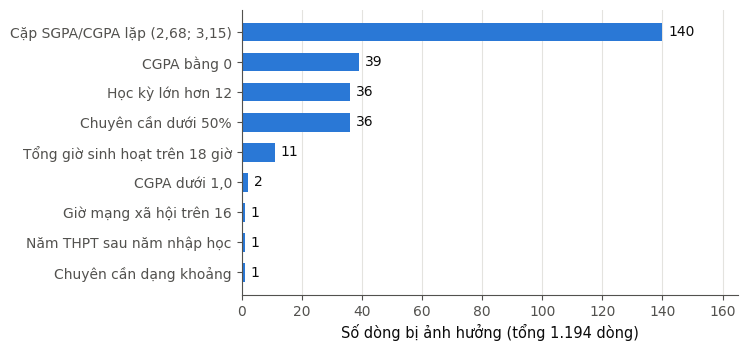

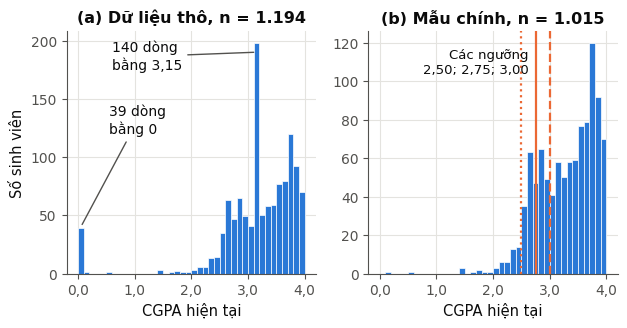

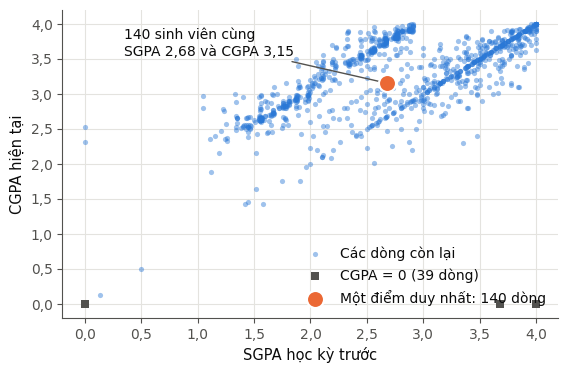

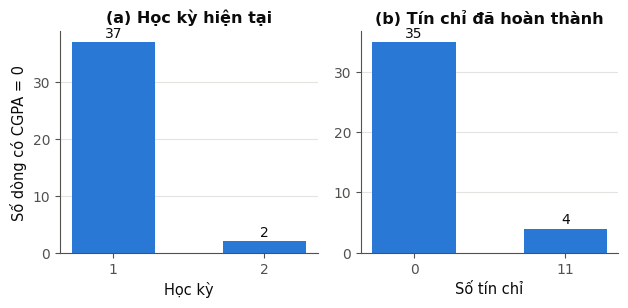

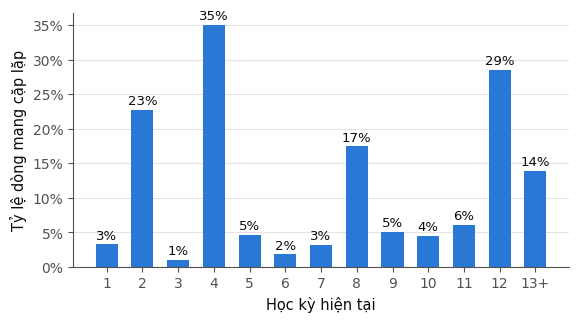

,Số dòng
"Cặp SGPA/CGPA lặp (2,68; 3,15)",140
CGPA bằng 0,39
Chuyên cần dưới 50%,36
Học kỳ lớn hơn 12,36
Tổng giờ sinh hoạt trên 18 giờ,11
Chuyên cần dạng khoảng,1
Năm THPT sau năm nhập học,1
Giờ mạng xã hội trên 16,1
"CGPA dưới 1,0",2


**t_descriptive_primary.csv**

,variable,n,mean,sd,median,q1,q3,min,max,skew
0,study_hours,1015,3.131,1.636,3.0,2.0,4.0,0.0,13.0,1.007
1,study_sessions,1015,1.943,0.851,2.0,1.0,2.0,0.0,7.0,1.021
2,attendance_pct,1015,87.712,15.915,90.0,80.0,100.0,0.0,100.0,-1.964
3,social_hours,1015,3.370,2.304,3.0,2.0,4.0,0.0,16.0,1.827
4,skill_hours,1015,2.216,1.306,2.0,1.0,3.0,0.0,12.0,1.536
5,semester_capped,1015,6.761,3.445,7.0,3.0,10.0,1.0,12.0,-0.137
6,credits_completed,1015,76.909,46.955,86.0,25.0,120.0,0.0,145.0,-0.133
7,english_level,1015,0.956,0.667,1.0,1.0,1.0,0.0,2.0,0.050


**t_placeholder_vs_rest.csv**

,variable,median_placeholder,median_other,p_mannwhitney,p_holm
0,study_hours,3.0,3.0,0.715,1.000
1,study_sessions,2.0,2.0,0.906,1.000
2,attendance_pct,90.0,90.0,0.827,1.000
3,social_hours,2.0,3.0,0.000,0.002
4,skill_hours,2.0,2.0,0.783,1.000
5,english_level,1.0,1.0,0.002,0.021
6,has_pc,1.0,1.0,0.093,0.648
7,cocurricular,0.0,0.0,0.155,0.930
8,learning_mode_online,0.0,0.0,0.425,1.000
9,uses_transport,1.0,0.0,0.005,0.038


**t_composition_shift.csv**

,variable,category,share_all_1194,share_primary_1015
0,semester_band,Học kỳ 1-4,0.376,0.327
1,semester_band,Học kỳ từ 9,0.344,0.375
2,semester_band,Học kỳ 5-8,0.280,0.298
3,cohort_band,>=2022,0.276,0.242
4,cohort_band,2021,0.275,0.290
5,cohort_band,2020,0.237,0.251
6,cohort_band,2019,0.150,0.159
7,cohort_band,<=2018,0.062,0.058


In [23]:
part_a_quality()
display(pd.Series(R["flags"], name="Số dòng").to_frame())
display(Markdown("**t_descriptive_primary.csv**"))
display(pd.read_csv(TAB / "t_descriptive_primary.csv").round(3))
display(Markdown("**t_placeholder_vs_rest.csv**"))
display(pd.read_csv(TAB / "t_placeholder_vs_rest.csv").round(3))
display(Markdown("**t_composition_shift.csv**"))
display(pd.read_csv(TAB / "t_composition_shift.csv").round(3))

#### A6.4. Phần B: AQ1, phân bố CGPA và tỷ lệ nhóm cần hỗ trợ

AQ1 (Descriptive) hỏi phân bố CGPA ra sao và bao nhiêu sinh viên thuộc nhóm cần hỗ trợ ở ba ngưỡng ứng viên. Tỷ lệ được tính trên hai mẫu (mẫu chính và mẫu độ nhạy B) với khoảng tin cậy Wilson, sau đó phân tích theo khóa nhập học (kiểm định chi bình phương) và theo nhóm học kỳ (Kruskal-Wallis) để kiểm tra tính đại diện.

In [24]:
def part_b_aq1() -> None:
    rows = []
    for name, thr in [("y_lt_2_50", 2.50), ("y_lt_2_75", 2.75), ("y_lt_3_00", 3.00)]:
        for label, d in [("Mẫu chính (n = 1.015)", prim), ("Mẫu độ nhạy B (n = 1.155)", sensB)]:
            k, n = int(d[name].astype(int).sum()), len(d)
            lo, hi = wilson(k, n)
            rows.append({"threshold": thr, "sample": label, "positives": k, "n": n, "rate": k / n, "ci_low": lo, "ci_high": hi})
    t = pd.DataFrame(rows)
    t.to_csv(TAB / "t_aq1_prevalence.csv", index=False)
    R["aq1_prevalence"] = rows

    fig, ax = plt.subplots(figsize=(6.4, 3.8))
    w = 0.36
    x = np.arange(3)
    for j, (label, color) in enumerate([("Mẫu chính (n = 1.015)", BLUE), ("Mẫu độ nhạy B (n = 1.155)", BLUE_LIGHT)]):
        s = t[t["sample"] == label]
        r = s["rate"].to_numpy() * 100
        err = np.vstack([r - s["ci_low"].to_numpy() * 100, s["ci_high"].to_numpy() * 100 - r])
        bars = ax.bar(x + (j - 0.5) * w, r, w, color=color, edgecolor=BLUE if j else "none", linewidth=1, label=label, yerr=err,
                      error_kw=dict(ecolor=INK2, lw=1.2, capsize=3))
        for xi, rr, kk in zip(x + (j - 0.5) * w, r, s["positives"]):
            ax.text(xi, rr + 3.1, f"{vi(rr, 1)}%\n({kk})", ha="center", fontsize=9.5)
    ax.axhspan(10, 25, color=MID, zorder=0)
    ax.axhline(30, color=ORANGE, lw=1.4, ls="--")
    ax.set_xticks(x)
    ax.set_xticklabels(["CGPA < 2,50", "CGPA < 2,75", "CGPA < 3,00"])
    ax.set_ylabel("Tỷ lệ ca dương")
    ax.set_ylim(0, 41)
    ax.yaxis.set_major_formatter(pct_axis())
    ax.grid(axis="x", visible=False)
    h, _ = ax.get_legend_handles_labels()
    h += [plt.Rectangle((0, 0), 1, 1, fc=MID, ec="none"), plt.Line2D([0], [0], color=ORANGE, lw=1.4, ls="--")]
    ax.legend(handles=h, labels=["Mẫu chính (n = 1.015)", "Mẫu độ nhạy B (n = 1.155)",
                                 "Khoảng 10-25% theo Đề cương", "Trần gắn cờ 30%"],
              loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=9.5)
    save(fig, "fig06_target_prevalence.png")

    # Đại diện theo khóa nhập học và tỷ lệ ca dương theo khóa
    fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.5), gridspec_kw={"width_ratios": [1.15, 1]})
    yr = raw_typed["admit_year"].value_counts().sort_index()
    axes[0].bar(yr.index.astype(str), yr.values, color=BLUE, width=0.7)
    for xi, v in zip(range(len(yr)), yr.values):
        axes[0].text(xi, v + 5, str(v), ha="center", fontsize=8.8, rotation=0)
    axes[0].set_title("(a) Số sinh viên theo năm nhập học")
    axes[0].set_xlabel("Năm nhập học")
    axes[0].tick_params(axis="x", labelrotation=60)
    axes[0].grid(axis="x", visible=False)
    order = ["<=2018", "2019", "2020", "2021", ">=2022"]
    rows = []
    for k in order:
        g = prim[prim["cohort_band"] == k]
        kk, nn = int(g["y"].sum()), len(g)
        lo, hi = wilson(kk, nn)
        rows.append({"cohort": k, "n": nn, "positives": kk, "rate": kk / nn, "lo": lo, "hi": hi})
    ct = pd.DataFrame(rows)
    ct.to_csv(TAB / "t_aq1_by_cohort.csv", index=False)
    err = np.vstack([ct["rate"] - ct["lo"], ct["hi"] - ct["rate"]]) * 100
    axes[1].bar(order, ct["rate"] * 100, color=BLUE, width=0.62, yerr=err, error_kw=dict(ecolor=INK2, lw=1.2, capsize=3))
    for i, (r, n) in enumerate(zip(ct["rate"], ct["n"])):
        axes[1].text(i, r * 100 + 5.5, f"n={n}", ha="center", fontsize=8.8)
    axes[1].set_title("(b) Tỷ lệ CGPA < 2,75")
    axes[1].set_xlabel("Khóa nhập học")
    axes[1].yaxis.set_major_formatter(pct_axis())
    axes[1].set_ylim(0, 45)
    axes[1].tick_params(axis="x", labelrotation=30)
    axes[1].grid(axis="x", visible=False)
    fig.tight_layout()
    save(fig, "fig07_cohort_representativeness.png")
    R["aq1_by_cohort"] = rows
    chi = stats.chi2_contingency(pd.crosstab(prim["cohort_band"], prim["y"]))
    R["aq1_cohort_chi2"] = {"chi2": float(chi[0]), "p": float(chi[1]), "dof": int(chi[2])}

    # CGPA trung vị theo nhóm học kỳ
    by_sem = prim.groupby("semester_band")["cgpa_clean"].agg(["median", "mean", "size"]).reset_index()
    by_sem.to_csv(TAB / "t_aq1_by_semband.csv", index=False)
    R["aq1_by_semband"] = by_sem.to_dict(orient="records")
    kw = stats.kruskal(*[g["cgpa_clean"].to_numpy() for _, g in prim.groupby("semester_band")])
    R["aq1_semband_kruskal"] = {"H": float(kw[0]), "p": float(kw[1])}

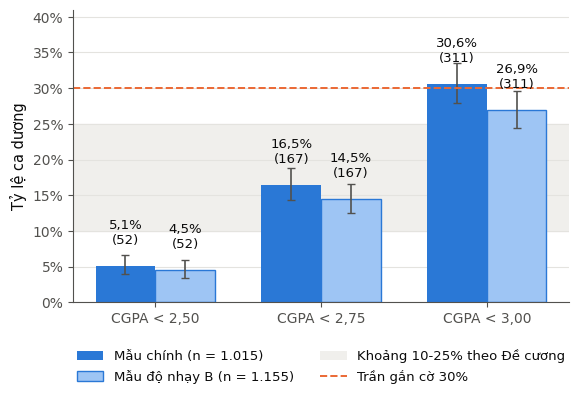

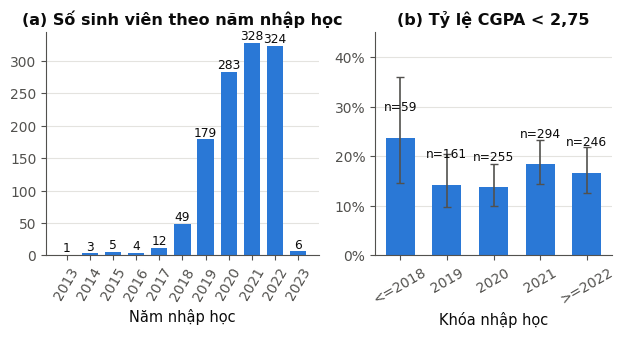

**t_aq1_prevalence.csv**

,threshold,sample,positives,n,rate,ci_low,ci_high
0,2.50,Mẫu chính (n = 1.015),52,1015,0.051,0.039,0.067
1,2.50,Mẫu độ nhạy B (n = 1.155),52,1155,0.045,0.034,0.059
2,2.75,Mẫu chính (n = 1.015),167,1015,0.165,0.143,0.189
3,2.75,Mẫu độ nhạy B (n = 1.155),167,1155,0.145,0.125,0.166
4,3.00,Mẫu chính (n = 1.015),311,1015,0.306,0.279,0.335
5,3.00,Mẫu độ nhạy B (n = 1.155),311,1155,0.269,0.244,0.296


**t_aq1_by_cohort.csv**

,cohort,n,positives,rate,lo,hi
0,<=2018,59,14,0.237,0.147,0.360
1,2019,161,23,0.143,0.097,0.205
2,2020,255,35,0.137,0.100,0.185
3,2021,294,54,0.184,0.144,0.232
4,>=2022,246,41,0.167,0.125,0.218


**t_aq1_by_semband.csv**

,semester_band,median,mean,size
0,Học kỳ 1-4,3.460,3.332,332
1,Học kỳ 5-8,3.345,3.255,302
2,Học kỳ từ 9,3.380,3.280,381


In [25]:
part_b_aq1()
display(Markdown("**t_aq1_prevalence.csv**"))
display(pd.read_csv(TAB / "t_aq1_prevalence.csv").round(3))
display(Markdown("**t_aq1_by_cohort.csv**"))
display(pd.read_csv(TAB / "t_aq1_by_cohort.csv").round(3))
display(Markdown("**t_aq1_by_semband.csv**"))
display(pd.read_csv(TAB / "t_aq1_by_semband.csv").round(3))

#### A6.5. Phần C: AQ2, thói quen học tập

AQ2 (Diagnostic) hỏi năm biến thói quen khác biệt thế nào giữa nhóm cần hỗ trợ và nhóm còn lại. Với mỗi biến, notebook tính trung vị và khoảng tứ phân vị theo nhóm, PS kèm khoảng tin cậy bootstrap, p của Mann-Whitney hiệu chỉnh Holm và tương quan Spearman với CGPA. Chuyên cần được phân tích sâu hơn: tỷ lệ cần hỗ trợ theo dải chuyên cần (kiểm tra xu hướng), phân tầng theo nhóm học kỳ để loại trừ nhiễu, và ma trận chuyên cần × giờ học để phát hiện quan hệ phi tuyến hoặc tương tác.

In [26]:
def part_c_aq2() -> None:
    d1 = prim[prim["y"] == 1]
    d0 = prim[prim["y"] == 0]
    rows = []
    for v in CORE_AQ2:
        x1, x0 = d1[v].dropna().to_numpy(float), d0[v].dropna().to_numpy(float)
        ps = prob_superiority(x1, x0)
        lo, hi = ps_bootstrap_ci(x1, x0)
        p = float(stats.mannwhitneyu(x1, x0, alternative="two-sided")[1])
        rho, pr = stats.spearmanr(prim[v], prim["cgpa_clean"])
        rows.append({"variable": v, "median_support": float(np.median(x1)), "q1_support": float(np.percentile(x1, 25)),
                     "q3_support": float(np.percentile(x1, 75)), "median_rest": float(np.median(x0)),
                     "q1_rest": float(np.percentile(x0, 25)), "q3_rest": float(np.percentile(x0, 75)),
                     "ps": ps, "ps_lo": lo, "ps_hi": hi, "p": p, "spearman_rho": float(rho), "spearman_p": float(pr)})
    t = pd.DataFrame(rows)
    t["p_holm"] = holm(t["p"].tolist())
    t.to_csv(TAB / "t_aq2_numeric.csv", index=False)
    R["aq2"] = t.to_dict(orient="records")

    # Hình box theo nhóm
    fig, axes = plt.subplots(1, 5, figsize=(6.4, 3.6))
    for ax, v in zip(axes, CORE_AQ2):
        bp = ax.boxplot([d1[v].dropna(), d0[v].dropna()], widths=0.62, patch_artist=True, showfliers=True,
                        medianprops=dict(color=INK, lw=1.6), flierprops=dict(marker="o", markersize=2.5, markerfacecolor=INK2, markeredgewidth=0, alpha=.5),
                        whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
        for patch, c in zip(bp["boxes"], [ORANGE, BLUE]):
            patch.set_facecolor(c)
            patch.set_alpha(0.85)
            patch.set_edgecolor(INK2)
        row = t[t["variable"] == v].iloc[0]
        wrap = {"study_hours": "Giờ học", "study_sessions": "Số lần\nngồi học", "attendance_pct": "Chuyên cần",
                "social_hours": "Giờ dùng\nmạng xã hội", "skill_hours": "Giờ phát\ntriển kỹ năng"}
        ax.set_title(wrap.get(v, LABELS[v]), fontsize=9.3, pad=6)
        ax.set_xticks([1, 2])
        ax.set_xticklabels(["A", "B"])
        ax.set_xlabel(f"PS={vi(row['ps'], 2)}", fontsize=9.2)
        ax.grid(axis="x", visible=False)
        ax.tick_params(axis="y", labelsize=9)
    axes[0].set_ylabel("Giá trị khai báo")
    fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=ORANGE, ec=INK2), plt.Rectangle((0, 0), 1, 1, fc=BLUE, ec=INK2)],
               labels=["A: " + G_SUPPORT, "B: " + G_REST], loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.06))
    fig.tight_layout()
    save(fig, "fig08_aq2_distributions.png")

    # Chuyên cần theo dải và phân tầng theo nhóm học kỳ
    bins = [-1, 69.99, 79.99, 89.99, 94.99, 100]
    labs = ["< 70", "70-79", "80-89", "90-94", "95-100"]
    prim["att_bin"] = pd.cut(prim["attendance_pct"], bins=bins, labels=labs)
    rows = []
    for k in labs:
        g = prim[prim["att_bin"] == k]
        kk, nn = int(g["y"].sum()), len(g)
        lo, hi = wilson(kk, nn)
        rows.append({"att_bin": k, "n": nn, "positives": kk, "rate": kk / nn, "lo": lo, "hi": hi})
    ab = pd.DataFrame(rows)
    ab.to_csv(TAB / "t_aq2_attendance_bins.csv", index=False)
    R["aq2_att_bins"] = rows
    trend = stats.spearmanr(prim["attendance_pct"], prim["y"])
    R["aq2_att_trend"] = {"rho": float(trend[0]), "p": float(trend[1])}

    fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.5), gridspec_kw={"width_ratios": [1, 1.05]})
    err = np.vstack([ab["rate"] - ab["lo"], ab["hi"] - ab["rate"]]) * 100
    axes[0].bar(labs, ab["rate"] * 100, color=BLUE, width=0.64, yerr=err, error_kw=dict(ecolor=INK2, lw=1.2, capsize=3))
    for i, (r, n) in enumerate(zip(ab["rate"], ab["n"])):
        axes[0].text(i, r * 100 + 6.2, f"n={n}", ha="center", fontsize=8.8)
    axes[0].set_title("(a) Tỷ lệ CGPA < 2,75")
    axes[0].set_xlabel("Chuyên cần (%)")
    axes[0].yaxis.set_major_formatter(pct_axis())
    axes[0].set_ylim(0, 62)
    axes[0].tick_params(axis="x", labelsize=9)
    axes[0].grid(axis="x", visible=False)
    strat_rows = []
    sem_order = ["Học kỳ 1-4", "Học kỳ 5-8", "Học kỳ từ 9"]
    markers = ["o", "s", "D"]
    cols = [BLUE_LIGHT, BLUE, BLUE_DARK]
    for (sb, mk, cl) in zip(sem_order, markers, cols):
        g = prim[prim["semester_band"] == sb]
        rr = []
        for k in labs:
            gg = g[g["att_bin"] == k]
            rr.append(gg["y"].mean() * 100 if len(gg) >= 10 else np.nan)
            strat_rows.append({"semester_band": sb, "att_bin": k, "n": len(gg), "positives": int(gg["y"].sum()),
                               "rate": gg["y"].mean() if len(gg) else np.nan})
        axes[1].plot(labs, rr, marker=mk, color=cl, lw=2, markersize=6.5, label=sb, markeredgecolor="white")
    pd.DataFrame(strat_rows).to_csv(TAB / "t_aq2_attendance_by_semband.csv", index=False)
    axes[1].set_title("(b) Phân tầng theo học kỳ")
    axes[1].set_xlabel("Chuyên cần (%)")
    axes[1].yaxis.set_major_formatter(pct_axis())
    axes[1].tick_params(axis="x", labelsize=9)
    axes[1].legend(frameon=False, fontsize=9, loc="upper right")
    axes[1].grid(axis="x", visible=False)
    fig.tight_layout()
    save(fig, "fig10_aq2_attendance_deepdive.png")
    strat_ps = {}
    for sb in sem_order:
        g = prim[prim["semester_band"] == sb]
        a, b = g.loc[g["y"] == 1, "attendance_pct"].to_numpy(float), g.loc[g["y"] == 0, "attendance_pct"].to_numpy(float)
        strat_ps[sb] = {"n": int(len(g)), "pos": int(len(a)), "ps": prob_superiority(a, b), "p": float(stats.mannwhitneyu(a, b)[1])}
    R["aq2_attendance_strat"] = strat_ps

    # Giờ học theo nhóm kết hợp: ma trận chuyên cần x giờ học (phi tuyến, tương tác)
    prim["study_bin"] = pd.cut(prim["study_hours"], bins=[-1, 1, 2, 3, 4, 20], labels=["0-1", "2", "3", "4", "5+"])
    prim["att_bin2"] = pd.cut(prim["attendance_pct"], bins=[-1, 79.99, 89.99, 100], labels=["< 80", "80-89", "90-100"])
    mat = prim.pivot_table(index="att_bin2", columns="study_bin", values="y", aggfunc="mean", observed=False) * 100
    cnt = prim.pivot_table(index="att_bin2", columns="study_bin", values="y", aggfunc="size", observed=False)
    mat.to_csv(TAB / "t_aq2_att_study_matrix.csv")
    cnt.to_csv(TAB / "t_aq2_att_study_counts.csv")
    R["aq2_matrix"] = {"rate": mat.round(1).to_dict(), "n": cnt.to_dict()}

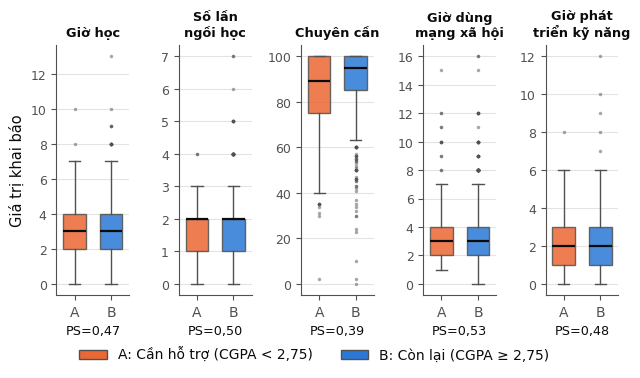

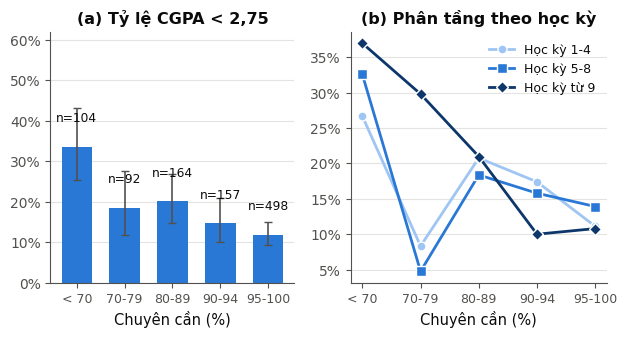

**t_aq2_numeric.csv**

,variable,median_support,q1_support,q3_support,median_rest,q1_rest,q3_rest,ps,ps_lo,ps_hi,p,spearman_rho,spearman_p,p_holm
0,study_hours,3.0,2.0,4.0,3.0,2.0,4.0,0.470,0.426,0.516,0.204,0.043,0.169,0.675
1,study_sessions,2.0,1.0,2.0,2.0,1.0,2.0,0.502,0.457,0.546,0.924,0.038,0.229,0.924
2,attendance_pct,89.0,75.0,100.0,95.0,85.0,100.0,0.395,0.347,0.442,0.000,0.264,0.000,0.000
3,social_hours,3.0,2.0,4.0,3.0,2.0,4.0,0.533,0.488,0.577,0.169,-0.115,0.000,0.675
4,skill_hours,2.0,1.0,3.0,2.0,1.0,3.0,0.480,0.431,0.528,0.393,0.023,0.461,0.787


**t_aq2_attendance_bins.csv**

,att_bin,n,positives,rate,lo,hi
0,< 70,104,35,0.337,0.253,0.432
1,70-79,92,17,0.185,0.119,0.276
2,80-89,164,33,0.201,0.147,0.269
3,90-94,157,23,0.146,0.100,0.210
4,95-100,498,59,0.118,0.093,0.150


**t_aq2_attendance_by_semband.csv**

,semester_band,att_bin,n,positives,rate
0,Học kỳ 1-4,< 70,15,4,0.267
1,Học kỳ 1-4,70-79,24,2,0.083
2,Học kỳ 1-4,80-89,53,11,0.208
3,Học kỳ 1-4,90-94,69,12,0.174
4,Học kỳ 1-4,95-100,171,19,0.111
5,Học kỳ 5-8,< 70,43,14,0.326
6,Học kỳ 5-8,70-79,21,1,0.048
7,Học kỳ 5-8,80-89,49,9,0.184
8,Học kỳ 5-8,90-94,38,6,0.158
9,Học kỳ 5-8,95-100,151,21,0.139


**t_aq2_att_study_matrix.csv**

,att_bin2,0-1,2,3,4,5+
0,< 80,21.622,31.667,21.154,23.529,33.333
1,80-89,17.857,17.647,26.471,20.690,18.182
2,90-100,12.500,14.557,14.689,11.215,8.511


In [27]:
part_c_aq2()
display(Markdown("**t_aq2_numeric.csv**"))
display(pd.read_csv(TAB / "t_aq2_numeric.csv").round(3))
display(Markdown("**t_aq2_attendance_bins.csv**"))
display(pd.read_csv(TAB / "t_aq2_attendance_bins.csv").round(3))
display(Markdown("**t_aq2_attendance_by_semband.csv**"))
display(pd.read_csv(TAB / "t_aq2_attendance_by_semband.csv").round(3))
display(Markdown("**t_aq2_att_study_matrix.csv**"))
display(pd.read_csv(TAB / "t_aq2_att_study_matrix.csv").round(3))

#### A6.6. Phần D: AQ3, điều kiện và bối cảnh học tập

AQ3 (Diagnostic) hỏi điều kiện và bối cảnh học tập liên hệ ra sao với nhãn. Biến số và thứ bậc dùng PS như AQ2; biến nhị phân dùng tỷ lệ theo nhóm, OR thô và OR hiệu chỉnh theo nhóm học kỳ (Mantel-Haenszel). Trình độ tiếng Anh được so sánh từng mức với mức Intermediate vì quan hệ không đơn điệu, kèm kiểm định chi bình phương và Cramér's V. Ma trận tương quan Spearman giữa các biến lõi được dùng để phát hiện đa cộng tuyến, đặc biệt giữa học kỳ và số tín chỉ.

In [28]:
def part_d_aq3() -> None:
    d1 = prim[prim["y"] == 1]
    d0 = prim[prim["y"] == 0]
    rows = []
    for v in ["english_level", "semester_capped", "credits_completed", "credits_per_semester"]:
        x1, x0 = d1[v].dropna().to_numpy(float), d0[v].dropna().to_numpy(float)
        ps = prob_superiority(x1, x0)
        lo, hi = ps_bootstrap_ci(x1, x0)
        p = float(stats.mannwhitneyu(x1, x0)[1])
        rho, pr = stats.spearmanr(prim[v], prim["cgpa_clean"], nan_policy="omit")
        rows.append({"variable": v, "median_support": float(np.median(x1)), "median_rest": float(np.median(x0)),
                     "ps": ps, "ps_lo": lo, "ps_hi": hi, "p": p, "spearman_rho": float(rho), "spearman_p": float(pr)})
    tn = pd.DataFrame(rows)
    tn["p_holm"] = holm(tn["p"].tolist())

    # Biến nhị phân: tỷ lệ, OR thô, OR hiệu chỉnh theo nhóm học kỳ
    bin_rows = []
    for v in ["learning_mode_online", "has_pc", "uses_transport", "cocurricular", "has_smartphone"]:
        a = int(((prim[v] == 1) & (prim["y"] == 1)).sum())
        b = int(((prim[v] == 1) & (prim["y"] == 0)).sum())
        c = int(((prim[v] == 0) & (prim["y"] == 1)).sum())
        d = int(((prim[v] == 0) & (prim["y"] == 0)).sum())
        orr, lo, hi = odds_ratio(a, b, c, d)
        mh, mlo, mhi = mantel_haenszel(prim, v, "y", "semester_band")
        p = float(stats.fisher_exact([[a, b], [c, d]])[1])
        bin_rows.append({"variable": v, "n_yes": a + b, "rate_yes": a / (a + b), "n_no": c + d, "rate_no": c / (c + d),
                         "or_crude": orr, "or_lo": lo, "or_hi": hi, "or_mh": mh, "mh_lo": mlo, "mh_hi": mhi,
                         "p_fisher": p, "cramers_v": cramers_v(np.array([[a, b], [c, d]]))})
    # Tiếng Anh: đối chiếu từng mức với Intermediate (quan hệ không đơn điệu)
    for name, lvl in [("english_basic_vs_inter", 0), ("english_adv_vs_inter", 2)]:
        sub = prim[prim["english_level"].isin([1, lvl])].copy()
        sub["exp"] = (sub["english_level"] == lvl).astype(int)
        a = int(((sub["exp"] == 1) & (sub["y"] == 1)).sum()); b = int(((sub["exp"] == 1) & (sub["y"] == 0)).sum())
        c = int(((sub["exp"] == 0) & (sub["y"] == 1)).sum()); d = int(((sub["exp"] == 0) & (sub["y"] == 0)).sum())
        orr, lo, hi = odds_ratio(a, b, c, d)
        mh, mlo, mhi = mantel_haenszel(sub, "exp", "y", "semester_band")
        bin_rows.append({"variable": name, "n_yes": a + b, "rate_yes": a / (a + b), "n_no": c + d, "rate_no": c / (c + d),
                         "or_crude": orr, "or_lo": lo, "or_hi": hi, "or_mh": mh, "mh_lo": mlo, "mh_hi": mhi,
                         "p_fisher": float(stats.fisher_exact([[a, b], [c, d]])[1]),
                         "cramers_v": cramers_v(np.array([[a, b], [c, d]]))})
    tb = pd.DataFrame(bin_rows)
    main_family = tb["variable"] != "has_smartphone"
    tb["p_holm"] = np.nan
    tb.loc[main_family, "p_holm"] = holm(tb.loc[main_family, "p_fisher"].tolist())
    tn.to_csv(TAB / "t_aq3_numeric.csv", index=False)
    tb.to_csv(TAB / "t_aq3_binary.csv", index=False)
    R["aq3_numeric"] = tn.to_dict(orient="records")
    R["aq3_binary"] = tb.to_dict(orient="records")
    ct = pd.crosstab(prim["english_level"], prim["y"])
    R["aq3_english"] = {"chi2_p": float(stats.chi2_contingency(ct)[1]), "v": cramers_v(ct.to_numpy()),
                        "rates": (ct[1] / ct.sum(axis=1)).to_dict(), "n": ct.sum(axis=1).to_dict()}
    ctb = pd.crosstab(prim["semester_band"], prim["y"])
    R["aq3_semband"] = {"chi2_p": float(stats.chi2_contingency(ctb)[1]), "v": cramers_v(ctb.to_numpy()),
                        "rates": (ctb[1] / ctb.sum(axis=1)).to_dict(), "n": ctb.sum(axis=1).to_dict()}

    # Hình 11: tỷ lệ ca dương theo hạng mục (2 x 4)
    panels = [("learning_mode_online", ["Offline", "Online"], "Hình thức\nhọc ưa thích"),
              ("has_pc", ["Không", "Có"], "Máy tính\ncá nhân"),
              ("uses_transport", ["Không", "Có"], "Xe đưa đón\ncủa trường"),
              ("cocurricular", ["Không", "Có"], "Hoạt động\nngoại khóa"),
              ("english_level", ["Cơ bản", "Trung bình", "Nâng cao"], "Trình độ\ntiếng Anh"),
              ("semester_band", ["Học kỳ 1-4", "Học kỳ 5-8", "Học kỳ từ 9"], "Nhóm\nhọc kỳ"),
              ("has_smartphone", ["Không", "Có"], "Điện thoại\nthông minh"),
              ("consultancy_bin", ["Không", "Có"], "Đã tham gia\ntư vấn")]
    fig, axes = plt.subplots(2, 4, figsize=(6.4, 5.0), sharey=True)
    for ax, (v, cats, title) in zip(axes.ravel(), panels):
        keys = cats if v == "semester_band" else list(range(len(cats)))
        rr, los, his, ns = [], [], [], []
        for k in keys:
            g = prim[prim[v] == k]
            kk, nn = int(g["y"].sum()), len(g)
            lo, hi = wilson(kk, nn)
            rr.append(kk / nn * 100); los.append(lo * 100); his.append(hi * 100); ns.append(nn)
        err = np.vstack([np.array(rr) - np.array(los), np.array(his) - np.array(rr)])
        color = INK2 if v in ("consultancy_bin", "has_smartphone") else BLUE
        ax.bar(range(len(cats)), rr, color=color, width=0.62, yerr=err, error_kw=dict(ecolor=INK, lw=1.1, capsize=2.5))
        for i, (r, n, h) in enumerate(zip(rr, ns, his)):
            ax.text(i, h + 1.0, f"n={n}", ha="center", fontsize=7.6, rotation=90, va="bottom")
        ax.set_title(title, fontsize=8.8, pad=5)
        ax.set_xticks(range(len(cats)))
        ax.set_xticklabels([c.replace("Học kỳ ", "HK ").replace("Trung bình", "T.bình").replace("Nâng cao", "N.cao") for c in cats], fontsize=8.2, rotation=0)
        ax.set_ylim(0, 62)
        ax.grid(axis="x", visible=False)
        ax.yaxis.set_major_formatter(pct_axis())
        ax.tick_params(axis="y", labelsize=8.8)
    for ax in axes[:, 1:].ravel():
        ax.tick_params(axis="y", labelleft=False)
    axes[0, 0].set_ylabel("Tỷ lệ CGPA < 2,75")
    axes[1, 0].set_ylabel("Tỷ lệ CGPA < 2,75")
    fig.tight_layout(h_pad=1.6)
    save(fig, "fig11_aq3_categorical.png")

    # Hình 9: forest PS cho AQ2 và AQ3 (biến số/thứ bậc)
    ta2 = pd.DataFrame(R["aq2"])
    fr = pd.concat([ta2[["variable", "ps", "ps_lo", "ps_hi", "p_holm"]].assign(group="AQ2"),
                    tn[["variable", "ps", "ps_lo", "ps_hi", "p_holm"]].assign(group="AQ3")], ignore_index=True)
    fr.to_csv(TAB / "t_forest_ps.csv", index=False)
    fig, ax = plt.subplots(figsize=(6.4, 3.9))
    y = np.arange(len(fr))[::-1]
    for yi, row in zip(y, fr.itertuples()):
        c = BLUE if row.group == "AQ2" else BLUE_DARK
        ax.plot([row.ps_lo, row.ps_hi], [yi, yi], color=c, lw=2)
        ax.scatter([row.ps], [yi], color=c, s=55, zorder=5, marker="o" if row.group == "AQ2" else "D", edgecolor="white", linewidths=1)
        sig = "*" if row.p_holm < 0.05 else ""
        ax.text(0.745, yi, f"{vi(row.ps, 2)}{sig}", va="center", fontsize=9.8)
    ax.axvline(0.5, color=ORANGE, lw=1.4, ls="--")
    ax.set_yticks(y)
    ax.set_yticklabels([LABELS[v] for v in fr["variable"]], fontsize=9.6)
    ax.set_xlim(0.30, 0.80)
    ax.set_xlabel("Xác suất ưu thế PS (0,5 = không khác biệt; nhỏ hơn 0,5 = nhóm cần hỗ trợ có giá trị thấp hơn)", fontsize=8.6)
    ax.xaxis.set_major_formatter(vi_axis(1))
    ax.grid(axis="y", visible=False)
    ax.legend(handles=[plt.Line2D([0], [0], marker="o", color=BLUE, lw=2, label="AQ2: thói quen học tập"),
                       plt.Line2D([0], [0], marker="D", color=BLUE_DARK, lw=2, label="AQ3: điều kiện và bối cảnh")],
              loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False, fontsize=9.2)
    save(fig, "fig09_forest_probability_of_superiority.png")

    # Hình 12: OR thô và OR hiệu chỉnh
    ob = tb[tb["variable"].isin(["learning_mode_online", "has_pc", "uses_transport", "cocurricular",
                                  "english_basic_vs_inter", "english_adv_vs_inter"])].copy()
    names = {"learning_mode_online": "Ưa thích học trực tuyến", "has_pc": "Có máy tính cá nhân",
             "uses_transport": "Dùng xe đưa đón", "cocurricular": "Hoạt động ngoại khóa",
             "english_basic_vs_inter": "Tiếng Anh Cơ bản (so với T.bình)",
             "english_adv_vs_inter": "Tiếng Anh Nâng cao (so với T.bình)"}
    fig, ax = plt.subplots(figsize=(6.4, 3.7))
    y = np.arange(len(ob))[::-1]
    for yi, row in zip(y, ob.itertuples()):
        ax.plot([row.or_lo, row.or_hi], [yi + 0.14, yi + 0.14], color=BLUE, lw=2)
        ax.scatter([row.or_crude], [yi + 0.14], color=BLUE, s=48, zorder=5, edgecolor="white", linewidths=1)
        ax.plot([row.mh_lo, row.mh_hi], [yi - 0.14, yi - 0.14], color=BLUE_DARK, lw=2)
        ax.scatter([row.or_mh], [yi - 0.14], color=BLUE_DARK, s=48, zorder=5, marker="D", edgecolor="white", linewidths=1)
    ax.axvline(1, color=ORANGE, lw=1.4, ls="--")
    ax.set_xscale("log")
    ax.set_xlim(0.4, 3.8)
    ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3])
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.get_xaxis().set_major_formatter(FuncFormatter(lambda v, _: vi(v, 2).rstrip("0").rstrip(",") if v != 1 else "1"))
    ax.set_yticks(y)
    ax.set_yticklabels([names[v] for v in ob["variable"]])
    ax.set_xlabel("Tỷ số chênh (OR) của CGPA < 2,75, thang logarit")
    ax.grid(axis="y", visible=False)
    ax.legend(handles=[plt.Line2D([0], [0], marker="o", color=BLUE, lw=2, label="OR thô"),
                       plt.Line2D([0], [0], marker="D", color=BLUE_DARK, lw=2, label="OR hiệu chỉnh theo nhóm học kỳ (Mantel-Haenszel)")],
              loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1, frameon=False, fontsize=9)
    save(fig, "fig12_aq3_odds_ratios.png")

    # Hình 13: tương quan Spearman
    cols = ["cgpa_clean"] + CORE_FEATURES[:0] + CORE_AQ2 + ["english_level", "semester_capped", "credits_completed", "credits_per_semester",
                                                                  "learning_mode_online", "has_pc", "uses_transport", "cocurricular"]
    cols = list(dict.fromkeys(cols))
    cm = prim[cols].astype(float).corr(method="spearman")
    short = {"cgpa_clean": "CGPA", "study_hours": "Giờ học", "study_sessions": "Lần học", "attendance_pct": "Chuyên cần",
             "social_hours": "Mạng XH", "skill_hours": "Kỹ năng", "english_level": "Tiếng Anh", "semester_capped": "Học kỳ",
             "credits_completed": "Tín chỉ", "credits_per_semester": "Tín chỉ/HK", "learning_mode_online": "Học online",
             "has_pc": "Có PC", "uses_transport": "Xe đưa đón", "cocurricular": "Ngoại khóa"}
    from matplotlib.colors import LinearSegmentedColormap
    cmap = LinearSegmentedColormap.from_list("div", [ORANGE, MID, BLUE])
    fig, ax = plt.subplots(figsize=(6.4, 5.6))
    im = ax.imshow(cm.to_numpy(), cmap=cmap, vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)))
    ax.set_yticks(range(len(cols)))
    ax.set_xticklabels([short[c] for c in cols], rotation=50, ha="right", fontsize=9.3)
    ax.set_yticklabels([short[c] for c in cols], fontsize=9.3)
    for i in range(len(cols)):
        for j in range(len(cols)):
            v = cm.to_numpy()[i, j]
            if i != j and abs(v) >= 0.15:
                ax.text(j, i, vi(v, 2), ha="center", va="center", fontsize=7.4, color=INK)
    ax.grid(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    cb.ax.tick_params(labelsize=9)
    cb.outline.set_visible(False)
    save(fig, "fig13_spearman_heatmap.png")
    cm.to_csv(TAB / "t_spearman_matrix.csv")
    R["spearman_cgpa"] = cm["cgpa_clean"].drop("cgpa_clean").round(3).to_dict()
    R["spearman_pairs_strong"] = [
        {"a": a, "b": b, "rho": float(cm.loc[a, b])} for i, a in enumerate(cols) for b in cols[i + 1:] if abs(cm.loc[a, b]) >= 0.5 and a != "cgpa_clean"]

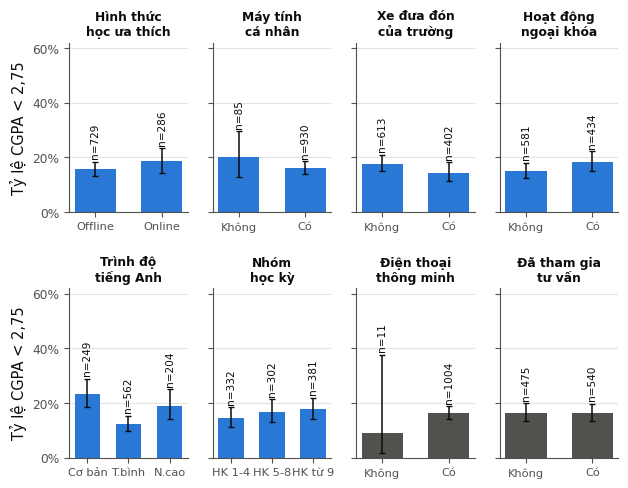

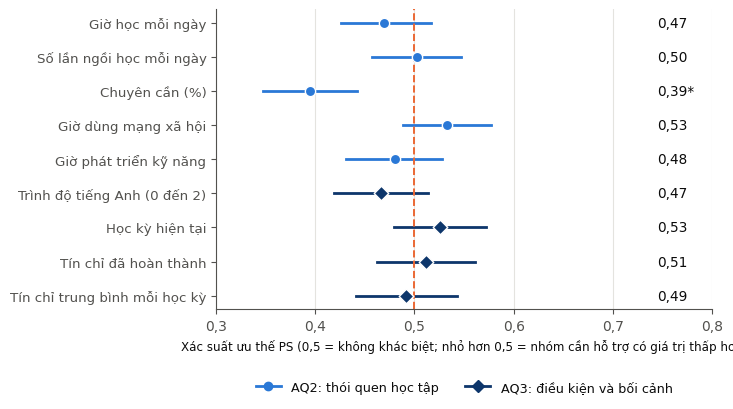

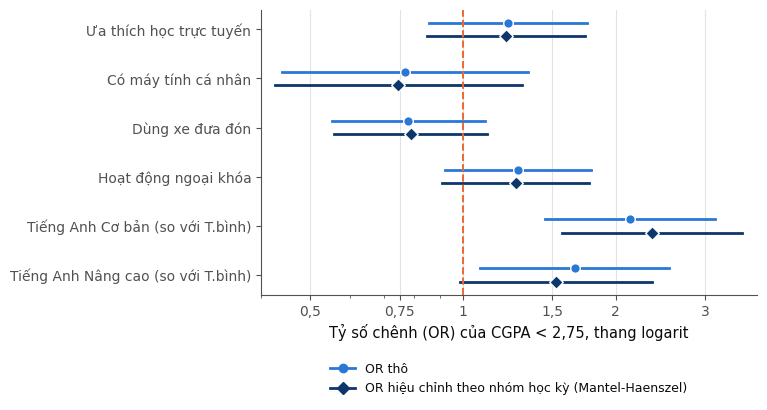

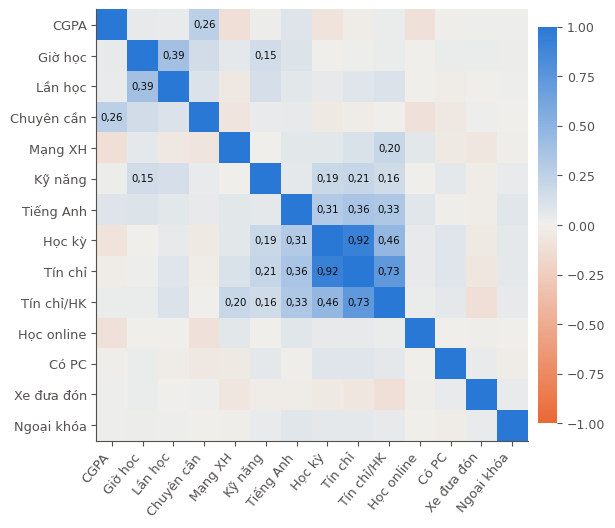

**t_aq3_numeric.csv**

,variable,median_support,median_rest,ps,ps_lo,ps_hi,p,spearman_rho,spearman_p,p_holm
0,english_level,1.000,1.0,0.466,0.418,0.513,0.121,0.091,0.004,0.484
1,semester_capped,7.000,7.0,0.526,0.479,0.572,0.286,-0.083,0.008,0.859
2,credits_completed,86.000,86.0,0.511,0.462,0.561,0.645,-0.029,0.352,1.000
3,credits_per_semester,10.875,11.0,0.492,0.441,0.543,0.741,0.024,0.443,1.000


**t_aq3_binary.csv**

,variable,n_yes,rate_yes,n_no,rate_no,or_crude,or_lo,or_hi,or_mh,mh_lo,mh_hi,p_fisher,cramers_v,p_holm
0,learning_mode_online,286,0.185,729,0.156,1.227,0.857,1.757,1.217,0.850,1.743,0.261,0.035,0.586
1,has_pc,930,0.161,85,0.200,0.769,0.440,1.346,0.746,0.425,1.308,0.360,0.029,0.586
2,uses_transport,402,0.144,613,0.178,0.780,0.551,1.103,0.789,0.557,1.117,0.167,0.044,0.586
3,cocurricular,434,0.184,581,0.150,1.283,0.920,1.790,1.270,0.909,1.773,0.147,0.046,0.586
4,has_smartphone,1004,0.165,11,0.091,1.981,0.252,15.579,1.995,0.252,15.801,1.000,0.021,NaN
5,english_basic_vs_inter,249,0.233,562,0.125,2.134,1.451,3.140,2.361,1.570,3.549,0.000,0.137,0.001
6,english_adv_vs_inter,204,0.191,562,0.125,1.661,1.081,2.553,1.528,0.988,2.362,0.026,0.084,0.129


**t_forest_ps.csv**

,variable,ps,ps_lo,ps_hi,p_holm,group
0,study_hours,0.470,0.426,0.516,0.675,AQ2
1,study_sessions,0.502,0.457,0.546,0.924,AQ2
2,attendance_pct,0.395,0.347,0.442,0.000,AQ2
3,social_hours,0.533,0.488,0.577,0.675,AQ2
4,skill_hours,0.480,0.431,0.528,0.787,AQ2
5,english_level,0.466,0.418,0.513,0.484,AQ3
6,semester_capped,0.526,0.479,0.572,0.859,AQ3
7,credits_completed,0.511,0.462,0.561,1.000,AQ3
8,credits_per_semester,0.492,0.441,0.543,1.000,AQ3


In [29]:
part_d_aq3()
display(Markdown("**t_aq3_numeric.csv**"))
display(pd.read_csv(TAB / "t_aq3_numeric.csv").round(3))
display(Markdown("**t_aq3_binary.csv**"))
display(pd.read_csv(TAB / "t_aq3_binary.csv").round(3))
display(Markdown("**t_forest_ps.csv**"))
display(pd.read_csv(TAB / "t_forest_ps.csv").round(3))

#### A6.7. Phần E: bằng chứng rò rỉ dữ liệu

Phần E định lượng lý do loại các biến rò rỉ khỏi tập đặc trưng. Cảnh cáo học vụ, đình chỉ, học bổng thành tích và việc đã tham gia tư vấn đều là hệ quả (hoặc có quan hệ ngược chiều) của kết quả học tập, nên có liên hệ rất mạnh với nhãn. SGPA kỳ trước là một thành phần cấu thành CGPA. Nếu đưa các biến này vào mô hình, hiệu năng đánh giá sẽ cao giả tạo và không phản ánh giá trị sàng lọc của phiếu khảo sát.

In [30]:
def part_e_leakage() -> None:
    rows = []
    for v, lab in [("probation_bin", "Từng bị cảnh cáo học vụ"), ("suspension_bin", "Từng bị đình chỉ"),
                   ("scholarship_bin", "Có học bổng thành tích"), ("consultancy_bin", "Đã tham gia tư vấn")]:
        a = int(((prim[v] == 1) & (prim["y"] == 1)).sum()); b = int(((prim[v] == 1) & (prim["y"] == 0)).sum())
        c = int(((prim[v] == 0) & (prim["y"] == 1)).sum()); d = int(((prim[v] == 0) & (prim["y"] == 0)).sum())
        orr, lo, hi = odds_ratio(a, b, c, d)
        rows.append({"variable": v, "label": lab, "n_yes": a + b, "rate_yes": a / (a + b), "rate_no": c / (c + d),
                     "or": orr, "or_lo": lo, "or_hi": hi, "p": float(stats.fisher_exact([[a, b], [c, d]])[1])})
    tl = pd.DataFrame(rows)
    tl.to_csv(TAB / "t_leakage_evidence.csv", index=False)
    s = prim[prim["prev_sgpa_clean"].notna()]
    rho, p = stats.spearmanr(s["prev_sgpa_clean"], s["cgpa_clean"])
    ps = prob_superiority(s.loc[s["y"] == 1, "prev_sgpa_clean"].to_numpy(float), s.loc[s["y"] == 0, "prev_sgpa_clean"].to_numpy(float))
    R["leakage"] = {"rows": rows, "sgpa_rho": float(rho), "sgpa_p": float(p), "sgpa_ps": ps, "sgpa_n": int(len(s))}

    fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.5), gridspec_kw={"width_ratios": [1.05, 1]})
    axes[0].scatter(s["prev_sgpa_clean"], s["cgpa_clean"], s=11, color=BLUE, alpha=0.4, linewidths=0)
    axes[0].set_xlabel("SGPA học kỳ trước")
    axes[0].set_ylabel("CGPA hiện tại")
    axes[0].set_title(f"(a) Spearman ρ = {vi(rho, 2)}")
    axes[0].xaxis.set_major_formatter(vi_axis(1))
    axes[0].yaxis.set_major_formatter(vi_axis(1))
    labs = [r["label"].replace("Từng bị ", "").replace("Có ", "").replace("Đã ", "") for r in rows]
    yy = np.arange(len(rows))[::-1]
    for yi, r in zip(yy, rows):
        axes[1].barh(yi + 0.17, r["rate_yes"] * 100, 0.32, color=ORANGE)
        axes[1].barh(yi - 0.17, r["rate_no"] * 100, 0.32, color=BLUE)
        axes[1].text(r["rate_yes"] * 100 + 1, yi + 0.17, f"{vi(r['rate_yes'] * 100, 0)}%", va="center", fontsize=9)
        axes[1].text(r["rate_no"] * 100 + 1, yi - 0.17, f"{vi(r['rate_no'] * 100, 0)}%", va="center", fontsize=9)
    axes[1].set_yticks(yy)
    axes[1].set_yticklabels(["Cảnh cáo\nhọc vụ", "Đình chỉ", "Học bổng", "Tư vấn"], fontsize=9.3)
    axes[1].set_xlabel("Tỷ lệ CGPA < 2,75")
    axes[1].set_xlim(0, 58)
    axes[1].set_title("(b) Có (cam) và không (xanh)", fontsize=10.8)
    axes[1].xaxis.set_major_formatter(pct_axis())
    axes[1].grid(axis="y", visible=False)
    fig.tight_layout()
    save(fig, "fig14_leakage_evidence.png")

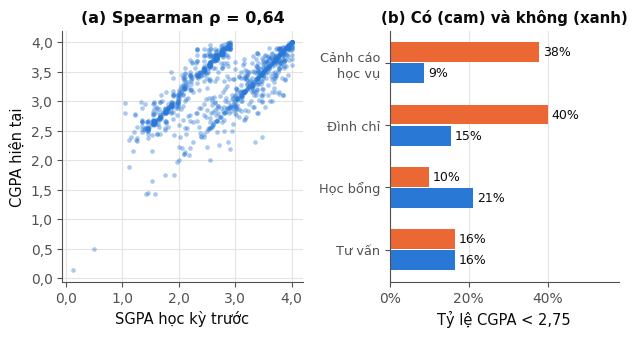

**t_leakage_evidence.csv**

,variable,label,n_yes,rate_yes,rate_no,or,or_lo,or_hi,p
0,probation_bin,Từng bị cảnh cáo học vụ,270,0.378,0.087,6.352,4.458,9.049,0.0
1,suspension_bin,Từng bị đình chỉ,40,0.400,0.155,3.638,1.888,7.010,0.0
2,scholarship_bin,Có học bổng thành tích,417,0.098,0.211,0.408,0.280,0.596,0.0
3,consultancy_bin,Đã tham gia tư vấn,540,0.165,0.164,1.004,0.720,1.401,1.0


In [31]:
part_e_leakage()
display(Markdown("**t_leakage_evidence.csv**"))
display(pd.read_csv(TAB / "t_leakage_evidence.csv").round(3))

#### A6.8. Phần F: mức sẵn sàng cho AQ4 đến AQ7

Phần F không huấn luyện mô hình mà kiểm tra điều kiện để mô hình hóa ở Milestone 4 có ý nghĩa:

* **AQ4:** tỷ lệ dương, số sự kiện trên mỗi tham số (EPV) và số ca dương mỗi fold.
* **AQ5:** hệ số phóng đại phương sai (VIF) của các biến lõi để đánh giá đa cộng tuyến khi rút gọn bộ tín hiệu.
* **AQ6:** quy mô và số ca dương của từng phân nhóm giới tính và nơi ở, cùng độ rộng khoảng tin cậy kỳ vọng của recall.
* **AQ7:** giới hạn lý thuyết theo mô hình chuẩn song biến cùng phương sai (binormal): AUC tối thiểu cần có để đạt recall 60% tại trần gắn cờ 15% và 30%, và trần precision tương ứng.
* **Độ nhạy:** lặp lại kết quả chính trên mẫu B để kiểm tra kết luận có phụ thuộc quyết định loại cặp lặp hay không.

In [32]:
def part_f_readiness() -> None:
    p = float(prim["y"].mean())
    n_pos = int(prim["y"].sum())
    n_feat = len(CORE_FEATURES)
    R["readiness"] = {"prevalence": p, "n_pos": n_pos, "n_neg": int(len(prim) - n_pos), "epv": n_pos / n_feat,
                      "n_features": n_feat, "n_items": 12,
                      "pos_per_fold": prim.groupby("cv_fold_primary")["y"].sum().astype(int).to_dict(),
                      "n_per_fold": prim.groupby("cv_fold_primary").size().astype(int).to_dict()}

    # Đa cộng tuyến (VIF) trên 12 biến lõi
    X = prim[CORE_FEATURES].astype(float)
    Z = (X - X.mean()) / X.std(ddof=0)
    corr = np.corrcoef(Z.to_numpy(), rowvar=False)
    vif = np.diag(np.linalg.inv(corr))
    tv = pd.DataFrame({"variable": CORE_FEATURES, "vif": vif}).sort_values("vif", ascending=False)
    tv.to_csv(TAB / "t_vif_core.csv", index=False)
    R["vif"] = tv.to_dict(orient="records")

    # Quy mô nhóm con cho kiểm định công bằng (AQ6)
    rows = []
    for col, lab in [("gender_a", "Giới tính"), ("living_a", "Nơi ở")]:
        for k, g in prim.groupby(col):
            kk, nn = int(g["y"].sum()), len(g)
            lo, hi = wilson(kk, nn)
            rows.append({"attribute": lab, "group": k, "n": nn, "positives": kk, "rate": kk / nn, "lo": lo, "hi": hi,
                         "recall_ci_halfwidth_if_recall60": 1.96 * np.sqrt(0.6 * 0.4 / kk)})
    ts = pd.DataFrame(rows)
    ts.to_csv(TAB / "t_subgroup_size.csv", index=False)
    R["subgroups"] = rows
    gct = pd.crosstab(prim["gender_a"], prim["y"])
    lct = pd.crosstab(prim["living_a"], prim["y"])
    R["subgroup_tests"] = {"gender_p": float(stats.chi2_contingency(gct)[1]), "living_p": float(stats.chi2_contingency(lct)[1])}

    # Sàn lý thuyết: AUC cần có để đạt recall 60% tại trần gắn cờ (giả định chuẩn song biến, phương sai bằng nhau)
    from scipy.optimize import brentq
    from scipy.stats import norm
    pb = []
    for auc in [0.65, 0.70, 0.75, 0.80, 0.85, 0.90]:
        dprime = np.sqrt(2) * norm.ppf(auc)
        row = {"auc": auc}
        for fr_ in (0.15, 0.30):
            g = lambda fpr: p * norm.cdf(dprime + norm.ppf(fpr)) + (1 - p) * fpr - fr_
            fpr = brentq(g, 1e-9, 1 - 1e-9)
            row[f"recall_at_flag_{int(fr_ * 100)}"] = float(norm.cdf(dprime + norm.ppf(fpr)))
        pb.append(row)
    pd.DataFrame(pb).to_csv(TAB / "t_aq7_binormal.csv", index=False)
    R["aq7_binormal"] = pb
    auc_need = {}
    for fr_ in (0.15, 0.30):
        fpr = (fr_ - 0.6 * p) / (1 - p)
        dprime = norm.ppf(0.6) - norm.ppf(fpr)
        auc_need[str(int(fr_ * 100))] = float(norm.cdf(dprime / np.sqrt(2)))
    R["aq7_auc_needed"] = auc_need

    # Giới hạn lý thuyết của precision cho AQ7
    flag = np.arange(0.05, 0.41, 0.01)
    prec_min = 0.6 * p / flag
    lift_min = 0.6 / flag
    tab = pd.DataFrame({"flag_rate": [0.10, 0.15, 0.20, 0.25, 0.30]})
    tab["min_precision_for_recall60"] = 0.6 * p / tab["flag_rate"]
    tab["min_lift"] = 0.6 / tab["flag_rate"]
    tab["flagged_n_of_1015"] = (tab["flag_rate"] * len(prim)).round().astype(int)
    tab["true_pos_needed"] = np.ceil(0.6 * n_pos).astype(int)
    tab.to_csv(TAB / "t_aq7_feasibility.csv", index=False)
    R["aq7"] = tab.to_dict(orient="records")

    fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.6), gridspec_kw={"width_ratios": [1, 1.15]})
    ts2 = ts.copy()
    labels = [f"{r.attribute}\n{r.group}" for r in ts2.itertuples()]
    axes[0].bar(range(len(ts2)), ts2["positives"], color=BLUE, width=0.62)
    for i, v in enumerate(ts2["positives"]):
        axes[0].text(i, v + 2, str(v), ha="center", fontsize=10)
    axes[0].axhline(30, color=ORANGE, lw=1.4, ls="--")
    axes[0].set_ylim(0, 125)
    axes[0].legend(handles=[plt.Line2D([0], [0], color=ORANGE, lw=1.4, ls="--")], labels=["Mốc 30 ca dương"],
                   loc="upper center", frameon=False, fontsize=9)
    axes[0].set_xticks(range(len(ts2)))
    axes[0].set_xticklabels(labels, fontsize=8.6)
    axes[0].set_title("(a) Ca dương theo nhóm con")
    axes[0].set_ylabel("Số ca dương")
    axes[0].grid(axis="x", visible=False)
    axes[1].plot(flag * 100, prec_min * 100, color=BLUE, lw=2.4)
    axes[1].axhline(p * 100, color=INK2, lw=1.3, ls=":")
    axes[1].text(40, p * 100 + 2, f"Gắn cờ ngẫu nhiên: {vi(p * 100, 1)}%", ha="right", fontsize=9)
    for fr_, col in [(0.15, ORANGE), (0.30, ORANGE)]:
        yv = 0.6 * p / fr_ * 100
        axes[1].scatter([fr_ * 100], [yv], color=col, s=55, zorder=5, edgecolor="white", linewidths=1)
        axes[1].text(fr_ * 100 + 1.2, yv + 3, f"{vi(yv, 0)}%", fontsize=9.6)
    axes[1].set_title("(b) Precision tối thiểu")
    axes[1].set_xlabel("Tỷ lệ gắn cờ")
    axes[1].set_ylabel("Precision để đạt recall 60%")
    axes[1].xaxis.set_major_formatter(pct_axis())
    axes[1].yaxis.set_major_formatter(pct_axis())
    axes[1].set_ylim(0, 105)
    fig.tight_layout()
    save(fig, "fig15_readiness.png")

    # Nhạy cảm: lặp lại kết quả chính trên mẫu B
    rows = []
    for v in CORE_AQ2 + ["english_level", "semester_capped", "credits_completed"]:
        a, b = sensB.loc[sensB["y"] == 1, v].dropna().to_numpy(float), sensB.loc[sensB["y"] == 0, v].dropna().to_numpy(float)
        rows.append({"variable": v, "ps_B": prob_superiority(a, b), "p_B": float(stats.mannwhitneyu(a, b)[1])})
    tr = pd.DataFrame(rows)
    ref = pd.concat([pd.DataFrame(R["aq2"])[["variable", "ps"]], pd.DataFrame(R["aq3_numeric"])[["variable", "ps"]]])
    tr = tr.merge(ref.rename(columns={"ps": "ps_primary"}), on="variable", how="left")
    tr["delta"] = tr["ps_B"] - tr["ps_primary"]
    tr.to_csv(TAB / "t_sensitivity_B.csv", index=False)
    R["sensitivity_B"] = tr.to_dict(orient="records")

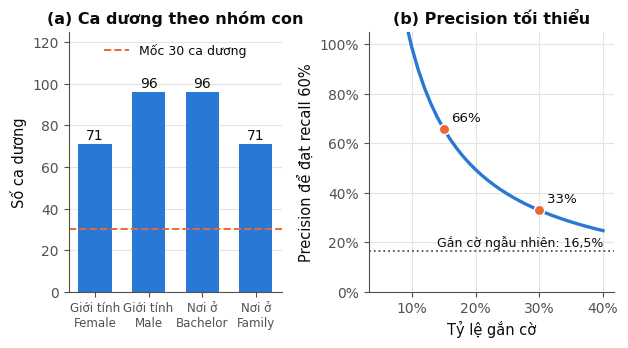

**t_vif_core.csv**

,variable,vif
0,credits_completed,8.149
1,semester_capped,7.750
2,study_hours,1.201
3,english_basic,1.192
4,study_sessions,1.186
5,english_advance,1.168
6,skill_hours,1.065
7,social_hours,1.064
8,attendance_pct,1.045
9,learning_mode_online,1.029


**t_subgroup_size.csv**

,attribute,group,n,positives,rate,lo,hi,recall_ci_halfwidth_if_recall60
0,Giới tính,Female,453,71,0.157,0.126,0.193,0.114
1,Giới tính,Male,562,96,0.171,0.142,0.204,0.098
2,Nơi ở,Bachelor,475,96,0.202,0.168,0.241,0.098
3,Nơi ở,Family,540,71,0.131,0.106,0.163,0.114


**t_aq7_binormal.csv**

,auc,recall_at_flag_15,recall_at_flag_30
0,0.65,0.274,0.469
1,0.70,0.324,0.532
2,0.75,0.381,0.599
3,0.80,0.445,0.671
4,0.85,0.518,0.747
5,0.90,0.604,0.830


**t_aq7_feasibility.csv**

,flag_rate,min_precision_for_recall60,min_lift,flagged_n_of_1015,true_pos_needed
0,0.10,0.987,6.0,102,101
1,0.15,0.658,4.0,152,101
2,0.20,0.494,3.0,203,101
3,0.25,0.395,2.4,254,101
4,0.30,0.329,2.0,304,101


**t_sensitivity_B.csv**

,variable,ps_B,p_B,ps_primary,delta
0,study_hours,0.472,0.231,0.470,0.002
1,study_sessions,0.502,0.916,0.502,0.000
2,attendance_pct,0.395,0.000,0.395,0.001
3,social_hours,0.546,0.051,0.533,0.013
4,skill_hours,0.481,0.409,0.480,0.001
5,english_level,0.476,0.260,0.466,0.010
6,semester_capped,0.540,0.098,0.526,0.014
7,credits_completed,0.531,0.192,0.511,0.020


In [33]:
part_f_readiness()
display(Markdown("**t_vif_core.csv**"))
display(pd.read_csv(TAB / "t_vif_core.csv").round(3))
display(Markdown("**t_subgroup_size.csv**"))
display(pd.read_csv(TAB / "t_subgroup_size.csv").round(3))
display(Markdown("**t_aq7_binormal.csv**"))
display(pd.read_csv(TAB / "t_aq7_binormal.csv").round(3))
display(Markdown("**t_aq7_feasibility.csv**"))
display(pd.read_csv(TAB / "t_aq7_feasibility.csv").round(3))
display(Markdown("**t_sensitivity_B.csv**"))
display(pd.read_csv(TAB / "t_sensitivity_B.csv").round(3))

#### A6.9. Lưu kết quả EDA

Toàn bộ con số được dùng trong báo cáo được lưu vào `reports/milestone3/eda_results.json`.

In [34]:
with open(ROOT / "reports" / "milestone3" / "eda_results.json", "w", encoding="utf-8") as f:
    json.dump(R, f, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Hoàn tất EDA:", len(list(FIG.glob("*.png"))), "hình,", len(list(TAB.glob("*.csv"))), "bảng")

Hoàn tất EDA: 15 hình, 21 bảng


### A7. Kiểm tra tái lập và tóm tắt kết quả

#### A7.1. Đối chiếu với gói dữ liệu đã nộp

Ô dưới đây so sánh mã băm SHA-256 của từng tệp do notebook tạo ra với tệp tương ứng trong gói `M3_Prepared_Data_Package` đã nộp kèm báo cáo. Kết quả được tạo với pandas 3.0 và scikit-learn 1.9; nếu môi trường dùng phiên bản khác, một vài tệp có thể khác ở cách ghi số (ví dụ số chữ số thập phân) dù nội dung không đổi. Vì vậy, ngoài mã băm, ô này còn kiểm tra các bất biến về nội dung: số dòng, số ca dương theo từng ngưỡng và cân bằng fold.

In [35]:
EXPECTED_SHA256 = {
    "data/processed/m3_analytic_master.csv": "0cc36d4f5175a64b54e7943ef4a5874cf9d8893bff3f0229ac8fa260b4d3e1c6",
    "data/processed/m3_analytic_primary_model.csv": "5ee373340359f46d9ef286c6ff029b05aa0e3e7eb4bdb06a15e5765affeb4503",
    "data/processed/m3_audit_groups.csv": "6e13acd36a31f95139e4caf326cf7e5199e7bcaebe5188513075d2adfe12acc8",
    "data/interim/m3_typed_standardized.csv": "a2012f6c1b81e45ce36964e249c988ee0a34f77551d37bccfa8f5225f67ecdb6",
    "data/metadata/data_dictionary_m3.csv": "4c817dc4a8fcf400d617bcf7ce6a1d4b523961a820bef03f9272523e1cce0a24",
    "data/metadata/data_lineage_m3.csv": "fb4cd17bedea9e30e51842706a296d6c0ffc7928396bb08f436b667b4d52a58f",
    "data/metadata/quality_issue_log_m3.csv": "476546fe4a6c09dd062a9208d58a5204513b680978100c697d6d4e944071b90c",
    "data/metadata/transformation_log_m3.csv": "fae369a93f605c2d8eeb1517e9a787f77e23d6f76ea0939788e73696302b0267",
    "reports/milestone3/tables/t_aq1_by_cohort.csv": "c2762df17903ccbf0510217b1e02263ab0eccd81ee71aedff2828d1ea1babdb8",
    "reports/milestone3/tables/t_aq1_by_semband.csv": "2a30f64a381cb57862c1e7b2fdc3d9e629024152538dc1340318d5b6700ec329",
    "reports/milestone3/tables/t_aq1_prevalence.csv": "7b3238d05e4f5f5d9f74f50e828f9278befbb5e000bb132196bb279876838e02",
    "reports/milestone3/tables/t_aq2_att_study_counts.csv": "83641183cfd5bd51ef6be924dca9db5245ef81e3af15bd03db7e39c7f71a832b",
    "reports/milestone3/tables/t_aq2_att_study_matrix.csv": "8090a6d9b8fb461d8232387a8983cdc538610ee448836e156a092cbad9370db9",
    "reports/milestone3/tables/t_aq2_attendance_bins.csv": "10e083d8d6bfdcbc29d9470319ff542218c03cd9a695f5cf096bceb38610410d",
    "reports/milestone3/tables/t_aq2_attendance_by_semband.csv": "894303f3bbc3d24332552584ac439f023cdd8892918c631b0524dda2c78fdc50",
    "reports/milestone3/tables/t_aq2_numeric.csv": "f91d6098ba64cf4fc050a715151cf3e8e621b746bb90ccd54b750223dfeaa2c9",
    "reports/milestone3/tables/t_aq3_binary.csv": "29c273c402e447bc0971535ed08f2c35a4bebf6d2ce285955dfbb80ca1705628",
    "reports/milestone3/tables/t_aq3_numeric.csv": "2d0308e4f7f112a48bb293279abca885e1addddf4a6485eb49ef6e863c9667bd",
    "reports/milestone3/tables/t_aq7_binormal.csv": "b69f09ef8e31c3ded3495b7d703fd9f94ea5e37ac9d0f0fdd9da75df8763a262",
    "reports/milestone3/tables/t_aq7_feasibility.csv": "09f512cc9baeb4f4a332046e3e397ab72c4297b91ff6d43db4c715c782da7ee6",
    "reports/milestone3/tables/t_composition_shift.csv": "0c15defde6ffcaf7121d191b1e02bc8adf1980059af94b246c5cdfefcfba4eca",
    "reports/milestone3/tables/t_descriptive_primary.csv": "3d878698e576dfdd4b5377968333878d813542363db1c4707ef4672fc4c6f56e",
    "reports/milestone3/tables/t_forest_ps.csv": "93fa082d0b840c590addbafad9a93d1ab8caa9aa4aef1e33edfbd9edb6f0fca9",
    "reports/milestone3/tables/t_leakage_evidence.csv": "ee78ba0e3116719a6d976cfd95479221ffdd1a9ad1b9bd0f67973a990f4403d8",
    "reports/milestone3/tables/t_placeholder_vs_rest.csv": "4718fbeea60f8f247c13cb25839cccf48cb7d0b2adea6a94411ff480604af585",
    "reports/milestone3/tables/t_sensitivity_B.csv": "89af3b192a9cb7abaad57fe191f1f8182a39d952e69484144bf81bcea6eeb40f",
    "reports/milestone3/tables/t_spearman_matrix.csv": "68545adf7d53dacc6d6c8aef1a70f39243a0204f0ecfb1fc33323bdd760c0c2a",
    "reports/milestone3/tables/t_subgroup_size.csv": "3c1017046ce4c88c5b6f043eefda439bd600e0d75aa3ed4905138c9dbe1c626b",
    "reports/milestone3/tables/t_vif_core.csv": "e47d6ae231f555a274e2dc4abd27c74c4b17dfc5677024584f72dc1008e16eb9",
}
rows = []
for rel, h in EXPECTED_SHA256.items():
    p = ROOT / rel
    rows.append({"Tệp": rel, "Tồn tại": p.exists(), "Trùng từng byte": p.exists() and sha256_of(p) == h})
check = pd.DataFrame(rows)
display(check)
print(f"Trùng từng byte: {int(check['Trùng từng byte'].sum())}/{len(check)} tệp")

prim_file = pd.read_csv(processed / "m3_analytic_primary_model.csv")
assert len(prim_file) == 1015 and prim_file.shape[1] == 18
assert prim_file[["y_lt_2_50", "y_lt_2_75", "y_lt_3_00"]].sum().tolist() == [52, 167, 311]
assert prim_file.groupby("cv_fold_primary")["y_lt_2_75"].sum().tolist() == [33, 33, 33, 34, 34]
assert prim_file[CORE_FEATURES].isna().sum().sum() == 0
print("Các bất biến nội dung của Prepared Dataset v1.0 đều đạt.")

,Tệp,Tồn tại,Trùng từng byte
0,data/processed/m3_analytic_master.csv,True,True
1,data/processed/m3_analytic_primary_model.csv,True,True
2,data/processed/m3_audit_groups.csv,True,True
3,data/interim/m3_typed_standardized.csv,True,True
4,data/metadata/data_dictionary_m3.csv,True,True
5,data/metadata/data_lineage_m3.csv,True,True
6,data/metadata/quality_issue_log_m3.csv,True,True
7,data/metadata/transformation_log_m3.csv,True,True
8,reports/milestone3/tables/t_aq1_by_cohort.csv,True,True
9,reports/milestone3/tables/t_aq1_by_semband.csv,True,True


Trùng từng byte: 24/29 tệp
Các bất biến nội dung của Prepared Dataset v1.0 đều đạt.


#### A7.2. Tóm tắt kết quả chính

* **Prepared Dataset v1.0.** Từ 1.194 phiếu, 39 dòng CGPA bằng 0 không có nhãn và 140 dòng thuộc cặp lặp 2,68/3,15 bị loại khỏi mẫu chính, còn 1.015 sinh viên với 167 ca dương (16,5%) ở ngưỡng 2,75. Mẫu độ nhạy B giữ cặp lặp (1.155 sinh viên). Tệp mô hình gồm 13 đặc trưng lõi từ 12 mục khảo sát, không chứa biến rò rỉ hay biến nhạy cảm, không có giá trị khuyết.
* **AQ1.** Tỷ lệ nhóm cần hỗ trợ ở ba ngưỡng 2,50, 2,75 và 3,00 lần lượt khoảng 5%, 16,5% và 31% trên mẫu chính; ngưỡng 2,75 cho số ca dương đủ cho kiểm định chéo và kiểm định công bằng.
* **AQ2.** Trong năm thói quen tự báo cáo, chuyên cần là tín hiệu có hướng rõ ràng nhất (chuyên cần thấp đi kèm tỷ lệ cần hỗ trợ cao hơn); các biến giờ học, số lần ngồi học, giờ mạng xã hội và giờ phát triển kỹ năng có độ lớn hiệu ứng nhỏ.
* **AQ3.** Trình độ tiếng Anh có quan hệ chữ U với nhãn (Basic và Advance cao hơn Intermediate), nên được mã hóa bằng hai biến giả. Học kỳ và số tín chỉ tương quan rất mạnh, cần xử lý đa cộng tuyến ở Milestone 4.
* **Rò rỉ.** Cảnh cáo học vụ, đình chỉ, học bổng, tư vấn và SGPA liên hệ rất mạnh với nhãn và bị loại khỏi tập đặc trưng.
* **Mức sẵn sàng AQ4 đến AQ7.** EPV khoảng 12,8 và 33 đến 34 ca dương mỗi fold cho phép một mô hình đơn giản; ca dương theo phân nhóm chỉ 71 đến 96 nên kết luận công bằng sẽ có khoảng tin cậy rộng. Theo giới hạn binormal, đạt recall 60% tại trần gắn cờ 30% cần AUC khoảng 0,75, và tại trần 15% cần AUC khoảng 0,90; đây là kỳ vọng thận trọng được mang sang Milestone 4.

Các con số chi tiết nằm trong các bảng đã hiển thị ở Mục 6 và trong `eda_results.json`.

## PHẦN B. Thực nghiệm mô hình và đánh giá (Milestone 4)

### Giới thiệu Phần B

**Nhóm N02**, học phần Khoa học Phân tích Dữ liệu, Khoa Công nghệ Thông tin, Trường Đại học Khoa học Tự nhiên, ĐHQG-HCM.
Thành viên: Ngô Triệu Gia Gia (25C11037), Trần Duy Khương (25C12004), Nguyễn Hoàng Nhật Quang (25C12033).
Giảng viên phụ trách: TS. Nguyễn Trần Minh Thư.

Notebook này là phần mã nguồn của Level 2 (Prototype Experiment) trong báo cáo Milestone 4. Mục đích của Level 2 là **kiểm chứng tính khả thi** của đề xuất Level 1 (Mục 2 đến Mục 6 của báo cáo) trên Prepared Dataset v1.0, chứ không phải tối ưu một chỉ số. Kết quả tương ứng Mục 7 và Mục 8 của báo cáo.

**Câu hỏi được kiểm chứng**

| AQ | Analytics level | Cách kiểm chứng trong notebook |
|---|---|---|
| AQ4 | Predictive (sàng lọc đồng thời) | So sánh baseline chuyên cần với hồi quy logistic, Random Forest và Gradient Boosting bằng kiểm định chéo lặp |
| AQ7 | Descriptive / Operational | Đường cong recall theo tỷ lệ gắn cờ và bảng precision |
| AQ5 | Explanatory | Hoán vị và ablation theo nhóm tín hiệu, hệ số theo fold, chọn mục khảo sát bằng L1 trong fold |
| AQ6 | Diagnostic / Fairness | Recall và precision theo giới tính, nơi ở tại ngưỡng chung |
| AQ2, AQ3 | Diagnostic | Mô hình logistic hiệu chỉnh so với liên hệ không hiệu chỉnh (chỉ là liên hệ) |

**Nguyên tắc thực nghiệm**

1. **Đăng ký trước.** Tiêu chí thành công S1 đến S5 và quy tắc chọn phương pháp chính được cố định trong tệp kế hoạch có mã băm SHA-256 trước khi huấn luyện. Notebook kiểm tra mã băm và dừng nếu kế hoạch bị sửa.
2. **Chống rò rỉ dữ liệu.** Điền khuyết, chuẩn hóa, chọn đặc trưng và chọn siêu tham số đều nằm trong `Pipeline` và chỉ được fit trên phần huấn luyện của từng fold.
3. **Đánh giá vững.** Kiểm định chéo phân tầng 5 phần lặp 10 lần; khoảng tin cậy 95% bằng bootstrap 2.000 lần; so sánh giữa các mô hình dùng cùng mẫu bootstrap (ghép cặp).
4. **Không điều chỉnh để đạt ngưỡng.** Kết quả không thuận lợi được báo cáo nguyên trạng.


### B1. Thiết lập môi trường

#### B1.1. Thư viện

Notebook chỉ dùng các thư viện có sẵn trên Colab. Kiểm định Wald cho mô hình hiệu chỉnh được tính trực tiếp bằng `numpy` thay vì dùng `statsmodels`, để giảm phụ thuộc.

In [36]:
import hashlib
import json
import platform
import time
import warnings
from datetime import datetime, timezone
from math import ceil
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1


#### B1.2. Cấu hình thực nghiệm

* **Tập đặc trưng lõi:** 13 cột từ 12 mục khảo sát của Milestone 3 (trình độ tiếng Anh là một mục nhưng có hai biến giả). Nhãn chính là `y_lt_2_75` (CGPA < 2,75).
* **Thiết kế kiểm định:** 5 phần × 10 lần lặp, bootstrap 2.000 lần, hai tỷ lệ gắn cờ vận hành 15% (Milestone 1) và 30% (Đề cương).
* **Bốn nhóm tín hiệu** dùng cho AQ5: thói quen học tập, trình độ tiếng Anh, tiến độ học vụ và bối cảnh học tập.
* **Ký hiệu mô hình:** B1 là baseline một biến chuyên cần; M1 là hồi quy logistic L2 có trọng số lớp (phương pháp chính); M1u là M1 không trọng số, dùng để đo hiệu chuẩn; M2 là Random Forest; M3 là Gradient Boosting nông; S1 là hồi quy logistic có bước chọn mục khảo sát bằng L1 trong fold. Ký hiệu mô hình S1 khác với tiêu chí thành công S1 ở Mục 2.2.

In [37]:
# Hằng số lấy từ pipeline chuẩn bị dữ liệu của Milestone 3 (Phần A của notebook này), sao chép lại cho rõ ràng
CORE_FEATURES = ["study_hours", "study_sessions", "attendance_pct", "social_hours", "skill_hours",
                 "learning_mode_online", "has_pc", "uses_transport", "english_basic", "english_advance",
                 "semester_capped", "credits_completed", "cocurricular"]
PRIMARY_TARGET = "y_lt_2_75"
RANDOM_STATE = 42

BASE = Path("/content") if Path("/content").exists() else Path.cwd()
ROOT = BASE / "N02_Milestone5"
OUT = ROOT / "reports" / "milestone4"
FIG = OUT / "figures"
TAB = OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

N_SPLITS, N_REPEATS, N_BOOT = 5, 10, 2000
FLAG_RATES = (0.15, 0.30)
RATE_GRID = tuple(np.round(np.arange(0.05, 0.501, 0.05), 2))

# ---------------------------------------------------------------------------
# 1. Cấu hình biến và nhóm tín hiệu
# ---------------------------------------------------------------------------
CONT = ["study_hours", "study_sessions", "attendance_pct", "social_hours", "skill_hours", "semester_capped", "credits_completed"]
BIN = ["learning_mode_online", "has_pc", "uses_transport", "english_basic", "english_advance", "cocurricular"]
GROUPS = {
    "Thói quen học tập": ["study_hours", "study_sessions", "attendance_pct", "social_hours", "skill_hours"],
    "Trình độ tiếng Anh": ["english_basic", "english_advance"],
    "Tiến độ học vụ": ["semester_capped", "credits_completed"],
    "Bối cảnh học tập": ["learning_mode_online", "has_pc", "uses_transport", "cocurricular"],
}
# 12 mục khảo sát: tiếng Anh là một mục nhưng có hai biến giả
ITEM_OF = {c: c for c in CORE_FEATURES}
ITEM_OF.update({"english_basic": "english", "english_advance": "english"})
N_ITEMS = len(set(ITEM_OF.values()))
LABEL = {
    "study_hours": "Giờ học mỗi ngày", "study_sessions": "Số lần ngồi học", "attendance_pct": "Chuyên cần (%)",
    "social_hours": "Giờ mạng xã hội", "skill_hours": "Giờ phát triển kỹ năng", "learning_mode_online": "Ưa học trực tuyến",
    "has_pc": "Có máy tính cá nhân", "uses_transport": "Dùng xe đưa đón", "english_basic": "Tiếng Anh Basic",
    "english_advance": "Tiếng Anh Advance", "semester_capped": "Học kỳ hiện tại", "credits_completed": "Tín chỉ hoàn thành",
    "cocurricular": "Hoạt động ngoại khóa", "english": "Trình độ tiếng Anh",
}
MODEL_NAME = {
    "B1": "B1 Baseline chuyên cần", "M1": "M1 Logistic (primary)", "M2": "M2 Random Forest",
    "M3": "M3 Gradient Boosting", "S1": "S1 Logistic L1 (chọn trong fold)",
}

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
BLUE_LIGHT, BLUE_DARK = "#9ec5f4", "#0d366b"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
MODEL_COLOR = {"B1": INK2, "M1": BLUE, "M2": ORANGE, "M3": AQUA, "S1": BLUE_DARK}

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10.5, "axes.titlesize": 11.5, "axes.titleweight": "bold",
    "axes.labelsize": 10.5, "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})

In [38]:
def lr_penalty(l1_ratio: float) -> dict:
    """Tham số phạt tương thích nhiều phiên bản scikit-learn (từ 1.8 dùng l1_ratio, bản cũ dùng penalty)."""
    major_minor = tuple(int(x) for x in sklearn.__version__.split(".")[:2])
    if major_minor >= (1, 8):
        return {"l1_ratio": l1_ratio}
    return {"penalty": "l1" if l1_ratio >= 1.0 else "l2"}


def vi(x: float, nd: int = 2) -> str:
    return f"{x:.{nd}f}".replace(".", ",")


def save(fig: plt.Figure, name: str) -> None:
    fig.savefig(FIG / name, dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)

## 2. Dữ liệu đầu vào và kế hoạch đánh giá đăng ký trước

### 2.1. Dữ liệu đầu vào

Dữ liệu của thực nghiệm chính là ba tệp do **Phần A** vừa tạo từ tệp gốc: bảng mô hình của mẫu chính (1.015 sinh viên, 13 đặc trưng, ba nhãn), bảng nhóm kiểm toán (giới tính, nơi ở, chỉ dùng cho AQ6) và bảng master (dùng cho phân tích độ nhạy trên mẫu B). Riêng tệp kế hoạch đánh giá đăng ký trước được nhúng nguyên văn từ bản đã lưu khi đăng ký, để mã băm khớp với giá trị được trích trong báo cáo.

In [39]:
#@title Kế hoạch đánh giá đăng ký trước, nguyên văn từ lúc đăng ký (bấm để xem mã)
PREREG_TEXT = r'''{
  "version": "M4-prereg-v1.0",
  "ghi_chu": "Kế hoạch đánh giá cố định trước khi huấn luyện mô hình; mọi thay đổi về sau phải ghi trong Change Log.",
  "du_lieu": {
    "tep": "data/processed/m3_analytic_primary_model.csv (Prepared Dataset v1.0 của Milestone 3)",
    "nhan_chinh": "y_lt_2_75",
    "nhan_do_nhay": [
      "y_lt_2_50",
      "y_lt_3_00"
    ],
    "mau_do_nhay": "m3_analytic_master.csv, cờ in_sensitivity_B (giữ 140 phiếu cặp lặp)"
  },
  "kiem_dinh": {
    "chien_luoc": "RepeatedStratifiedKFold, 5 phần, 10 lần lặp, random_state 42, phân tầng theo nhãn",
    "quy_tac_ro_ri": "Mọi bước điền khuyết, chuẩn hóa, chọn đặc trưng và chọn siêu tham số nằm trong Pipeline, fit trên phần huấn luyện của từng fold; chọn C của hồi quy logistic bằng CV lồng 3 phần theo AUC.",
    "diem_so": "Dự đoán ngoài fold (out-of-fold) cho mọi sinh viên; mỗi lần lặp cho một vector điểm riêng.",
    "khoang_tin_cay": "Bootstrap 2.000 lần lấy mẫu lại sinh viên (seed 42), tính lại chỉ số trên từng lần lặp rồi lấy trung bình.",
    "khong_dung_hold_out": "Chỉ 167 ca dương; hold-out 20% chỉ có khoảng 33 ca dương."
  },
  "mo_hinh": {
    "B0": "Ngẫu nhiên theo tỷ lệ nền (AUC kỳ vọng 0,5)",
    "B1": "Baseline chuyên cần: hồi quy logistic một biến attendance_pct (tương đương xếp hạng theo chuyên cần thấp)",
    "M1": "Hồi quy logistic L2, class_weight balanced, 13 cột đặc trưng lõi (primary approach đề xuất ở Level 1)",
    "M1u": "Hồi quy logistic L2 không trọng số (dùng cho kiểm tra hiệu chuẩn xác suất)",
    "M2": "Random Forest (balanced_subsample, 300 cây, min_samples_leaf 10)",
    "M3": "HistGradientBoosting (độ sâu 3, learning rate 0,05, 200 vòng, class_weight balanced)",
    "S1": "Hồi quy logistic L1 với chọn đặc trưng trong fold (đo mức rút gọn bộ tín hiệu)"
  },
  "chi_so": {
    "chinh": [
      "ROC-AUC",
      "recall tại tỷ lệ gắn cờ 30%"
    ],
    "phu": [
      "PR-AUC",
      "precision tại 15% và 30%",
      "recall tại 15%",
      "Brier score",
      "độ dốc hiệu chuẩn (calibration slope)"
    ],
    "ty_le_gan_co": [
      0.15,
      0.3
    ]
  },
  "tieu_chi_thanh_cong": {
    "S1_KPI_De_cuong": "AUC trung bình qua các lần lặp của primary ≥ 0,70 VÀ recall ≥ 60% tại tỷ lệ gắn cờ 30%. Mức 'đạt có độ tin cậy' khi cận dưới khoảng tin cậy 95% cũng vượt ngưỡng; 'đạt điểm ước lượng' khi chỉ ước lượng điểm vượt.",
    "S1b_kich_ban_15": "Kịch bản gắn cờ 15%: báo cáo recall; ngưỡng tham chiếu 60% (từ Milestone 1), xếp là chỉ tiêu phụ.",
    "S2_gia_tri_tren_baseline": "Chênh lệch AUC primary so với B1 ≥ 0,03 và khoảng tin cậy bootstrap ghép cặp có cận dưới > 0.",
    "S3_rut_gon_tin_hieu": "Tập rút gọn có số mục khảo sát giảm ít nhất 1/3 (≤ 8 trên 12 mục) với AUC giảm không quá 0,02 so với mô hình đầy đủ.",
    "S4_hieu_chuan": "Độ dốc hiệu chuẩn của mô hình không trọng số trong [0,8; 1,2] và Brier thấp hơn baseline tỷ lệ nền.",
    "S5_cong_bang": "Chênh lệch recall giữa các nhóm (giới tính, nơi ở) tại ngưỡng chung không quá 10 điểm phần trăm; nếu khoảng tin cậy của chênh lệch rộng hơn 20 điểm thì kết luận là 'chưa kết luận được'."
  },
  "quy_tac_chon_primary": "Giữ hồi quy logistic làm primary approach trừ khi một candidate có AUC cao hơn ≥ 0,03 và khoảng tin cậy ghép cặp có cận dưới > 0; khi đó thảo luận đánh đổi với khả năng giải thích trước khi đổi.",
  "phan_tich_bo_sung": [
    "AQ5: ablation theo nhóm tín hiệu (thói quen, tiếng Anh, tiến độ học vụ, bối cảnh), hoán vị theo nhóm trong fold kiểm tra, hệ số chuẩn hóa theo fold.",
    "AQ2 và AQ3: so sánh không hiệu chỉnh với mô hình logistic hiệu chỉnh (OR trên mỗi 1 độ lệch chuẩn, khoảng tin cậy Wald), giải thích là liên hệ, không phải nhân quả.",
    "Độ nhạy: nhãn ở ngưỡng 2,50 và 3,00; mẫu độ nhạy B."
  ],
  "cam_ket_bao_cao": "Báo cáo cả các chỉ số không thuận lợi; không chọn chỉ số sau khi thấy kết quả; không điều chỉnh siêu tham số vượt lưới cố định ở trên.",
  "tao_luc_utc": "2026-11-09 15:40:42",
  "sha256_du_lieu_mo_hinh": "5ee373340359f46d9ef286c6ff029b05aa0e3e7eb4bdb06a15e5765affeb4503"
}'''

OUT.mkdir(parents=True, exist_ok=True)
(OUT / "evaluation_plan_prereg.json").write_bytes(PREREG_TEXT.encode("utf-8"))
print("Đã ghi evaluation_plan_prereg.json:", len(PREREG_TEXT.encode("utf-8")), "byte")

Đã ghi evaluation_plan_prereg.json: 4754 byte


#### B2.2. Nội dung kế hoạch đăng ký trước

Từ điển `PLAN` dưới đây là nội dung kế hoạch đánh giá được viết trước khi huấn luyện. Kế hoạch nêu dữ liệu, thiết kế kiểm định, các mô hình, chỉ số, năm tiêu chí thành công và quy tắc chọn phương pháp chính:

| Mã | Tiêu chí đăng ký trước |
|---|---|
| S1 | AUC ≥ 0,70 và recall ≥ 60% tại tỷ lệ gắn cờ 30% |
| S1b | Báo cáo recall tại tỷ lệ gắn cờ 15% (chỉ tiêu phụ, tham chiếu 60%) |
| S2 | AUC của mô hình chính cao hơn baseline B1 ít nhất 0,03 và cận dưới khoảng tin cậy ghép cặp lớn hơn 0 |
| S3 | Bộ tín hiệu rút gọn còn tối đa 8 trên 12 mục với AUC giảm không quá 0,02 |
| S4 | Độ dốc hiệu chuẩn của mô hình không trọng số trong [0,8; 1,2] và Brier thấp hơn baseline tỷ lệ nền |
| S5 | Chênh lệch recall giữa các nhóm không quá 10 điểm phần trăm; nếu khoảng tin cậy rộng hơn 20 điểm thì kết luận là chưa kết luận được |

Ô kiểm tra sau đó xác nhận ba điều: tệp kế hoạch đã lưu có mã băm `6544eb8a5875a0ce...`; nội dung tệp trùng với `PLAN` (ngoại trừ thời điểm tạo và mã băm dữ liệu được ghi thêm lúc đăng ký); và dữ liệu đầu vào chính là dữ liệu đã được băm lúc đăng ký.

In [40]:
PLAN = {
    "version": "M4-prereg-v1.0",
    "ghi_chu": "Kế hoạch đánh giá cố định trước khi huấn luyện mô hình; mọi thay đổi về sau phải ghi trong Change Log.",
    "du_lieu": {
        "tep": "data/processed/m3_analytic_primary_model.csv (Prepared Dataset v1.0 của Milestone 3)",
        "nhan_chinh": "y_lt_2_75",
        "nhan_do_nhay": ["y_lt_2_50", "y_lt_3_00"],
        "mau_do_nhay": "m3_analytic_master.csv, cờ in_sensitivity_B (giữ 140 phiếu cặp lặp)",
    },
    "kiem_dinh": {
        "chien_luoc": "RepeatedStratifiedKFold, 5 phần, 10 lần lặp, random_state 42, phân tầng theo nhãn",
        "quy_tac_ro_ri": "Mọi bước điền khuyết, chuẩn hóa, chọn đặc trưng và chọn siêu tham số nằm trong Pipeline, fit trên phần huấn luyện của từng fold; "
                         "chọn C của hồi quy logistic bằng CV lồng 3 phần theo AUC.",
        "diem_so": "Dự đoán ngoài fold (out-of-fold) cho mọi sinh viên; mỗi lần lặp cho một vector điểm riêng.",
        "khoang_tin_cay": "Bootstrap 2.000 lần lấy mẫu lại sinh viên (seed 42), tính lại chỉ số trên từng lần lặp rồi lấy trung bình.",
        "khong_dung_hold_out": "Chỉ 167 ca dương; hold-out 20% chỉ có khoảng 33 ca dương.",
    },
    "mo_hinh": {
        "B0": "Ngẫu nhiên theo tỷ lệ nền (AUC kỳ vọng 0,5)",
        "B1": "Baseline chuyên cần: hồi quy logistic một biến attendance_pct (tương đương xếp hạng theo chuyên cần thấp)",
        "M1": "Hồi quy logistic L2, class_weight balanced, 13 cột đặc trưng lõi (primary approach đề xuất ở Level 1)",
        "M1u": "Hồi quy logistic L2 không trọng số (dùng cho kiểm tra hiệu chuẩn xác suất)",
        "M2": "Random Forest (balanced_subsample, 300 cây, min_samples_leaf 10)",
        "M3": "HistGradientBoosting (độ sâu 3, learning rate 0,05, 200 vòng, class_weight balanced)",
        "S1": "Hồi quy logistic L1 với chọn đặc trưng trong fold (đo mức rút gọn bộ tín hiệu)",
    },
    "chi_so": {
        "chinh": ["ROC-AUC", "recall tại tỷ lệ gắn cờ 30%"],
        "phu": ["PR-AUC", "precision tại 15% và 30%", "recall tại 15%", "Brier score", "độ dốc hiệu chuẩn (calibration slope)"],
        "ty_le_gan_co": [0.15, 0.30],
    },
    "tieu_chi_thanh_cong": {
        "S1_KPI_De_cuong": "AUC trung bình qua các lần lặp của primary ≥ 0,70 VÀ recall ≥ 60% tại tỷ lệ gắn cờ 30%. "
                           "Mức 'đạt có độ tin cậy' khi cận dưới khoảng tin cậy 95% cũng vượt ngưỡng; 'đạt điểm ước lượng' khi chỉ ước lượng điểm vượt.",
        "S1b_kich_ban_15": "Kịch bản gắn cờ 15%: báo cáo recall; ngưỡng tham chiếu 60% (từ Milestone 1), xếp là chỉ tiêu phụ.",
        "S2_gia_tri_tren_baseline": "Chênh lệch AUC primary so với B1 ≥ 0,03 và khoảng tin cậy bootstrap ghép cặp có cận dưới > 0.",
        "S3_rut_gon_tin_hieu": "Tập rút gọn có số mục khảo sát giảm ít nhất 1/3 (≤ 8 trên 12 mục) với AUC giảm không quá 0,02 so với mô hình đầy đủ.",
        "S4_hieu_chuan": "Độ dốc hiệu chuẩn của mô hình không trọng số trong [0,8; 1,2] và Brier thấp hơn baseline tỷ lệ nền.",
        "S5_cong_bang": "Chênh lệch recall giữa các nhóm (giới tính, nơi ở) tại ngưỡng chung không quá 10 điểm phần trăm; "
                        "nếu khoảng tin cậy của chênh lệch rộng hơn 20 điểm thì kết luận là 'chưa kết luận được'.",
    },
    "quy_tac_chon_primary": "Giữ hồi quy logistic làm primary approach trừ khi một candidate có AUC cao hơn ≥ 0,03 và khoảng tin cậy ghép cặp có cận dưới > 0; "
                            "khi đó thảo luận đánh đổi với khả năng giải thích trước khi đổi.",
    "phan_tich_bo_sung": [
        "AQ5: ablation theo nhóm tín hiệu (thói quen, tiếng Anh, tiến độ học vụ, bối cảnh), hoán vị theo nhóm trong fold kiểm tra, hệ số chuẩn hóa theo fold.",
        "AQ2 và AQ3: so sánh không hiệu chỉnh với mô hình logistic hiệu chỉnh (OR trên mỗi 1 độ lệch chuẩn, khoảng tin cậy Wald), giải thích là liên hệ, không phải nhân quả.",
        "Độ nhạy: nhãn ở ngưỡng 2,50 và 3,00; mẫu độ nhạy B.",
    ],
    "cam_ket_bao_cao": "Báo cáo cả các chỉ số không thuận lợi; không chọn chỉ số sau khi thấy kết quả; không điều chỉnh siêu tham số vượt lưới cố định ở trên.",
}

In [41]:
prereg_path = OUT / "evaluation_plan_prereg.json"
PREREG_SHA256 = "6544eb8a5875a0ce8db2733720b9b4300c685cc9d1c9afe8a9f4918915681215"
archived = json.loads(prereg_path.read_text(encoding="utf-8"))
digest = hashlib.sha256(prereg_path.read_bytes()).hexdigest()
assert digest == PREREG_SHA256, "Tệp kế hoạch khác với bản đã đăng ký"
(OUT / "evaluation_plan_prereg.sha256").write_text(digest + "\n", encoding="utf-8")

content = {k: v for k, v in archived.items() if k not in ("tao_luc_utc", "sha256_du_lieu_mo_hinh")}
assert content == json.loads(json.dumps(PLAN, ensure_ascii=False)), "Nội dung kế hoạch khác với PLAN"
data_hash = hashlib.sha256((ROOT / "data" / "processed" / "m3_analytic_primary_model.csv").read_bytes()).hexdigest()
if data_hash == archived["sha256_du_lieu_mo_hinh"]:
    print("Dữ liệu đầu vào trùng từng byte với dữ liệu lúc đăng ký.")
else:
    _d = pd.read_csv(ROOT / "data" / "processed" / "m3_analytic_primary_model.csv")
    assert len(_d) == 1015 and int(_d[PRIMARY_TARGET].sum()) == 167, "Dữ liệu khác với dữ liệu lúc đăng ký"
    print("Mã băm dữ liệu khác bản đăng ký (thường do phiên bản thư viện ghi số khác nhau), "
          "nhưng nội dung đạt: 1.015 dòng, 167 ca dương.")
print("Kế hoạch đăng ký lúc (UTC):", archived["tao_luc_utc"])
print("SHA-256 kế hoạch:", digest)
print("Nội dung kế hoạch trùng với PLAN và dữ liệu trùng với dữ liệu lúc đăng ký.")

Dữ liệu đầu vào trùng từng byte với dữ liệu lúc đăng ký.
Kế hoạch đăng ký lúc (UTC): 2026-11-09 15:40:42
SHA-256 kế hoạch: 6544eb8a5875a0ce8db2733720b9b4300c685cc9d1c9afe8a9f4918915681215
Nội dung kế hoạch trùng với PLAN và dữ liệu trùng với dữ liệu lúc đăng ký.


### B3. Các thành phần của thực nghiệm

#### B3.1. Chỉ số đánh giá

* `auc_rank`: ROC-AUC theo thống kê xếp hạng Mann-Whitney, đồng hạng nhận hạng trung bình.
* `hits_at_rate`, `recall_at`, `precision_at`: số ca dương nằm trong nhóm `ceil(rate × n)` sinh viên có điểm cao nhất. Khi nhiều sinh viên cùng điểm tại ngưỡng cắt, phần ca dương ở ngưỡng được chia theo kỳ vọng thay vì phụ thuộc thứ tự dòng, nên recall và precision không đổi khi xáo trộn dữ liệu.
* `wilson`: khoảng tin cậy Wilson cho tỷ lệ, ổn định hơn khoảng Wald khi mẫu nhỏ.
* `calib_slope_intercept`: độ dốc và hằng số chặn hiệu chuẩn, ước lượng bằng hồi quy logistic của nhãn theo logit của xác suất dự đoán. Độ dốc bằng 1 là hiệu chuẩn tốt; nhỏ hơn 1 nghĩa là xác suất trải rộng hơn thực tế.

In [42]:
def auc_rank(y: np.ndarray, s: np.ndarray) -> float:
    """AUC theo thống kê xếp hạng Mann-Whitney (đồng hạng nhận hạng trung bình)."""
    r = stats.rankdata(s)
    n1 = y.sum()
    n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def hits_at_rate(y: np.ndarray, s: np.ndarray, rate: float) -> tuple[float, int]:
    """Số ca dương kỳ vọng nằm trong top rate*n điểm cao nhất; đồng hạng ở ngưỡng được chia đều."""
    n = len(y)
    k = ceil(rate * n)
    order = np.sort(s)[::-1]
    t = order[k - 1]
    above = s > t
    tie = s == t
    a = int(above.sum())
    b = int(tie.sum())
    pos = float(y[above].sum())
    if b > 0:
        pos += (k - a) / b * float(y[tie].sum())
    return pos, k


def recall_at(y, s, rate):
    pos, _ = hits_at_rate(y, s, rate)
    return pos / y.sum()


def precision_at(y, s, rate):
    pos, k = hits_at_rate(y, s, rate)
    return pos / k


def wilson(k: float, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h


def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def calib_slope_intercept(y, p):
    """Độ dốc và hệ số chặn hiệu chuẩn: hồi quy logistic của nhãn theo logit của xác suất dự đoán."""
    z = logit(p).reshape(-1, 1)
    lr = LogisticRegression(C=1e6, max_iter=1000)
    lr.fit(z, y)
    return float(lr.coef_[0, 0]), float(lr.intercept_[0])

#### B3.2. Pipeline mô hình

Mỗi mô hình là một `Pipeline` gồm bộ tiền xử lý (điền trung vị và RobustScaler cho biến liên tục, điền mode cho biến nhị phân) và bộ phân loại. Toàn bộ pipeline được fit lại trong từng fold, vì vậy không có thống kê nào của phần kiểm tra lọt vào phần huấn luyện.

* **B1, M1, M1u:** hồi quy logistic L2. Hệ số phạt C được chọn bằng kiểm định chéo lồng 3 phần theo AUC trên lưới cố định chín giá trị từ 0,001 đến 10, **bên trong** fold huấn luyện. B1 và M1 dùng trọng số lớp cân bằng; M1u không dùng trọng số để đo hiệu chuẩn.
* **M2:** Random Forest 300 cây, tối thiểu 10 mẫu mỗi lá, trọng số lớp theo từng mẫu bootstrap.
* **M3:** Gradient Boosting dạng histogram, độ sâu 3, tốc độ học 0,05, 200 vòng.
* **S1:** hồi quy logistic có bước `L1Select` chọn đặc trưng bằng hồi quy logistic L1 (C chọn bằng kiểm định chéo lồng) trong fold huấn luyện.

Cấu hình của hai mô hình cây được cố định ở mức bảo thủ và không tinh chỉnh thêm, vì mục tiêu là kiểm chứng tính khả thi với 167 ca dương chứ không phải tối đa hóa chỉ số.

In [43]:
def preprocessor(cols: list[str]) -> ColumnTransformer:
    cont = [c for c in CONT if c in cols]
    binary = [c for c in BIN if c in cols]
    parts = []
    if cont:
        parts.append(("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", RobustScaler())]), cont))
    if binary:
        parts.append(("bin", Pipeline([("imp", SimpleImputer(strategy="most_frequent"))]), binary))
    return ColumnTransformer(parts)


def out_columns(cols: list[str]) -> list[str]:
    """Thứ tự cột đầu ra của preprocessor (liên tục trước, nhị phân sau)."""
    return [c for c in CONT if c in cols] + [c for c in BIN if c in cols]


C_GRID = {"C": list(np.logspace(-3, 1, 9))}


def inner_cv() -> StratifiedKFold:
    return StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)


def make_model(key: str, cols: list[str], seed: int) -> Pipeline:
    pre = preprocessor(cols)
    if key in ("B1", "M1", "S2"):
        base = LogisticRegression(**lr_penalty(0.0), class_weight="balanced", max_iter=2000)
        est = GridSearchCV(base, C_GRID, scoring="roc_auc", cv=inner_cv(), n_jobs=1)
        return Pipeline([("pre", pre), ("clf", est)])
    if key == "M1u":
        base = LogisticRegression(**lr_penalty(0.0), max_iter=2000)
        est = GridSearchCV(base, C_GRID, scoring="roc_auc", cv=inner_cv(), n_jobs=1)
        return Pipeline([("pre", pre), ("clf", est)])
    if key == "M2":
        return Pipeline([("pre", pre), ("clf", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=10, max_features="sqrt", class_weight="balanced_subsample",
            n_jobs=2, random_state=seed))])
    if key == "M3":
        return Pipeline([("pre", pre), ("clf", HistGradientBoostingClassifier(
            max_depth=3, learning_rate=0.05, max_iter=200, l2_regularization=1.0, class_weight="balanced",
            early_stopping=False, random_state=seed))])
    if key == "S1":
        return Pipeline([("pre", pre), ("sel", L1Select()), ("clf", LogisticRegression(
            **lr_penalty(0.0), class_weight="balanced", max_iter=2000))])
    raise ValueError(key)


class L1Select(BaseEstimator, TransformerMixin):
    """Chọn đặc trưng bằng hồi quy logistic L1; chọn C bằng CV lồng 3 phần theo AUC; giữ ít nhất một đặc trưng."""

    def fit(self, X, y):
        l1 = LogisticRegression(**lr_penalty(1.0), solver="saga", class_weight="balanced", max_iter=5000, tol=1e-3,
                                random_state=RANDOM_STATE)
        grid = GridSearchCV(l1, C_GRID, scoring="roc_auc", cv=inner_cv(), n_jobs=1)
        grid.fit(X, y)
        coef = np.abs(grid.best_estimator_.coef_).ravel()
        mask = coef > 1e-8
        if not mask.any():
            mask[int(np.argmax(coef))] = True
        self.mask_ = mask
        self.best_C_ = float(grid.best_params_["C"])
        return self

    def get_support(self):
        return self.mask_

    def transform(self, X):
        return X[:, self.mask_]

#### B3.3. Kiểm định chéo lặp

`split_list` sinh 50 lần chia (5 phần × 10 lần lặp, phân tầng theo nhãn) và dùng chung cho mọi mô hình, nhờ đó các so sánh là ghép cặp. `run_cv` trả về ma trận điểm ngoài fold kích thước 10 × n (mỗi lần lặp cho mỗi sinh viên đúng một điểm dự đoán từ mô hình chưa từng thấy sinh viên đó) và ghi thêm thông tin cần cho AQ5:

* với hồi quy logistic: hệ số từng fold và C được chọn;
* với S1: các mục khảo sát được L1 giữ lại;
* với chế độ hoán vị: mức giảm AUC khi hoán vị ngẫu nhiên từng nhóm tín hiệu trong fold kiểm tra (10 lần hoán vị mỗi nhóm).

Với mô hình logistic có trọng số lớp, xác suất bị đẩy về tỷ lệ nền 50%. Hàm hiệu chỉnh hằng số chặn theo tỷ lệ nền của phần huấn luyện để có xác suất đọc được; việc dịch chuyển đơn điệu này không ảnh hưởng đến AUC, recall hay precision.

In [44]:
def split_list(X: pd.DataFrame, y: np.ndarray):
    rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)
    return list(rskf.split(X, y))


def run_cv(key: str, X: pd.DataFrame, y: np.ndarray, splits, cols: list[str] | None = None, record: str | None = None):
    """Chạy CV lặp; trả về ma trận điểm ngoài fold (N_REPEATS x n) và thông tin từng lần fit."""
    cols = cols or list(X.columns)
    n = len(y)
    S = np.zeros((N_REPEATS, n))
    P = np.zeros((N_REPEATS, n))   # xác suất hiệu chỉnh theo tỷ lệ nền huấn luyện (dùng cho mô hình logistic)
    info = []
    for i, (tr, te) in enumerate(splits):
        rep = i // N_SPLITS
        pipe = make_model(key, cols, seed=RANDOM_STATE + rep)
        pipe.fit(X.iloc[tr][cols], y[tr])
        p = pipe.predict_proba(X.iloc[te][cols])[:, 1]
        S[rep, te] = p
        if key in ("M1", "B1", "S2"):
            pi = y[tr].mean()
            P[rep, te] = 1 / (1 + np.exp(-(logit(p) + np.log(pi / (1 - pi)))))
        else:
            P[rep, te] = p
        rec = {"rep": rep, "fold": i % N_SPLITS}
        if record == "lr":
            clf = pipe.named_steps["clf"]
            rec["coef"] = dict(zip(out_columns(cols), clf.best_estimator_.coef_.ravel()))
            rec["C"] = float(clf.best_params_["C"])
        if record == "l1":
            mask = pipe.named_steps["sel"].get_support()
            names = np.array(out_columns(cols))[mask]
            rec["selected_cols"] = list(names)
            rec["selected_items"] = sorted({ITEM_OF[c] for c in names})
            rec["C"] = pipe.named_steps["sel"].best_C_
        if record == "perm":
            rng = np.random.default_rng(RANDOM_STATE + i)
            Xte = X.iloc[te][cols].copy()
            base_auc = auc_rank(y[te], pipe.predict_proba(Xte)[:, 1])
            drops = {}
            for g, gc in GROUPS.items():
                gc = [c for c in gc if c in cols]
                if not gc:
                    continue
                d = []
                for _ in range(10):
                    Xp = Xte.copy()
                    idx = rng.permutation(len(Xp))
                    Xp[gc] = Xp[gc].to_numpy()[idx]
                    d.append(base_auc - auc_rank(y[te], pipe.predict_proba(Xp)[:, 1]))
                drops[g] = float(np.mean(d))
            rec["perm_drop"] = drops
        info.append(rec)
    return S, P, info

#### B3.4. Bootstrap, đường cong năng lực và mô hình hiệu chỉnh

* `metric_vector`: trung bình qua 10 lần lặp của AUC, recall và precision tại 15% và 30%.
* `bootstrap_all`: lấy mẫu lại sinh viên 2.000 lần (cùng chỉ số mẫu cho mọi mô hình) và tính lại các chỉ số; khoảng tin cậy là phân vị 2,5% và 97,5%.
* `capacity_curve`, `capacity_boot`: recall theo tỷ lệ gắn cờ từ 5% đến 50% và khoảng tin cậy.
* `binormal_recall`: recall kỳ vọng theo giả định chuẩn song biến cùng phương sai, để đối chiếu kết quả thực tế với giới hạn lý thuyết đã tính ở Milestone 3.
* `logit_wald`, `holm`: hồi quy logistic không phạt, OR trên mỗi 1 độ lệch chuẩn (biến liên tục) hoặc mỗi 1 đơn vị (biến nhị phân), khoảng tin cậy Wald và hiệu chỉnh Holm, phục vụ AQ2 và AQ3.

In [45]:
def metric_vector(y, S):
    """Trung bình qua các lần lặp của: AUC, recall15, recall30, precision15, precision30."""
    out = np.zeros((S.shape[0], 5))
    for r in range(S.shape[0]):
        s = S[r]
        out[r] = [auc_rank(y, s), recall_at(y, s, 0.15), recall_at(y, s, 0.30), precision_at(y, s, 0.15), precision_at(y, s, 0.30)]
    return out.mean(axis=0)


METRICS = ["AUC", "recall_15", "recall_30", "precision_15", "precision_30"]


def bootstrap_all(y: np.ndarray, S_by: dict[str, np.ndarray], n_boot: int = N_BOOT, seed: int = RANDOM_STATE):
    rng = np.random.default_rng(seed)
    n = len(y)
    res = {k: np.zeros((n_boot, 5)) for k in S_by}
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        yb = y[idx]
        for k, S in S_by.items():
            res[k][b] = metric_vector(yb, S[:, idx])
    return res


def ci(a: np.ndarray) -> tuple[float, float]:
    return float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))


def capacity_curve(y, S, rates=RATE_GRID):
    return np.array([np.mean([recall_at(y, S[r], q) for r in range(S.shape[0])]) for q in rates])


def capacity_boot(y, S, n_boot=N_BOOT, seed=RANDOM_STATE + 1):
    rng = np.random.default_rng(seed)
    n = len(y)
    out = np.zeros((n_boot, len(RATE_GRID)))
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        out[b] = capacity_curve(y[idx], S[:, idx])
    return out


def binormal_recall(auc: float, rate: float) -> float:
    """Recall kỳ vọng theo xấp xỉ binormal cùng phương sai (đối chiếu với tính toán lý thuyết ở Milestone 3)."""
    d = np.sqrt(2) * stats.norm.ppf(auc)
    prev = 0.1645
    lo, hi = -10.0, 10.0
    for _ in range(80):
        mid = (lo + hi) / 2
        flag = prev * (1 - stats.norm.cdf(mid - d)) + (1 - prev) * (1 - stats.norm.cdf(mid))
        if flag > rate:
            lo = mid
        else:
            hi = mid
    return float(1 - stats.norm.cdf((lo + hi) / 2 - d))

In [46]:
def logit_wald(X: pd.DataFrame, y: np.ndarray, cols: list[str]) -> pd.DataFrame:
    """Hồi quy logistic không phạt; OR trên mỗi 1 độ lệch chuẩn (biến liên tục) hoặc mỗi 1 đơn vị (nhị phân); CI Wald."""
    Z = X[cols].astype(float).copy()
    for c in cols:
        if c in CONT:
            Z[c] = (Z[c] - Z[c].mean()) / Z[c].std(ddof=0)
    A = np.column_stack([np.ones(len(Z)), Z.to_numpy()])
    lr = LogisticRegression(C=1e8, max_iter=5000, fit_intercept=False)
    lr.fit(A, y)
    beta = lr.coef_.ravel()
    p = 1 / (1 + np.exp(-A @ beta))
    W = p * (1 - p)
    cov = np.linalg.inv(A.T @ (A * W[:, None]))
    se = np.sqrt(np.diag(cov))
    rows = []
    for j, c in enumerate(cols, start=1):
        z = beta[j] / se[j]
        rows.append({"variable": c, "or": float(np.exp(beta[j])), "lo": float(np.exp(beta[j] - 1.96 * se[j])),
                     "hi": float(np.exp(beta[j] + 1.96 * se[j])), "p": float(2 * (1 - stats.norm.cdf(abs(z))))})
    return pd.DataFrame(rows)


def holm(p: list[float]) -> list[float]:
    m = len(p)
    order = np.argsort(p)
    adj = np.zeros(m)
    run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i])
        adj[i] = min(1.0, run)
    return list(adj)

### B4. AQ4: huấn luyện và so sánh mô hình

#### B4.1. Nạp dữ liệu và kiểm tra đầu vào

Bảng mô hình được nối với bảng nhóm kiểm toán theo khóa `rid` (quan hệ một một). Notebook kiểm tra lại số dòng, không có giá trị khuyết trong đặc trưng lõi và không có biến rò rỉ hay biến nhạy cảm trong tập đặc trưng.

In [47]:
t0 = time.time()
log: dict = {"bat_dau_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S"), "python": platform.python_version(),
             "sklearn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__,
             "random_state": RANDOM_STATE, "n_splits": N_SPLITS, "n_repeats": N_REPEATS, "n_boot": N_BOOT}

# --- 6.1 Dữ liệu và kiểm tra tệp đăng ký trước
prereg_path = OUT / "evaluation_plan_prereg.json"
digest = hashlib.sha256(prereg_path.read_bytes()).hexdigest()
expected = (OUT / "evaluation_plan_prereg.sha256").read_text().strip()
assert digest == expected, "Tệp đăng ký trước đã bị thay đổi sau khi ghi mã băm"
prereg = json.loads(prereg_path.read_text(encoding="utf-8"))
data_path = ROOT / "data" / "processed" / "m3_analytic_primary_model.csv"
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == prereg["sha256_du_lieu_mo_hinh"], "Dữ liệu khác với dữ liệu lúc đăng ký trước"
log.update({"prereg_sha256": digest, "data_sha256": prereg["sha256_du_lieu_mo_hinh"]})

df = pd.read_csv(data_path)
audit = pd.read_csv(ROOT / "data" / "processed" / "m3_audit_groups.csv")
df = df.merge(audit[["rid", "gender", "living_with", "age_band"]], on="rid", how="left", validate="one_to_one")
assert len(df) == 1015 and df[CORE_FEATURES].isna().sum().sum() == 0
forbidden = {"prev_sgpa", "probation", "suspension", "scholarship", "gender", "living_with", "age"}
assert not forbidden & set(CORE_FEATURES)
X = df[CORE_FEATURES]
y = df[PRIMARY_TARGET].to_numpy().astype(int)
n, npos = len(y), int(y.sum())
prev = y.mean()
splits = split_list(X, y)
R: dict = {"n": n, "positives": npos, "prevalence": float(prev), "n_items": N_ITEMS}
print(f"n = {n}, số ca dương = {npos}, tỷ lệ nền = {prev:.4f}, số lần chia = {len(splits)}")

n = 1015, số ca dương = 167, tỷ lệ nền = 0.1645, số lần chia = 50


#### B4.2. Chạy kiểm định chéo cho các mô hình

Ô này chạy sáu cấu hình (B1, M1, M1u, M2, M3, S1), sau đó chạy lại M1 ở chế độ hoán vị theo nhóm để phục vụ AQ5. Đây là ô tốn thời gian nhất của notebook.

In [48]:
# --- 6.2 Chạy các mô hình
S, Pc, info = {}, {}, {}
plan = [("B1", ["attendance_pct"], "lr"), ("M1", None, "lr"), ("M1u", None, None), ("M2", None, None), ("M3", None, None),
        ("S1", None, "l1")]
for key, cols, rec in plan:
    t = time.time()
    S[key], Pc[key], info[key] = run_cv(key, X, y, splits, cols=cols, record=rec)
    print(f"  {key}: {time.time() - t:5.1f} giây, AUC trung bình = {np.mean([auc_rank(y, S[key][r]) for r in range(N_REPEATS)]):.3f}", flush=True)
perm_S, _, perm_info = run_cv("M1", X, y, splits, record="perm")   # chạy lại M1 để ghi hoán vị theo nhóm

  B1:   6.9 giây, AUC trung bình = 0.604
  M1:  10.4 giây, AUC trung bình = 0.621
  M1u:   9.8 giây, AUC trung bình = 0.622
  M2:  39.6 giây, AUC trung bình = 0.638
  M3:   5.1 giây, AUC trung bình = 0.637
  S1:  11.2 giây, AUC trung bình = 0.614


#### B4.3. Bảng kết quả chính và so sánh ghép cặp

Bảng chính báo cáo AUC, recall và precision tại hai tỷ lệ gắn cờ cùng khoảng tin cậy bootstrap, PR-AUC (quan trọng khi tỷ lệ dương chỉ 16,5%) và độ lệch chuẩn của AUC giữa các lần lặp. B0 là mức tham chiếu ngẫu nhiên theo tỷ lệ nền. Bảng so sánh ghép cặp cho chênh lệch giữa từng cặp mô hình trên cùng mẫu bootstrap; khoảng tin cậy chứa 0 nghĩa là chưa đủ bằng chứng về khác biệt.

In [49]:
# --- 6.3 Bảng kết quả chính với bootstrap
boot_models = {k: S[k] for k in ("B1", "M1", "M2", "M3", "S1")}
B = bootstrap_all(y, boot_models)
rows = []
for k in boot_models:
    point = metric_vector(y, S[k])
    auc_reps = [auc_rank(y, S[k][r]) for r in range(N_REPEATS)]
    ap = np.mean([average_precision_score(y, S[k][r]) for r in range(N_REPEATS)])
    row = {"model": MODEL_NAME[k], "key": k, "auc_sd_repeats": float(np.std(auc_reps)), "pr_auc": float(ap)}
    for j, m in enumerate(METRICS):
        lo, hi = ci(B[k][:, j])
        row[m] = float(point[j]); row[m + "_lo"] = lo; row[m + "_hi"] = hi
    rows.append(row)
main_tab = pd.DataFrame(rows)
main_tab.to_csv(TAB / "t4_main_results.csv", index=False)
pd.DataFrame([{"model": "B0 Ngẫu nhiên theo tỷ lệ nền", "AUC": 0.5, "recall_15": 0.15, "recall_30": 0.30,
               "precision_15": prev, "precision_30": prev, "pr_auc": prev}]).to_csv(TAB / "t4_b0_reference.csv", index=False)

# So sánh ghép cặp (cùng mẫu bootstrap)
pair_rows = []
for a, b in (("M1", "B1"), ("M2", "M1"), ("M3", "M1"), ("S1", "M1")):
    for j, m in enumerate(METRICS[:3]):
        d = B[a][:, j] - B[b][:, j]
        lo, hi = ci(d)
        pair_rows.append({"cap": f"{a} so với {b}", "metric": m, "delta": float(metric_vector(y, S[a])[j] - metric_vector(y, S[b])[j]),
                          "lo": lo, "hi": hi})
pd.DataFrame(pair_rows).to_csv(TAB / "t4_paired_deltas.csv", index=False)

# Phân phối AUC theo lần lặp
auc_rep = pd.DataFrame({k: [auc_rank(y, S[k][r]) for r in range(N_REPEATS)] for k in ("B1", "M1", "M2", "M3", "S1")})
auc_rep.to_csv(TAB / "t4_auc_by_repeat.csv", index=False)

display(Markdown("**Kết quả chính (dự đoán ngoài fold, KTC 95% bootstrap)**"))
display(main_tab.drop(columns=["key"]).set_index("model").round(3))
display(Markdown("**Chênh lệch ghép cặp**"))
display(pd.DataFrame(pair_rows).round(3))

**Kết quả chính (dự đoán ngoài fold, KTC 95% bootstrap)**

,auc_sd_repeats,pr_auc,AUC,AUC_lo,AUC_hi,recall_15,recall_15_lo,recall_15_hi,recall_30,recall_30_lo,recall_30_hi,precision_15,precision_15_lo,precision_15_hi,precision_30,precision_30_lo,precision_30_hi
model,,,,,,,,,,,,,,,,,
B1 Baseline chuyên cần,0.004,0.246,0.604,0.555,0.651,0.229,0.182,0.298,0.442,0.377,0.511,0.250,0.189,0.329,0.242,0.195,0.290
M1 Logistic (primary),0.011,0.251,0.621,0.574,0.667,0.262,0.211,0.314,0.457,0.395,0.517,0.286,0.222,0.349,0.250,0.205,0.296
M2 Random Forest,0.012,0.239,0.638,0.592,0.681,0.248,0.200,0.295,0.452,0.392,0.510,0.271,0.210,0.331,0.248,0.201,0.291
M3 Gradient Boosting,0.013,0.237,0.637,0.598,0.677,0.241,0.198,0.285,0.449,0.393,0.507,0.263,0.208,0.316,0.246,0.202,0.287
S1 Logistic L1 (chọn trong fold),0.013,0.246,0.614,0.568,0.657,0.263,0.210,0.310,0.447,0.387,0.501,0.287,0.221,0.349,0.245,0.200,0.287


**Chênh lệch ghép cặp**

,cap,metric,delta,lo,hi
0,M1 so với B1,AUC,0.017,-0.021,0.056
1,M1 so với B1,recall_15,0.032,-0.020,0.075
2,M1 so với B1,recall_30,0.015,-0.045,0.075
3,M2 so với M1,AUC,0.017,-0.016,0.050
4,M2 so với M1,recall_15,-0.014,-0.050,0.022
5,M2 so với M1,recall_30,-0.005,-0.053,0.041
6,M3 so với M1,AUC,0.016,-0.024,0.058
7,M3 so với M1,recall_15,-0.021,-0.067,0.021
8,M3 so với M1,recall_30,-0.008,-0.064,0.048
9,S1 so với M1,AUC,-0.007,-0.016,0.001


Hình dưới đây trình bày phân bố AUC theo từng lần lặp và đường ROC trung bình của các mô hình. Đường đứt nét là mục tiêu AUC 0,70 của Đề cương.

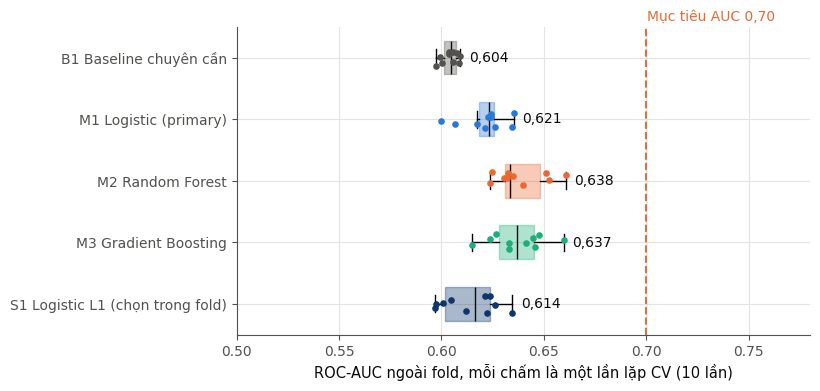

In [50]:
# Hình 1: AUC theo lần lặp
rng_jitter = np.random.default_rng(RANDOM_STATE + 9)   # chỉ dùng để rải điểm trên hình
fig, ax = plt.subplots(figsize=(7.4, 4.0))
keys = ["B1", "M1", "M2", "M3", "S1"]
data = [auc_rep[k].to_numpy() for k in keys]
bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=False)
for patch, k in zip(bp["boxes"], keys):
    patch.set_facecolor(MODEL_COLOR[k]); patch.set_alpha(0.35); patch.set_edgecolor(MODEL_COLOR[k])
for med in bp["medians"]:
    med.set_color(INK)
for i, k in enumerate(keys, start=1):
    ax.scatter(auc_rep[k], np.full(N_REPEATS, i) + rng_jitter.uniform(-0.15, 0.15, N_REPEATS), s=14, color=MODEL_COLOR[k], zorder=3)
    ax.text(auc_rep[k].max() + 0.004, i, vi(auc_rep[k].mean(), 3), va="center", fontsize=10, color=INK)
ax.axvline(0.70, color=ORANGE, ls="--", lw=1.4)
ax.text(0.7005, 0.45, "Mục tiêu AUC 0,70", color=ORANGE, fontsize=10, va="bottom")
ax.set_yticks(range(1, 6)); ax.set_yticklabels([MODEL_NAME[k] for k in keys])
ax.invert_yaxis(); ax.set_xlabel("ROC-AUC ngoài fold, mỗi chấm là một lần lặp CV (10 lần)")
ax.set_xlim(0.50, max(0.78, auc_rep.max().max() + 0.04))
save(fig, "f4_01_auc_by_model.png")

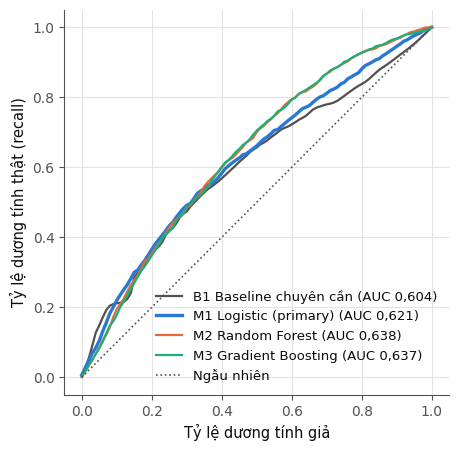

In [51]:
# Hình 2: ROC trung bình
fig, ax = plt.subplots(figsize=(5.6, 5.0))
grid = np.linspace(0, 1, 101)
for k in ("B1", "M1", "M2", "M3"):
    tprs = []
    for r in range(N_REPEATS):
        s_ = S[k][r]
        order = np.argsort(-s_, kind="mergesort")
        ys_ = y[order]; ss_ = s_[order]
        tp = np.cumsum(ys_); fp = np.cumsum(1 - ys_)
        last = np.r_[ss_[1:] != ss_[:-1], True]
        tpr = np.r_[0, tp[last] / npos]; fpr = np.r_[0, fp[last] / (n - npos)]
        tprs.append(np.interp(grid, fpr, tpr))
    tp_m = np.mean(tprs, axis=0)
    ax.plot(grid, tp_m, color=MODEL_COLOR[k], lw=2.4 if k == "M1" else 1.6, label=f"{MODEL_NAME[k]} (AUC {vi(metric_vector(y, S[k])[0], 3)})")
ax.plot([0, 1], [0, 1], color=INK2, ls=":", lw=1.2, label="Ngẫu nhiên")
ax.set_xlabel("Tỷ lệ dương tính giả"); ax.set_ylabel("Tỷ lệ dương tính thật (recall)")
ax.legend(loc="lower right", frameon=False, fontsize=9.5); ax.set_aspect("equal")
save(fig, "f4_02_roc.png")

#### B4.4. Đối chiếu với tiêu chí S1, S2 và quy tắc chọn phương pháp chính

Theo quy tắc đã đăng ký, hồi quy logistic được giữ làm phương pháp chính trừ khi một mô hình cây có AUC cao hơn ít nhất 0,03 **và** cận dưới khoảng tin cậy ghép cặp lớn hơn 0.

In [52]:
# --- 6.4 Tiêu chí thành công đã đăng ký trước
m1 = main_tab.set_index("key").loc["M1"]
d_b1 = [r for r in pair_rows if r["cap"] == "M1 so với B1" and r["metric"] == "AUC"][0]
crit = {
    "S1_AUC_point": bool(m1["AUC"] >= 0.70), "S1_AUC_lower": bool(m1["AUC_lo"] >= 0.70),
    "S1_recall30_point": bool(m1["recall_30"] >= 0.60), "S1_recall30_lower": bool(m1["recall_30_lo"] >= 0.60),
    "S1b_recall15": float(m1["recall_15"]),
    "S2_delta_auc": d_b1["delta"], "S2_met": bool(d_b1["delta"] >= 0.03 and d_b1["lo"] > 0),
}
# quy tắc chọn primary
chg = []
for a in ("M2", "M3"):
    r = [x for x in pair_rows if x["cap"] == f"{a} so với M1" and x["metric"] == "AUC"][0]
    chg.append({"model": a, "delta": r["delta"], "lo": r["lo"], "hi": r["hi"], "switch": bool(r["delta"] >= 0.03 and r["lo"] > 0)})
crit["primary_rule"] = chg

display(pd.Series({k: v for k, v in crit.items() if k != "primary_rule"}, name="Giá trị").to_frame())
display(pd.DataFrame(crit["primary_rule"]).round(3))

,Giá trị
S1_AUC_point,False
S1_AUC_lower,False
S1_recall30_point,False
S1_recall30_lower,False
S1b_recall15,0.261677
S2_delta_auc,0.017081
S2_met,False


,model,delta,lo,hi,switch
0,M2,0.017,-0.016,0.050,False
1,M3,0.016,-0.024,0.058,False


#### B4.5. Hiệu chuẩn xác suất

Độ dốc và hằng số chặn hiệu chuẩn được tính trên mô hình không trọng số M1u (tiêu chí S4) và trên M1 sau khi hiệu chỉnh tỷ lệ nền. Brier score được so với baseline luôn dự đoán tỷ lệ nền. Biểu đồ độ tin cậy nhóm sinh viên theo thập phân vị của xác suất dự đoán.

In [53]:
# --- 6.5 Hiệu chuẩn (mô hình không trọng số và mô hình trọng số hiệu chỉnh theo tỷ lệ nền)
cal_rows = []
for key, P in (("M1u", Pc["M1u"]), ("M1", Pc["M1"])):
    sl, ic, br = [], [], []
    for r in range(N_REPEATS):
        s_, i_ = calib_slope_intercept(y, P[r])
        sl.append(s_); ic.append(i_); br.append(brier_score_loss(y, P[r]))
    cal_rows.append({"model": "M1u Logistic không trọng số" if key == "M1u" else "M1 Logistic trọng số, hiệu chỉnh tỷ lệ nền",
                     "slope": float(np.mean(sl)), "intercept": float(np.mean(ic)), "brier": float(np.mean(br))})
cal_rows.append({"model": "Baseline tỷ lệ nền", "slope": np.nan, "intercept": np.nan, "brier": float(prev * (1 - prev))})
cal = pd.DataFrame(cal_rows)
cal.to_csv(TAB / "t4_calibration.csv", index=False)
crit["S4_slope"] = float(cal.loc[0, "slope"])
crit["S4_met"] = bool(0.8 <= cal.loc[0, "slope"] <= 1.2 and cal.loc[0, "brier"] < prev * (1 - prev))
# bảng độ tin cậy (decile của xác suất trung bình qua các lần lặp)
pm = Pc["M1u"].mean(axis=0)
bins = pd.qcut(pm, 10, duplicates="drop")
rel = pd.DataFrame({"p": pm, "y": y, "bin": bins}).groupby("bin", observed=True).agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size")).reset_index(drop=True)
rel.to_csv(TAB / "t4_reliability.csv", index=False)
pm1 = Pc["M1"].mean(axis=0)
rel1 = pd.DataFrame({"p": pm1, "y": y, "bin": pd.qcut(pm1, 10, duplicates="drop")}).groupby("bin", observed=True).agg(
    p=("p", "mean"), y=("y", "mean"), n=("y", "size")).reset_index(drop=True)
rel1.to_csv(TAB / "t4_reliability_m1_corrected.csv", index=False)

display(cal.round(4))

,model,slope,intercept,brier
0,M1u Logistic không trọng số,0.6960,-0.4736,0.1350
1,"M1 Logistic trọng số, hiệu chỉnh tỷ lệ nền",0.6678,-0.5169,0.1350
2,Baseline tỷ lệ nền,NaN,NaN,0.1375


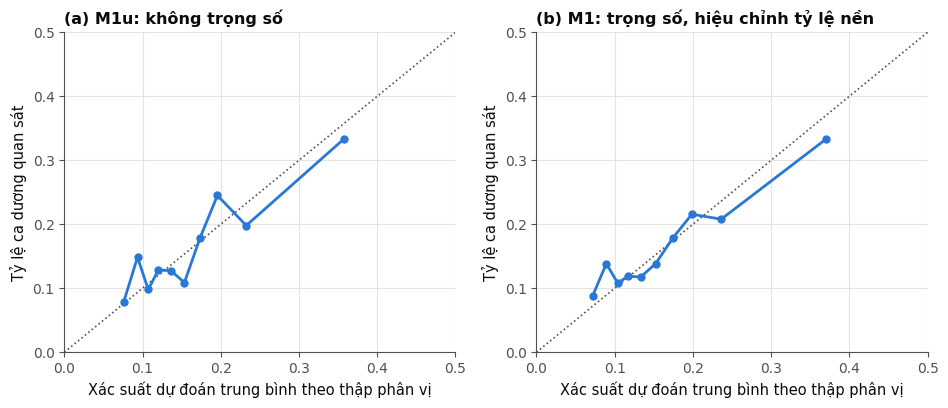

In [54]:
# Hình 4: hiệu chuẩn
fig, axs = plt.subplots(1, 2, figsize=(9.6, 4.2))
for ax, tab, ttl in ((axs[0], rel, "(a) M1u: không trọng số"), (axs[1], rel1, "(b) M1: trọng số, hiệu chỉnh tỷ lệ nền")):
    ax.plot([0, 0.5], [0, 0.5], color=INK2, ls=":", lw=1.2)
    ax.plot(tab["p"], tab["y"], color=BLUE, marker="o", lw=2, ms=5)
    ax.set_xlabel("Xác suất dự đoán trung bình theo thập phân vị"); ax.set_ylabel("Tỷ lệ ca dương quan sát")
    ax.set_title(ttl, loc="left"); mx = max(0.5, float(max(tab["p"].max(), tab["y"].max())) + 0.03)
    ax.set_xlim(0, mx); ax.set_ylim(0, mx)
fig.tight_layout()
save(fig, "f4_04_calibration.png")

### B5. AQ7: đường cong năng lực và điểm vận hành

AQ7 hỏi ở mỗi tỷ lệ gắn cờ, danh sách bắt được bao nhiêu phần trăm sinh viên cần hỗ trợ (recall) và độ chính xác của danh sách (precision) là bao nhiêu; điểm cắt nào đạt recall 60%. Năng lực tư vấn (trần 15% hay 30%) là giả định của stakeholder cần được cố vấn học tập xác nhận.

In [55]:
# --- 6.6 AQ7: đường cong năng lực (recall theo tỷ lệ gắn cờ)
cap_rows = {"rate": list(RATE_GRID)}
capB = {}
for k in ("M1", "B1", "M2", "M3"):
    cap_rows[k] = list(capacity_curve(y, S[k]))
for k in ("M1", "B1"):
    capB[k] = capacity_boot(y, S[k])
    cap_rows[k + "_lo"] = list(np.percentile(capB[k], 2.5, axis=0))
    cap_rows[k + "_hi"] = list(np.percentile(capB[k], 97.5, axis=0))
cap_rows["binormal_auc_M1"] = [binormal_recall(float(m1["AUC"]), q) for q in RATE_GRID]
cap = pd.DataFrame(cap_rows)
cap.to_csv(TAB / "t4_capacity_curve.csv", index=False)
prec_rows = []
for q in RATE_GRID:
    prec_rows.append({"rate": q, "flagged": ceil(q * n),
                      "recall_M1": float(np.mean([recall_at(y, S["M1"][r], q) for r in range(N_REPEATS)])),
                      "precision_M1": float(np.mean([precision_at(y, S["M1"][r], q) for r in range(N_REPEATS)]))})
pd.DataFrame(prec_rows).to_csv(TAB / "t4_operating_points.csv", index=False)
# tỷ lệ gắn cờ tối thiểu để đạt recall 60%
fine = np.round(np.arange(0.05, 0.96, 0.01), 2)
cf = np.array([np.mean([recall_at(y, S["M1"][r], q) for r in range(N_REPEATS)]) for q in fine])
need = float(fine[np.argmax(cf >= 0.60)]) if (cf >= 0.60).any() else float("nan")
R["flag_rate_for_recall60_M1"] = need
cfb = np.array([np.mean([recall_at(y, S["B1"][r], q) for r in range(N_REPEATS)]) for q in fine])
R["flag_rate_for_recall60_B1"] = float(fine[np.argmax(cfb >= 0.60)]) if (cfb >= 0.60).any() else float("nan")

display(pd.DataFrame(prec_rows).round(3))
print("Tỷ lệ gắn cờ tối thiểu để M1 đạt recall 60%:", R["flag_rate_for_recall60_M1"])
print("Tỷ lệ gắn cờ tối thiểu để B1 đạt recall 60%:", R["flag_rate_for_recall60_B1"])

,rate,flagged,recall_M1,precision_M1
0,0.05,51,0.092,0.300
1,0.10,102,0.189,0.310
2,0.15,153,0.262,0.286
3,0.20,203,0.325,0.267
4,0.25,254,0.396,0.261
5,0.30,305,0.457,0.250
6,0.35,356,0.508,0.238
7,0.40,406,0.552,0.227
8,0.45,457,0.604,0.221
9,0.50,508,0.641,0.211


Tỷ lệ gắn cờ tối thiểu để M1 đạt recall 60%: 0.45
Tỷ lệ gắn cờ tối thiểu để B1 đạt recall 60%: 0.47


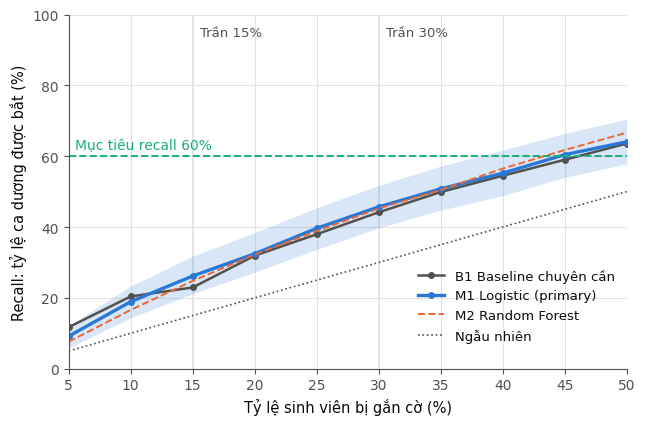

In [56]:
# Hình 3: đường cong năng lực
fig, ax = plt.subplots(figsize=(7.2, 4.6))
x100 = np.array(RATE_GRID) * 100
for k, ls in (("B1", "-"), ("M1", "-")):
    ax.plot(x100, cap[k] * 100, color=MODEL_COLOR[k], lw=2.4 if k == "M1" else 1.8, marker="o", ms=4, label=MODEL_NAME[k])
ax.fill_between(x100, cap["M1_lo"] * 100, cap["M1_hi"] * 100, color=BLUE, alpha=0.18, lw=0)
ax.plot(x100, cap["M2"] * 100, color=ORANGE, lw=1.4, ls="--", label=MODEL_NAME["M2"])
ax.plot(x100, x100, color=INK2, ls=":", lw=1.2, label="Ngẫu nhiên")
ax.axhline(60, color=AQUA, lw=1.4, ls="--"); ax.text(5.5, 62, "Mục tiêu recall 60%", color=AQUA, ha="left", fontsize=10)
for q in FLAG_RATES:
    ax.axvline(q * 100, color=GRID, lw=1.2, zorder=0)
    ax.text(q * 100 + 0.6, 94, f"Trần {int(q * 100)}%", fontsize=9.5, color=INK2)
ax.set_xlabel("Tỷ lệ sinh viên bị gắn cờ (%)"); ax.set_ylabel("Recall: tỷ lệ ca dương được bắt (%)")
ax.set_xlim(5, 50); ax.set_ylim(0, 100); ax.legend(loc="lower right", frameon=False, fontsize=9.5, bbox_to_anchor=(1.0, 0.04))
save(fig, "f4_03_capacity_curve.png")

### B6. AQ5: nhóm tín hiệu và rút gọn bộ tín hiệu

Vì học kỳ và số tín chỉ tương quan rất mạnh, tầm quan trọng của từng biến riêng lẻ không ổn định. Notebook phân tích theo **nhóm tín hiệu** bằng bốn cách bổ trợ nhau:

1. **Hệ số logistic theo fold:** trung bình, độ lệch giữa 50 lần fit và độ ổn định dấu.
2. **Hoán vị theo nhóm** trong fold kiểm tra: AUC giảm bao nhiêu khi xáo trộn một nhóm.
3. **Ablation ghép cặp:** huấn luyện lại khi bỏ hẳn một nhóm, so với mô hình đầy đủ trên cùng mẫu bootstrap. Hai tập rút gọn R3 và R5 được chọn dựa trên EDA của Milestone 3, tức sau khi đã nhìn toàn bộ dữ liệu, nên kết quả của chúng có thể lạc quan và chỉ được coi là phân tích độ nhạy.
4. **Chọn mục khảo sát bằng L1 trong fold:** tần suất mỗi mục được giữ lại và số mục trung bình, là căn cứ chính cho tiêu chí S3 vì không dùng thông tin của phần kiểm tra.

In [57]:
# --- 6.7 AQ5: hệ số, hoán vị theo nhóm, ablation, chọn đặc trưng L1
coef_df = pd.DataFrame([{**r["coef"], "C": r["C"]} for r in info["M1"]])
coef_tab = pd.DataFrame({
    "variable": [c for c in CORE_FEATURES],
    "mean_coef": [coef_df[c].mean() for c in CORE_FEATURES],
    "sd_coef": [coef_df[c].std() for c in CORE_FEATURES],
    "sign_stability": [max((coef_df[c] > 0).mean(), (coef_df[c] < 0).mean()) for c in CORE_FEATURES],
})
coef_tab["or_per_unit"] = np.exp(coef_tab["mean_coef"])
coef_tab.to_csv(TAB / "t4_lr_coefficients.csv", index=False)
R["lr_C_median"] = float(coef_df["C"].median())

perm = pd.DataFrame([r["perm_drop"] for r in perm_info])
perm_tab = pd.DataFrame({"group": perm.columns, "mean_drop": perm.mean().values, "sd_drop": perm.std().values,
                         "share_positive": (perm > 0).mean().values})
perm_tab.to_csv(TAB / "t4_permutation_importance.csv", index=False)

abl_S = {}
for g, gc in GROUPS.items():
    cols = [c for c in CORE_FEATURES if c not in gc]
    abl_S[g], _, _ = run_cv("M1", X, y, splits, cols=cols)
# tập rút gọn lấy từ EDA Milestone 3 (có thể lạc quan do chọn trên toàn bộ dữ liệu)
red_sets = {"R3 (chuyên cần, tiếng Anh, học kỳ)": ["attendance_pct", "english_basic", "english_advance", "semester_capped"],
            "R5 (R3 cộng giờ mạng xã hội, giờ học)": ["attendance_pct", "english_basic", "english_advance", "semester_capped", "social_hours", "study_hours"]}
red_S = {}
for nm, cols in red_sets.items():
    red_S[nm], _, _ = run_cv("M1", X, y, splits, cols=cols)
S_abl_all = {"Đầy đủ": S["M1"], **{f"Bỏ nhóm: {g}": v for g, v in abl_S.items()}, **red_S}
Babl = bootstrap_all(y, S_abl_all, n_boot=1000, seed=RANDOM_STATE + 2)
abl_rows = []
for k, v in S_abl_all.items():
    d = Babl[k][:, 0] - Babl["Đầy đủ"][:, 0]
    lo, hi = ci(d)
    cols_used = CORE_FEATURES if k == "Đầy đủ" else None
    abl_rows.append({"setting": k, "auc": float(metric_vector(y, v)[0]), "recall_30": float(metric_vector(y, v)[2]),
                     "delta_auc": float(metric_vector(y, v)[0] - metric_vector(y, S["M1"])[0]), "lo": lo, "hi": hi})
pd.DataFrame(abl_rows).to_csv(TAB / "t4_ablation.csv", index=False)
items_in = {"R3 (chuyên cần, tiếng Anh, học kỳ)": 3, "R5 (R3 cộng giờ mạng xã hội, giờ học)": 5}

l1_items = [set(r["selected_items"]) for r in info["S1"]]
sel_freq = pd.DataFrame({"item": sorted(set(ITEM_OF.values())),
                         "freq": [float(np.mean([i in s for s in l1_items])) for i in sorted(set(ITEM_OF.values()))]})
sel_freq.to_csv(TAB / "t4_l1_selection_frequency.csv", index=False)
R["l1_items_mean"] = float(np.mean([len(s) for s in l1_items]))
R["l1_items_sd"] = float(np.std([len(s) for s in l1_items]))
R["l1_items_max"] = int(np.max([len(s) for s in l1_items]))
R["l1_share_le8"] = float(np.mean([len(s) <= 8 for s in l1_items]))
s1_pt = main_tab.set_index("key").loc["S1"]
R["S3"] = {"auc_S1": float(s1_pt["AUC"]), "auc_M1": float(m1["AUC"]), "delta": float(s1_pt["AUC"] - m1["AUC"]),
           "items_mean": R["l1_items_mean"], "met": bool(R["l1_items_mean"] <= 8 and (m1["AUC"] - s1_pt["AUC"]) <= 0.02)}

display(Markdown("**Hệ số logistic của M1 qua các fold**"))
display(coef_tab.round(3))
display(Markdown("**Hoán vị theo nhóm**"))
display(perm_tab.round(3))
display(Markdown("**Ablation và tập rút gọn**"))
display(pd.DataFrame(abl_rows).round(3))
display(Markdown("**Tần suất chọn mục bởi L1 trong fold**"))
display(sel_freq.round(2))
print("Tiêu chí S3:", R["S3"])

**Hệ số logistic của M1 qua các fold**

,variable,mean_coef,sd_coef,sign_stability,or_per_unit
0,study_hours,-0.098,0.064,0.94,0.906
1,study_sessions,0.064,0.070,0.80,1.066
2,attendance_pct,-0.474,0.072,1.00,0.622
3,social_hours,0.032,0.043,0.78,1.032
4,skill_hours,0.000,0.073,0.52,1.000
5,learning_mode_online,0.156,0.099,0.94,1.168
6,has_pc,-0.226,0.160,0.90,0.798
7,uses_transport,-0.255,0.089,1.00,0.775
8,english_basic,0.791,0.185,1.00,2.206
9,english_advance,0.484,0.163,1.00,1.623


**Hoán vị theo nhóm**

,group,mean_drop,sd_drop,share_positive
0,Thói quen học tập,0.063,0.032,0.98
1,Trình độ tiếng Anh,0.052,0.029,0.96
2,Tiến độ học vụ,0.006,0.014,0.70
3,Bối cảnh học tập,0.006,0.014,0.66


**Ablation và tập rút gọn**

,setting,auc,recall_30,delta_auc,lo,hi
0,Đầy đủ,0.621,0.457,0.000,0.000,0.000
1,Bỏ nhóm: Thói quen học tập,0.589,0.393,-0.032,-0.067,0.003
2,Bỏ nhóm: Trình độ tiếng Anh,0.581,0.412,-0.040,-0.072,-0.008
3,Bỏ nhóm: Tiến độ học vụ,0.616,0.442,-0.005,-0.019,0.009
4,Bỏ nhóm: Bối cảnh học tập,0.626,0.457,0.005,-0.013,0.021
5,"R3 (chuyên cần, tiếng Anh, học kỳ)",0.638,0.454,0.016,-0.005,0.038
6,"R5 (R3 cộng giờ mạng xã hội, giờ học)",0.631,0.449,0.010,-0.011,0.028


**Tần suất chọn mục bởi L1 trong fold**

,item,freq
0,attendance_pct,1.00
1,cocurricular,0.76
2,credits_completed,0.58
3,english,0.84
4,has_pc,0.62
5,learning_mode_online,0.66
6,semester_capped,0.70
7,skill_hours,0.62
8,social_hours,0.72
9,study_hours,0.66


Tiêu chí S3: {'auc_S1': 0.6140104225511243, 'auc_M1': 0.6211942859563891, 'delta': -0.00718386340526489, 'items_mean': 8.58, 'met': False}


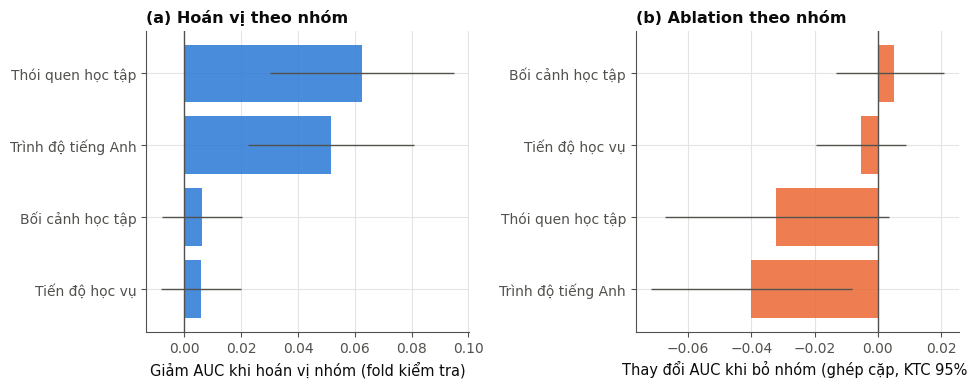

In [58]:
# Hình 5: nhóm tín hiệu (hoán vị và ablation)
fig, axs = plt.subplots(1, 2, figsize=(9.8, 4.0))
pt = perm_tab.sort_values("mean_drop")
axs[0].barh(pt["group"], pt["mean_drop"], xerr=pt["sd_drop"], color=BLUE, alpha=0.85, error_kw={"ecolor": INK2, "lw": 1})
axs[0].axvline(0, color=INK2, lw=1)
axs[0].set_xlabel("Giảm AUC khi hoán vị nhóm (fold kiểm tra)"); axs[0].set_title("(a) Hoán vị theo nhóm", loc="left")
ab = pd.DataFrame(abl_rows)
ab = ab[ab["setting"].str.startswith("Bỏ nhóm")].sort_values("delta_auc")
axs[1].barh([s.replace("Bỏ nhóm: ", "") for s in ab["setting"]], ab["delta_auc"], color=ORANGE, alpha=0.85)
axs[1].errorbar(ab["delta_auc"], range(len(ab)), xerr=[ab["delta_auc"] - ab["lo"], ab["hi"] - ab["delta_auc"]], fmt="none", ecolor=INK2, lw=1)
axs[1].axvline(0, color=INK2, lw=1); axs[1].set_xlabel("Thay đổi AUC khi bỏ nhóm (ghép cặp, KTC 95%)")
axs[1].set_title("(b) Ablation theo nhóm", loc="left")
fig.tight_layout()
save(fig, "f4_05_group_importance.png")

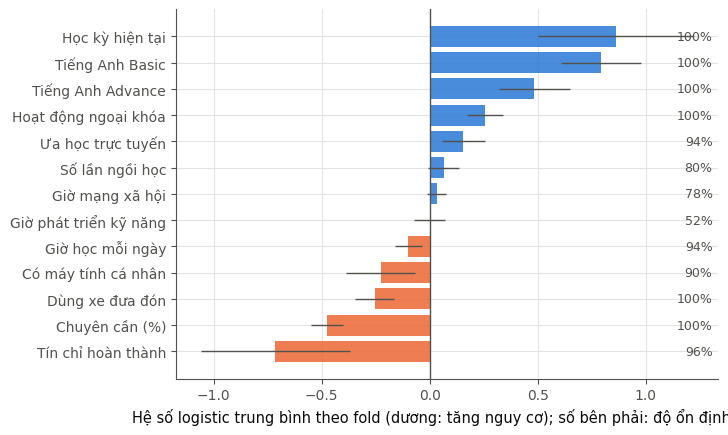

In [59]:
# Hình 6: hệ số logistic theo fold
fig, ax = plt.subplots(figsize=(7.0, 4.8))
ct = coef_tab.sort_values("mean_coef")
colors = [BLUE if v > 0 else ORANGE for v in ct["mean_coef"]]
ax.barh([LABEL[v] for v in ct["variable"]], ct["mean_coef"], xerr=ct["sd_coef"], color=colors, alpha=0.85, error_kw={"ecolor": INK2, "lw": 1})
for i, (v, s_) in enumerate(zip(ct["mean_coef"], ct["sign_stability"])):
    ax.text(ax.get_xlim()[1] * 0.98, i, f"{int(round(s_ * 100))}%", va="center", ha="right", fontsize=9, color=INK2)
ax.axvline(0, color=INK2, lw=1)
ax.set_xlabel("Hệ số logistic trung bình theo fold (dương: tăng nguy cơ); số bên phải: độ ổn định dấu")
save(fig, "f4_06_lr_coefficients.png")

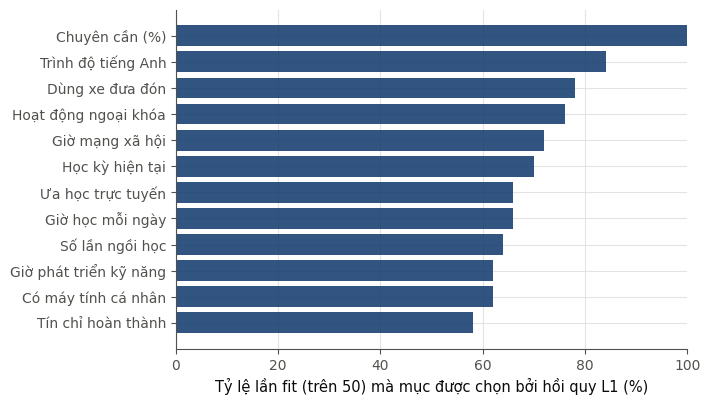

In [60]:
# Hình 9: tần suất chọn mục bởi L1
fig, ax = plt.subplots(figsize=(6.6, 4.4))
sf = sel_freq.sort_values("freq")
ax.barh([LABEL[i] for i in sf["item"]], sf["freq"] * 100, color=BLUE_DARK, alpha=0.85)
ax.set_xlabel("Tỷ lệ lần fit (trên 50) mà mục được chọn bởi hồi quy L1 (%)"); ax.set_xlim(0, 100)
save(fig, "f4_09_l1_selection.png")

### B7. AQ6: kiểm định công bằng theo phân nhóm

Điểm sàng lọc của M1 (trung bình qua các lần lặp, vẫn là điểm ngoài fold) được cắt tại **một ngưỡng chung** cho mọi sinh viên ở tỷ lệ gắn cờ 15% và 30%. Với từng nhóm giới tính và nơi ở, notebook tính tỷ lệ nền, tỷ lệ gắn cờ, recall và precision kèm khoảng tin cậy Wilson. Chênh lệch recall giữa hai nhóm (tinh thần equality of opportunity) có khoảng tin cậy bootstrap; theo tiêu chí S5, nếu khoảng tin cậy rộng hơn 20 điểm phần trăm thì kết luận là chưa kết luận được. Giới tính và nơi ở chỉ được dùng để kiểm tra, không là đặc trưng của mô hình.

In [61]:
# --- 6.8 AQ6: công bằng tại ngưỡng chung
ms = {k: S[k].mean(axis=0) for k in S}           # điểm trung bình các lần lặp (vẫn là điểm ngoài fold)
rng = np.random.default_rng(RANDOM_STATE + 3)
fair_rows, gap_rows = [], []
fair_cols = {"gender": "Giới tính", "living_with": "Nơi ở"}
for rate in FLAG_RATES:
    k_n = ceil(rate * n)
    thr = np.sort(ms["M1"])[::-1][k_n - 1]
    flag = ms["M1"] >= thr
    for col, nm in fair_cols.items():
        levels = sorted(df[col].dropna().unique())
        stats_g = {}
        for lv in levels:
            m = (df[col] == lv).to_numpy()
            tp = int((flag & m & (y == 1)).sum()); pos = int((m & (y == 1)).sum()); fl = int((flag & m).sum()); nn = int(m.sum())
            rlo, rhi = wilson(tp, pos); plo, phi = wilson(tp, fl) if fl else (np.nan, np.nan)
            stats_g[lv] = (tp, pos, fl, nn)
            fair_rows.append({"rate": rate, "attribute": nm, "group": lv, "n": nn, "positives": pos, "base_rate": pos / nn,
                              "flag_rate": fl / nn, "recall": tp / pos, "recall_lo": rlo, "recall_hi": rhi,
                              "precision": tp / fl if fl else np.nan, "precision_lo": plo, "precision_hi": phi,
                              "auc": auc_rank(y[m], ms["M1"][m])})
        a, b = levels[0], levels[1]
        gap = stats_g[a][0] / stats_g[a][1] - stats_g[b][0] / stats_g[b][1]
        bs = []
        ma, mb = (df[col] == a).to_numpy(), (df[col] == b).to_numpy()
        for _ in range(N_BOOT):
            idx = rng.integers(0, n, n)
            ys, ss, aa, bb = y[idx], ms["M1"][idx], ma[idx], mb[idx]
            tt = np.sort(ss)[::-1][k_n - 1]
            fg = ss >= tt
            ra = (fg & aa & (ys == 1)).sum() / max((aa & (ys == 1)).sum(), 1)
            rb = (fg & bb & (ys == 1)).sum() / max((bb & (ys == 1)).sum(), 1)
            bs.append(ra - rb)
        lo, hi = ci(np.array(bs))
        gap_rows.append({"rate": rate, "attribute": nm, "group_a": a, "group_b": b, "gap_recall": float(gap), "lo": lo, "hi": hi,
                         "ci_width": hi - lo, "within_10": bool(abs(gap) <= 0.10), "conclusive": bool((hi - lo) <= 0.20)})
pd.DataFrame(fair_rows).to_csv(TAB / "t4_fairness_groups.csv", index=False)
gaps = pd.DataFrame(gap_rows)
gaps.to_csv(TAB / "t4_fairness_gaps.csv", index=False)
crit["S5"] = gap_rows

display(Markdown("**Chỉ số theo nhóm**"))
display(pd.DataFrame(fair_rows).round(3))
display(Markdown("**Chênh lệch recall giữa các nhóm**"))
display(gaps.round(3))

**Chỉ số theo nhóm**

,rate,attribute,group,n,positives,base_rate,flag_rate,recall,recall_lo,recall_hi,precision,precision_lo,precision_hi,auc
0,0.15,Giới tính,Female,453,71,0.157,0.159,0.310,0.214,0.425,0.306,0.211,0.420,0.636
1,0.15,Giới tính,Male,562,96,0.171,0.144,0.240,0.165,0.334,0.284,0.197,0.390,0.616
2,0.15,Nơi ở,Bachelor,475,96,0.202,0.147,0.250,0.174,0.345,0.343,0.242,0.460,0.603
3,0.15,Nơi ở,Family,540,71,0.131,0.154,0.296,0.202,0.410,0.253,0.172,0.356,0.650
4,0.30,Giới tính,Female,453,71,0.157,0.285,0.451,0.340,0.566,0.248,0.182,0.329,0.636
5,0.30,Giới tính,Male,562,96,0.171,0.313,0.469,0.372,0.568,0.256,0.197,0.325,0.616
6,0.30,Nơi ở,Bachelor,475,96,0.202,0.333,0.479,0.382,0.578,0.291,0.226,0.366,0.603
7,0.30,Nơi ở,Family,540,71,0.131,0.272,0.437,0.327,0.552,0.211,0.153,0.284,0.650


**Chênh lệch recall giữa các nhóm**

,rate,attribute,group_a,group_b,gap_recall,lo,hi,ci_width,within_10,conclusive
0,0.15,Giới tính,Female,Male,0.070,-0.099,0.185,0.284,True,False
1,0.15,Nơi ở,Bachelor,Family,-0.046,-0.175,0.103,0.278,True,False
2,0.30,Giới tính,Female,Male,-0.018,-0.173,0.138,0.311,True,False
3,0.30,Nơi ở,Bachelor,Family,0.043,-0.100,0.211,0.311,True,False


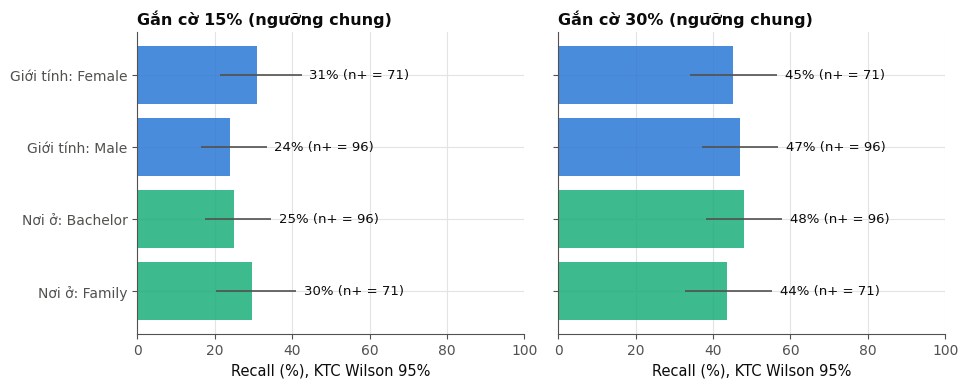

In [62]:
# Hình 7: công bằng
fg = pd.DataFrame(fair_rows)
fig, axs = plt.subplots(1, 2, figsize=(9.8, 4.0), sharey=True)
for ax, rate in zip(axs, FLAG_RATES):
    sub = fg[fg["rate"] == rate].reset_index(drop=True)
    labels = [f"{a}: {g}" for a, g in zip(sub["attribute"], sub["group"])]
    cols_ = [BLUE if a == "Giới tính" else AQUA for a in sub["attribute"]]
    ax.barh(labels, sub["recall"] * 100, color=cols_, alpha=0.85)
    ax.errorbar(sub["recall"] * 100, range(len(sub)), xerr=[(sub["recall"] - sub["recall_lo"]) * 100, (sub["recall_hi"] - sub["recall"]) * 100],
                fmt="none", ecolor=INK2, lw=1.2)
    for i, (r_, nn) in enumerate(zip(sub["recall"], sub["positives"])):
        ax.text(sub["recall_hi"].iloc[i] * 100 + 2, i, f"{r_ * 100:.0f}% (n+ = {nn})", va="center", fontsize=9.5, color=INK)
    ax.set_xlim(0, 100); ax.set_title(f"Gắn cờ {int(rate * 100)}% (ngưỡng chung)", loc="left"); ax.set_xlabel("Recall (%), KTC Wilson 95%")
axs[0].invert_yaxis()
fig.tight_layout()
save(fig, "f4_07_fairness.png")

### B8. AQ2 và AQ3: mô hình hiệu chỉnh

Với từng đặc trưng, notebook ước lượng OR không hiệu chỉnh (mô hình một biến) và OR hiệu chỉnh trong ba mô hình: A gồm thói quen học tập và học kỳ, B gồm các biến bối cảnh của AQ3, C gồm toàn bộ đặc trưng trừ số tín chỉ (bỏ để tránh cộng tuyến với học kỳ). Giá trị p của mô hình C được hiệu chỉnh Holm. Kết quả chỉ diễn giải ở mức **liên hệ**: dữ liệu không có can thiệp nên không cho phép kết luận rằng thay đổi một thói quen sẽ thay đổi kết quả học tập.

In [63]:
# --- 6.9 AQ2 và AQ3: mô hình hiệu chỉnh và liên hệ không hiệu chỉnh
uni = pd.concat([logit_wald(X, y, [c]).assign(model="unadjusted") for c in CORE_FEATURES], ignore_index=True)
A_cols = GROUPS["Thói quen học tập"] + ["semester_capped"]
B_cols = ["learning_mode_online", "has_pc", "uses_transport", "english_basic", "english_advance", "semester_capped", "cocurricular"]
C_cols = [c for c in CORE_FEATURES if c != "credits_completed"]
adj = pd.concat([logit_wald(X, y, A_cols).assign(model="A: AQ2 + học kỳ"), logit_wald(X, y, B_cols).assign(model="B: AQ3"),
                 logit_wald(X, y, C_cols).assign(model="C: đầy đủ, không có tín chỉ")], ignore_index=True)
adj.loc[adj.model == "C: đầy đủ, không có tín chỉ", "p_holm"] = holm(adj.loc[adj.model == "C: đầy đủ, không có tín chỉ", "p"].tolist())
pd.concat([uni, adj], ignore_index=True).to_csv(TAB / "t4_adjusted_models.csv", index=False)

display(adj[adj.model.str.startswith("C")].round(4))

,variable,or,lo,hi,p,model,p_holm
13,study_hours,0.9409,0.7767,1.1399,0.5339,"C: đầy đủ, không có tín chỉ",1.0000
14,study_sessions,1.0147,0.8407,1.2246,0.8795,"C: đầy đủ, không có tín chỉ",1.0000
15,attendance_pct,0.7053,0.6087,0.8172,0.0000,"C: đầy đủ, không có tín chỉ",0.0000
16,social_hours,1.0331,0.8749,1.2198,0.7011,"C: đầy đủ, không có tín chỉ",1.0000
17,skill_hours,0.9715,0.8102,1.1648,0.7547,"C: đầy đủ, không có tín chỉ",1.0000
18,learning_mode_online,1.1744,0.8066,1.7100,0.4016,"C: đầy đủ, không có tín chỉ",1.0000
19,has_pc,0.7454,0.4168,1.3329,0.3217,"C: đầy đủ, không có tín chỉ",1.0000
20,uses_transport,0.8057,0.5632,1.1527,0.2371,"C: đầy đủ, không có tín chỉ",1.0000
21,english_basic,2.2998,1.5227,3.4736,0.0001,"C: đầy đủ, không có tín chỉ",0.0008
22,english_advance,1.5347,0.9829,2.3963,0.0596,"C: đầy đủ, không có tín chỉ",0.5956


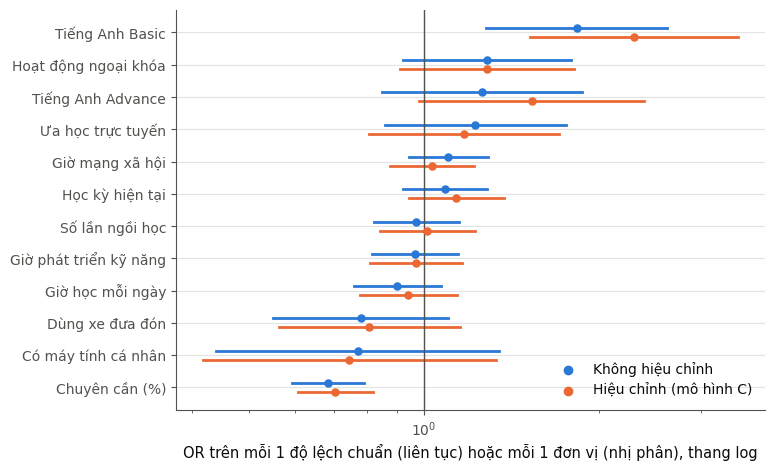

In [64]:
# Hình 8: OR không hiệu chỉnh và hiệu chỉnh
fig, ax = plt.subplots(figsize=(7.6, 5.2))
cc = adj[adj.model.str.startswith("C")].set_index("variable")
un = uni.set_index("variable")
order = [c for c in un.sort_values("or").index if c in cc.index]
for i, c in enumerate(order):
    ax.plot([un.loc[c, "lo"], un.loc[c, "hi"]], [i + 0.14, i + 0.14], color=BLUE, lw=2)
    ax.scatter(un.loc[c, "or"], i + 0.14, color=BLUE, s=26, zorder=3)
    ax.plot([cc.loc[c, "lo"], cc.loc[c, "hi"]], [i - 0.14, i - 0.14], color=ORANGE, lw=2)
    ax.scatter(cc.loc[c, "or"], i - 0.14, color=ORANGE, s=26, zorder=3)
ax.axvline(1, color=INK2, lw=1)
ax.set_xscale("log"); ax.set_yticks(range(len(order))); ax.set_yticklabels([LABEL[c] for c in order])
ax.set_xlabel("OR trên mỗi 1 độ lệch chuẩn (liên tục) hoặc mỗi 1 đơn vị (nhị phân), thang log")
ax.scatter([], [], color=BLUE, label="Không hiệu chỉnh"); ax.scatter([], [], color=ORANGE, label="Hiệu chỉnh (mô hình C)")
ax.legend(loc="lower right", frameon=False)
save(fig, "f4_08_adjusted_or.png")

### B9. Phân tích độ nhạy và lưu điểm ngoài fold

Phân tích độ nhạy lặp lại B1 và M1 với hai ngưỡng nhãn khác (2,50 và 3,00) và trên mẫu độ nhạy B (giữ 140 dòng thuộc cặp lặp), để kiểm tra kết luận có phụ thuộc vào ngưỡng hoặc vào quyết định loại cặp lặp ở Milestone 3 hay không. Sau đó, điểm ngoài fold của các mô hình, cờ gắn tại 15% và 30% và thứ hạng ưu tiên được lưu thành `oof_predictions_m4.csv`, làm nguồn dữ liệu cho dashboard ở Milestone 5.

In [65]:
# --- 6.10 Độ nhạy: nhãn 2,50 và 3,00; mẫu B
sens_rows = []
for tgt in ("y_lt_2_50", "y_lt_2_75", "y_lt_3_00"):
    dft = pd.read_csv(data_path)
    yt = dft[tgt].to_numpy().astype(int)
    sp = split_list(dft[CORE_FEATURES], yt)
    for key, cols in (("B1", ["attendance_pct"]), ("M1", None)):
        Ss, _, _ = run_cv(key, dft[CORE_FEATURES], yt, sp, cols=cols)
        mv = metric_vector(yt, Ss)
        sens_rows.append({"sample": "Mẫu chính", "target": tgt, "model": key, "positives": int(yt.sum()), "AUC": float(mv[0]),
                          "recall_15": float(mv[1]), "recall_30": float(mv[2])})
master = pd.read_csv(ROOT / "data" / "processed" / "m3_analytic_master.csv")
mb = master[master["in_sensitivity_B"] == 1].reset_index(drop=True)
yb = mb[PRIMARY_TARGET].to_numpy().astype(int)
spb = split_list(mb[CORE_FEATURES], yb)
for key, cols in (("B1", ["attendance_pct"]), ("M1", None)):
    Ss, _, _ = run_cv(key, mb[CORE_FEATURES], yb, spb, cols=cols)
    mv = metric_vector(yb, Ss)
    sens_rows.append({"sample": "Mẫu độ nhạy B", "target": PRIMARY_TARGET, "model": key, "positives": int(yb.sum()), "AUC": float(mv[0]),
                      "recall_15": float(mv[1]), "recall_30": float(mv[2])})
pd.DataFrame(sens_rows).to_csv(TAB / "t4_sensitivity.csv", index=False)

display(pd.DataFrame(sens_rows).round(3))

,sample,target,model,positives,AUC,recall_15,recall_30
0,Mẫu chính,y_lt_2_50,B1,52,0.540,0.150,0.326
1,Mẫu chính,y_lt_2_50,M1,52,0.686,0.358,0.602
2,Mẫu chính,y_lt_2_75,B1,167,0.604,0.229,0.442
3,Mẫu chính,y_lt_2_75,M1,167,0.621,0.262,0.457
4,Mẫu chính,y_lt_3_00,B1,311,0.637,0.234,0.459
5,Mẫu chính,y_lt_3_00,M1,311,0.650,0.258,0.461
6,Mẫu độ nhạy B,y_lt_2_75,B1,167,0.604,0.256,0.451
7,Mẫu độ nhạy B,y_lt_2_75,M1,167,0.621,0.274,0.463


In [66]:
# --- 6.11 Lưu điểm ngoài fold (phục vụ Milestone 5 và dashboard)
oof = pd.DataFrame({"rid": df["rid"], "y_lt_2_75": y, "score_M1": ms["M1"], "score_B1": ms["B1"], "score_M2": ms["M2"], "score_M3": ms["M3"],
                    "prob_M1_corrected": Pc["M1"].mean(axis=0), "gender": df["gender"], "living_with": df["living_with"]})
for rate in FLAG_RATES:
    thr = np.sort(ms["M1"])[::-1][ceil(rate * n) - 1]
    oof[f"flag_{int(rate * 100)}"] = (ms["M1"] >= thr).astype(int)
oof["risk_rank"] = oof["score_M1"].rank(ascending=False, method="first").astype(int)
oof.to_csv(OUT / "oof_predictions_m4.csv", index=False)

display(oof.head())

,rid,y_lt_2_75,score_M1,score_B1,score_M2,score_M3,prob_M1_corrected,gender,living_with,flag_15,flag_30,risk_rank
0,8,0,0.509527,0.488391,0.440175,0.435254,0.170612,Female,Bachelor,0,0,373
1,12,0,0.552604,0.496035,0.527193,0.559720,0.196375,Male,Bachelor,0,1,258
2,16,0,0.529662,0.492264,0.439682,0.373526,0.182507,Male,Family,0,0,313
3,19,0,0.639163,0.511689,0.422922,0.221056,0.260409,Male,Family,1,1,110
4,21,0,0.392322,0.491800,0.292648,0.295018,0.113291,Female,Bachelor,0,0,682


### B10. Tổng hợp kết quả và nhật ký thực nghiệm

Ô dưới đây lưu `results_m4.json` (mọi con số được dùng ở Mục 7 của báo cáo) và `experiment_log_m4.json` (phiên bản thư viện, hạt giống, mã băm dữ liệu, kế hoạch và từng bảng đầu ra, thời gian chạy).

In [67]:
R["criteria"] = crit
R["main_ranking"] = main_tab[["key", "AUC", "AUC_lo", "AUC_hi", "recall_30", "recall_30_lo", "recall_30_hi", "recall_15", "pr_auc"]].to_dict(orient="records")
R["items_reduced"] = items_in
with open(OUT / "results_m4.json", "w", encoding="utf-8") as f:
    json.dump(R, f, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
log["thoi_gian_chay_giay"] = round(time.time() - t0, 1)
log["ket_thuc_utc"] = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S")
log["sha256_dau_ra"] = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(TAB.glob("*.csv"))}
with open(OUT / "experiment_log_m4.json", "w", encoding="utf-8") as f:
    json.dump(log, f, ensure_ascii=False, indent=2)
print("Hoàn tất thực nghiệm Level 2:", len(list(FIG.glob("*.png"))), "hình,", len(list(TAB.glob("*.csv"))), "bảng, thời gian", log["thoi_gian_chay_giay"], "giây")

Hoàn tất thực nghiệm Level 2: 9 hình, 17 bảng, thời gian 332.3 giây


#### B10.1. Bảng chấm tiêu chí thành công

Bảng chấm đọc trực tiếp từ kết quả vừa tính, đối chiếu với các tiêu chí đã đăng ký trước ở Mục 2.2.

In [68]:
c = R["criteria"]
m1_row = main_tab.set_index("key").loc["M1"]
s5_ok = all(g["within_10"] for g in c["S5"])
s5_conclusive = all(g["conclusive"] for g in c["S5"])
score = pd.DataFrame([
    ("S1", "AUC ≥ 0,70 và recall ≥ 60% tại 30%",
     f"AUC {m1_row['AUC']:.3f}; recall {m1_row['recall_30']:.1%}",
     "Đạt" if c["S1_AUC_point"] and c["S1_recall30_point"] else "Không đạt"),
    ("S1b", "Báo cáo recall tại 15% (tham chiếu 60%)", f"recall {c['S1b_recall15']:.1%}",
     "Đạt" if c["S1b_recall15"] >= 0.60 else "Không đạt"),
    ("S2", "ΔAUC so với B1 ≥ 0,03 và cận dưới KTC > 0", f"ΔAUC {c['S2_delta_auc']:.3f}",
     "Đạt" if c["S2_met"] else "Không đạt"),
    ("S3", "≤ 8 mục và AUC giảm ≤ 0,02",
     f"{R['S3']['items_mean']:.2f} mục; AUC giảm {abs(R['S3']['delta']):.3f}", "Đạt" if R["S3"]["met"] else "Không đạt"),
    ("S4", "Độ dốc hiệu chuẩn trong [0,8; 1,2] và Brier thấp hơn tỷ lệ nền", f"độ dốc {c['S4_slope']:.2f}",
     "Đạt" if c["S4_met"] else "Không đạt"),
    ("S5", "Chênh lệch recall ≤ 10 điểm, KTC không rộng quá 20 điểm",
     f"điểm ước lượng {'≤' if s5_ok else '>'} 10 điểm; KTC rộng nhất {max(g['ci_width'] for g in c['S5']):.0%}",
     "Đạt" if s5_ok and s5_conclusive else ("Chưa kết luận được" if s5_ok else "Không đạt")),
    ("Quy tắc chọn", "Mô hình cây vượt ≥ 0,03 và cận dưới > 0",
     "; ".join(f"{r['model']} {r['delta']:+.3f} [{r['lo']:.3f}; {r['hi']:.3f}]" for r in c["primary_rule"]),
     "Đổi phương pháp chính" if any(r["switch"] for r in c["primary_rule"]) else "Giữ hồi quy logistic"),
], columns=["Mã", "Tiêu chí đăng ký trước", "Kết quả quan sát", "Kết luận"])
score["Kết quả quan sát"] = score["Kết quả quan sát"].str.replace(".", ",", regex=False)   # dấu thập phân kiểu Việt Nam
display(score)

,Mã,Tiêu chí đăng ký trước,Kết quả quan sát,Kết luận
0,S1,"AUC ≥ 0,70 và recall ≥ 60% tại 30%","AUC 0,621; recall 45,7%",Không đạt
1,S1b,Báo cáo recall tại 15% (tham chiếu 60%),"recall 26,2%",Không đạt
2,S2,"ΔAUC so với B1 ≥ 0,03 và cận dưới KTC > 0","ΔAUC 0,017",Không đạt
3,S3,"≤ 8 mục và AUC giảm ≤ 0,02","8,58 mục; AUC giảm 0,007",Không đạt
4,S4,"Độ dốc hiệu chuẩn trong [0,8; 1,2] và Brier thấp hơn tỷ lệ nền","độ dốc 0,70",Không đạt
5,S5,"Chênh lệch recall ≤ 10 điểm, KTC không rộng quá 20 điểm",điểm ước lượng ≤ 10 điểm; KTC rộng nhất 31%,Chưa kết luận được
6,Quy tắc chọn,"Mô hình cây vượt ≥ 0,03 và cận dưới > 0","M2 +0,017 [-0,016; 0,050]; M3 +0,016 [-0,024; 0,058]",Giữ hồi quy logistic


#### B10.2. Đối chiếu với kết quả trong báo cáo

Ô cuối so sánh mã băm từng bảng đầu ra với gói dữ liệu đã nộp kèm báo cáo, và so sánh các chỉ số chính với giá trị trong báo cáo (sai lệch cho phép 0,005). Tệp điểm ngoài fold không được so từng byte vì Random Forest cộng xác suất của các cây song song, nên chữ số thập phân thứ 16 có thể khác giữa hai lần chạy mà không ảnh hưởng đến bất kỳ bảng hay chỉ số nào. Kết quả trong báo cáo được tạo với scikit-learn 1.9.1; nếu Colab dùng phiên bản khác, một số bảng có thể không trùng từng byte do khác biệt số học rất nhỏ giữa các phiên bản, trong khi các chỉ số chính vẫn nằm trong sai lệch cho phép và kết luận không đổi.

In [69]:
EXPECTED_SHA256 = {
    "reports/milestone4/tables/t4_ablation.csv": "2822af3485059f5fa9566d93acf5a5c2d05f39fa8b072259c1b0cc36996c0cf6",
    "reports/milestone4/tables/t4_adjusted_models.csv": "a8aeca59b054d75e0a37b5c51aaffece8a575e7a89d7555aa64f4fbead0d0e3b",
    "reports/milestone4/tables/t4_auc_by_repeat.csv": "b2a13d59a4eeec5d678b67500f7dd16811340cbfa90b26378c1b3e5a114947a2",
    "reports/milestone4/tables/t4_b0_reference.csv": "05bf9a086dcd4b0554c86298ff638f63c6eb9717eb88336759981bf537c8c417",
    "reports/milestone4/tables/t4_calibration.csv": "b0e01da01e4871f377798e0e7d9352e1e89d507712b25cc2bd80a2dc90e60625",
    "reports/milestone4/tables/t4_capacity_curve.csv": "3e76ed294956ded04e7188abcadc3b76bc2950b428ba7bde03eb29e36e4bb362",
    "reports/milestone4/tables/t4_fairness_gaps.csv": "8ffe968c41f5163d202ec3caafc9af7fa7e1dbccd6b033876609668af138eb93",
    "reports/milestone4/tables/t4_fairness_groups.csv": "3a0cdebc97506265cafebff76035bb50d9d9b7d3fd33b4b96c99ffad8bf54246",
    "reports/milestone4/tables/t4_l1_selection_frequency.csv": "cf1a6c9816ce6a4a540303e655b9398c05713a98c23d7348dae3af9361512359",
    "reports/milestone4/tables/t4_lr_coefficients.csv": "be1c32eede48d8ae8d7b1589e45af92ca524f45df5415b61b6a92187e081ee47",
    "reports/milestone4/tables/t4_main_results.csv": "7add753f2744863dc4f4f05dbc2cfad4015362a12f757b622302c28d56b54210",
    "reports/milestone4/tables/t4_operating_points.csv": "a4d0f78beae0b224cca7cec1e776b46cd00ed6ee111b338593deca8b0279eced",
    "reports/milestone4/tables/t4_paired_deltas.csv": "0f92ecc8c523d73201b66530e7c1fed05b19c749c38bb07488f414df6ad15a27",
    "reports/milestone4/tables/t4_permutation_importance.csv": "50e12c16199aeb4c1dd65481421008de89d653227b718ce00d431d3b8eaa627d",
    "reports/milestone4/tables/t4_reliability.csv": "83c48517c4c3d1d77b63607cf841fed18daeeb6fddd2b5459dc247924aeaa363",
    "reports/milestone4/tables/t4_reliability_m1_corrected.csv": "e07a10a7de0934008c9634230db0001a33d086652f2452d94573d404bda887ee",
    "reports/milestone4/tables/t4_sensitivity.csv": "3ce4017802ae7d63e0d7463a531b6654c7bfdb5b3a5fb54822f23d011330b8ad",
}
REPORTED = {"B1": {"AUC": 0.6041, "recall_30": 0.4416, "recall_15": 0.2293}, "M1": {"AUC": 0.6212, "recall_30": 0.4569, "recall_15": 0.2617}, "M2": {"AUC": 0.638, "recall_30": 0.4509, "recall_15": 0.2455}, "M3": {"AUC": 0.637, "recall_30": 0.4485, "recall_15": 0.2407}, "S1": {"AUC": 0.614, "recall_30": 0.4469, "recall_15": 0.2632}}

same = sum((ROOT / rel).exists() and hashlib.sha256((ROOT / rel).read_bytes()).hexdigest() == h
           for rel, h in EXPECTED_SHA256.items())
print(f"Bảng trùng từng byte với gói đã nộp: {same}/{len(EXPECTED_SHA256)}")

rows = []
for r in main_tab.itertuples():
    for k in ("AUC", "recall_30", "recall_15"):
        got, rep = float(getattr(r, k)), REPORTED[r.key][k]
        rows.append({"Mô hình": r.key, "Chỉ số": k, "Notebook": round(got, 4), "Báo cáo": rep,
                     "Khớp (sai lệch ≤ 0,005)": abs(got - rep) <= 0.005})
cmp_tab = pd.DataFrame(rows)
display(cmp_tab)
n_lech = int((~cmp_tab["Khớp (sai lệch ≤ 0,005)"]).sum())
if n_lech == 0:
    print("Các chỉ số chính khớp với báo cáo Milestone 4.")
else:
    print(f"Có {n_lech} chỉ số lệch quá 0,005 so với báo cáo: thường do phiên bản scikit-learn trên Colab khác; xem bảng trên.")

Bảng trùng từng byte với gói đã nộp: 7/17


,Mô hình,Chỉ số,Notebook,Báo cáo,"Khớp (sai lệch ≤ 0,005)"
0,B1,AUC,0.6041,0.6041,True
1,B1,recall_30,0.4416,0.4416,True
2,B1,recall_15,0.2293,0.2293,True
3,M1,AUC,0.6212,0.6212,True
4,M1,recall_30,0.4569,0.4569,True
5,M1,recall_15,0.2617,0.2617,True
6,M2,AUC,0.6382,0.6380,True
7,M2,recall_30,0.4521,0.4509,True
8,M2,recall_15,0.2479,0.2455,True
9,M3,AUC,0.6370,0.6370,True


Các chỉ số chính khớp với báo cáo Milestone 4.


### B11. Kết luận

* **AQ4.** Mô hình chính (hồi quy logistic L2 có trọng số lớp) đạt AUC khoảng 0,62 và recall khoảng 46% tại tỷ lệ gắn cờ 30%, chỉ cao hơn baseline chuyên cần (AUC khoảng 0,60) một khoảng nhỏ với khoảng tin cậy ghép cặp chứa 0. Hai mô hình cây không vượt hồi quy logistic theo quy tắc đã đăng ký, nên phương pháp chính được giữ nguyên.
* **AQ7.** Đạt recall 60% đòi hỏi gắn cờ gần một nửa số sinh viên, vượt xa trần 30% của Đề cương và trần 15% của Milestone 1.
* **AQ5.** Tín hiệu tập trung ở nhóm thói quen học tập (đặc biệt chuyên cần) và trình độ tiếng Anh; L1 trong fold giữ trung bình hơn 8 mục nên tiêu chí S3 chưa đạt theo quy tắc nghiêm ngặt.
* **AQ6.** Chênh lệch recall điểm ước lượng nhỏ hơn 10 điểm nhưng khoảng tin cậy rất rộng, nên kết luận là chưa kết luận được.
* **AQ2, AQ3.** Sau khi hiệu chỉnh, chuyên cần vẫn là liên hệ mạnh nhất và trình độ tiếng Anh cơ bản vẫn liên hệ thuận với nhóm cần hỗ trợ; đây là liên hệ, không phải nhân quả.

Tiêu chí S1, S2, S3 và S4 không đạt; S5 chưa kết luận được. Đây là **kết quả phủ định có bằng chứng**: phiếu khảo sát tự báo cáo một mình chưa đủ giá trị sàng lọc ở mức Đề cương kỳ vọng. Claim của dự án được hạ thành công cụ hỗ trợ sắp xếp ưu tiên bổ trợ cho cố vấn học tập, và hướng cải thiện là bổ sung dữ liệu hành vi học tập, điểm đầu kỳ hoặc thêm một khóa để có tập kiểm tra độc lập. Các bảng `t4_*.csv` và `oof_predictions_m4.csv` là nguồn dữ liệu cho dashboard Tableau Public ở Milestone 5.

## PHẦN C. Tích hợp và truy vết (Milestone 5)

### C1. Đối chiếu số liệu của báo cáo cuối kỳ

Các ô dưới đây đọc những bảng và tệp kết quả **vừa được Phần A và Phần B tạo ra**, rồi so từng con số được trích trong báo cáo `N02_MilestoneP5.docx` (62 hạng mục) với dung sai làm tròn. Bốn hạng mục cuối kiểm tra tính toàn vẹn bằng mã băm SHA-256 (tệp gốc, bảng mô hình, kế hoạch đăng ký trước, 17 bảng kết quả). Kết quả được lưu ở `reports/milestone5/verification_report_m5.csv`.

In [70]:
root = ROOT


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


m3 = root / "reports/milestone3"
m4 = root / "reports/milestone4"
meta = root / "data/metadata"
T3, T4 = m3 / "tables", m4 / "tables"
results = json.loads((m4 / "results_m4.json").read_text(encoding="utf-8"))
log4 = json.loads((m4 / "experiment_log_m4.json").read_text(encoding="utf-8"))
eda = json.loads((m3 / "eda_results.json").read_text(encoding="utf-8"))
val = json.loads((meta / "validation_summary_m3.json").read_text(encoding="utf-8"))

main_t = pd.read_csv(T4 / "t4_main_results.csv").set_index("key")
pair = pd.read_csv(T4 / "t4_paired_deltas.csv")
cal = pd.read_csv(T4 / "t4_calibration.csv")
ops = pd.read_csv(T4 / "t4_operating_points.csv").set_index("rate")
perm = pd.read_csv(T4 / "t4_permutation_importance.csv").set_index("group")
abl = pd.read_csv(T4 / "t4_ablation.csv").set_index("setting")
gaps = pd.read_csv(T4 / "t4_fairness_gaps.csv")
fair = pd.read_csv(T4 / "t4_fairness_groups.csv")
adj = pd.read_csv(T4 / "t4_adjusted_models.csv")
sens = pd.read_csv(T4 / "t4_sensitivity.csv")
prev = pd.read_csv(T3 / "t_aq1_prevalence.csv")
aq2 = pd.read_csv(T3 / "t_aq2_numeric.csv").set_index("variable")
aq3b = pd.read_csv(T3 / "t_aq3_binary.csv").set_index("variable")
bins = pd.read_csv(T3 / "t_aq2_attendance_bins.csv")

In [71]:
checks = []

def chk(label, observed, expected, tol):
    ok = abs(float(observed) - float(expected)) <= tol
    checks.append((label, float(observed), float(expected), tol, ok))

# --- Dữ liệu và nhãn (Milestone 3)
chk("Số sinh viên mẫu chính", val["rows_primary"], 1015, 0)
chk("Số ca dương CGPA < 2,75", val["primary_y_lt_2_75_positives"], 167, 0)
chk("Số sinh viên mẫu B", val["rows_sensB"], 1155, 0)
p = prev[prev["sample"].str.startswith("Mẫu chính")].set_index("threshold")
chk("Tỷ lệ ca dương CGPA < 2,75 (%)", p.loc[2.75, "rate"] * 100, 16.5, 0.05)
chk("Tỷ lệ dưới 2,50 (%)", p.loc[2.5, "rate"] * 100, 5.1, 0.05)
chk("Tỷ lệ dưới 3,00 (%)", p.loc[3.0, "rate"] * 100, 30.6, 0.05)
chk("CGPA = 0 (số phiếu)", eda["cgpa_zero"]["n"], 39, 0)
chk("CGPA trung bình mẫu chính", eda["cgpa_primary"]["mean"], 3.29, 0.005)
chk("PS chuyên cần", aq2.loc["attendance_pct", "ps"], 0.395, 0.0005)
chk("PS chuyên cần, cận dưới", aq2.loc["attendance_pct", "ps_lo"], 0.347, 0.0005)
chk("PS chuyên cần, cận trên", aq2.loc["attendance_pct", "ps_hi"], 0.442, 0.0005)
chk("Nhóm chuyên cần < 70 (% ca dương)", bins.iloc[0]["rate"] * 100, 33.7, 0.05)
chk("Nhóm chuyên cần 95 đến 100 (% ca dương)", bins.iloc[-1]["rate"] * 100, 11.8, 0.05)
chk("OR Mantel-Haenszel tiếng Anh cơ bản", aq3b.loc["english_basic_vs_inter", "or_mh"], 2.36, 0.005)

# --- Thực nghiệm Level 2 (Milestone 4)
for key, auc, lo, hi in [("M1", 0.621, 0.574, 0.667), ("B1", 0.604, 0.555, 0.651)]:
    chk(f"AUC {key}", main_t.loc[key, "AUC"], auc, 0.0006)
    chk(f"AUC {key}, cận dưới", main_t.loc[key, "AUC_lo"], lo, 0.0006)
    chk(f"AUC {key}, cận trên", main_t.loc[key, "AUC_hi"], hi, 0.0006)
chk("AUC Random Forest", main_t.loc["M2", "AUC"], 0.638, 0.0006)
chk("AUC Gradient Boosting", main_t.loc["M3", "AUC"], 0.637, 0.0006)
chk("AUC L1 trong fold", main_t.loc["S1", "AUC"], 0.614, 0.0006)
chk("Recall 30% của M1 (%)", main_t.loc["M1", "recall_30"] * 100, 45.7, 0.05)
chk("Recall 15% của M1 (%)", main_t.loc["M1", "recall_15"] * 100, 26.2, 0.05)
chk("Precision 30% của M1 (%)", main_t.loc["M1", "precision_30"] * 100, 25.0, 0.05)
d = pair[(pair["cap"] == "M1 so với B1") & (pair["metric"] == "AUC")].iloc[0]
chk("ΔAUC M1 so với B1", d["delta"], 0.017, 0.0006)
chk("ΔAUC M1 so với B1, cận dưới", d["lo"], -0.021, 0.0006)
chk("ΔAUC M1 so với B1, cận trên", d["hi"], 0.056, 0.0006)
for row in results["criteria"]["primary_rule"]:
    chk(f"ΔAUC {row['model']} so với M1", row["delta"], 0.017 if row["model"] == "M2" else 0.016, 0.0006)
    checks.append((f"Quy tắc chuyển primary, {row['model']} (switch phải là False)", float(row["switch"]), 0.0, 0.0, row["switch"] is False))
chk("Độ dốc hiệu chuẩn M1 không trọng số", cal.iloc[0]["slope"], 0.696, 0.0006)
chk("Độ dốc hiệu chuẩn M1 sau hiệu chỉnh", cal.iloc[1]["slope"], 0.668, 0.0006)
chk("Brier M1", cal.iloc[0]["brier"], 0.1350, 0.00006)
chk("Brier tỷ lệ nền", cal.iloc[2]["brier"], 0.1375, 0.00006)
chk("Recall tại 5% gắn cờ (%)", ops.loc[0.05, "recall_M1"] * 100, 9.2, 0.05)
chk("Recall tại 45% gắn cờ (%)", ops.loc[0.45, "recall_M1"] * 100, 60.4, 0.05)
chk("Recall tại 50% gắn cờ (%)", ops.loc[0.5, "recall_M1"] * 100, 64.1, 0.05)
chk("Hoán vị, nhóm thói quen", perm.loc["Thói quen học tập", "mean_drop"], 0.063, 0.0006)
chk("Hoán vị, nhóm tiếng Anh", perm.loc["Trình độ tiếng Anh", "mean_drop"], 0.052, 0.0006)
chk("Ablation, bỏ nhóm thói quen", abl.loc["Bỏ nhóm: Thói quen học tập", "delta_auc"], -0.032, 0.0006)
chk("Ablation, bỏ nhóm tiếng Anh", abl.loc["Bỏ nhóm: Trình độ tiếng Anh", "delta_auc"], -0.040, 0.0006)
chk("Số mục L1 giữ lại (trung bình)", results["l1_items_mean"], 8.58, 0.005)
chk("AUC bộ ba mục R3", abl.loc["R3 (chuyên cần, tiếng Anh, học kỳ)", "auc"], 0.638, 0.0006)
c_models = adj[adj["model"].str.startswith("C")].set_index("variable")
chk("OR hiệu chỉnh chuyên cần", c_models.loc["attendance_pct", "or"], 0.71, 0.005)
chk("OR hiệu chỉnh tiếng Anh cơ bản", c_models.loc["english_basic", "or"], 2.30, 0.005)
chk("Chênh lệch recall nhỏ nhất (điểm)", gaps["gap_recall"].min() * 100, -4.6, 0.05)
chk("Chênh lệch recall lớn nhất (điểm)", gaps["gap_recall"].max() * 100, 7.0, 0.05)
chk("KTC chênh lệch hẹp nhất (điểm)", gaps["ci_width"].min() * 100, 27.8, 0.05)
chk("KTC chênh lệch rộng nhất (điểm)", gaps["ci_width"].max() * 100, 31.1, 0.05)
fam = fair[(fair["attribute"] == "Nơi ở") & (fair["rate"] == 0.15)].set_index("group")
chk("Tỷ lệ nền nhóm Bachelor (%)", fam.loc["Bachelor", "base_rate"] * 100, 20.2, 0.05)
chk("Tỷ lệ nền nhóm Family (%)", fam.loc["Family", "base_rate"] * 100, 13.1, 0.05)
s = sens.set_index(["sample", "target", "model"])
chk("AUC M1 ở nhãn 2,50", s.loc[("Mẫu chính", "y_lt_2_50", "M1"), "AUC"], 0.686, 0.0006)
chk("Recall 30% của M1 ở nhãn 2,50 (%)", s.loc[("Mẫu chính", "y_lt_2_50", "M1"), "recall_30"] * 100, 60.2, 0.05)
chk("AUC M1 ở nhãn 3,00", s.loc[("Mẫu chính", "y_lt_3_00", "M1"), "AUC"], 0.650, 0.0006)
chk("AUC B1 ở nhãn 3,00", s.loc[("Mẫu chính", "y_lt_3_00", "B1"), "AUC"], 0.637, 0.0006)

In [72]:
# --- Toàn vẹn
plan = m4 / "evaluation_plan_prereg.json"
plan_ok = sha256(plan) == (m4 / "evaluation_plan_prereg.sha256").read_text().strip() == log4["prereg_sha256"]
checks.append(("SHA-256 kế hoạch đăng ký trước khớp nhật ký chạy", 1.0, 1.0, 0.0, plan_ok))
data_ok = sha256(root / "data/processed/m3_analytic_primary_model.csv") == log4["data_sha256"]
checks.append(("SHA-256 Prepared Dataset v1.0 khớp nhật ký chạy", 1.0, 1.0, 0.0, data_ok))
raw = root / "data/raw/Students_Performance_data_set.xlsx"
raw_ok = sha256(raw) == val["raw_sha256"]
checks.append(("SHA-256 tệp thô khớp validation_summary_m3.json", 1.0, 1.0, 0.0, raw_ok))
out_ok = all(sha256(T4 / name) == digest for name, digest in log4["sha256_dau_ra"].items())
checks.append(("SHA-256 17 bảng t4_*.csv khớp nhật ký thực nghiệm", 1.0, 1.0, 0.0, out_ok))

In [73]:
rep = pd.DataFrame(checks, columns=["Hạng mục", "Quan sát", "Giá trị trong báo cáo", "Dung sai", "Đạt"])
out_dir = ROOT / "reports/milestone5"
out_dir.mkdir(parents=True, exist_ok=True)
rep.to_csv(out_dir / "verification_report_m5.csv", index=False, encoding="utf-8-sig")
display(rep.style.format({"Quan sát": "{:.4f}", "Giá trị trong báo cáo": "{:.4f}", "Dung sai": "{:.4f}"}))
n_fail = int((~rep["Đạt"]).sum())
if n_fail == 0:
    display(Markdown(f"**Tổng số kiểm tra: {len(rep)}; không đạt: 0. Mọi số liệu trong báo cáo khớp với kết quả vừa chạy lại.**"))
else:
    display(Markdown(f"**Tổng số kiểm tra: {len(rep)}; không đạt: {n_fail}.** Các hạng mục không đạt nằm trong bảng trên; "
                     "thường do phiên bản thư viện trên Colab khác phiên bản đã dùng khi viết báo cáo (pandas 3.0, scikit-learn 1.9)."))
    display(rep[~rep["Đạt"]])

,Hạng mục,Quan sát,Giá trị trong báo cáo,Dung sai,Đạt
0,Số sinh viên mẫu chính,1015.0000,1015.0000,0.0000,True
1,"Số ca dương CGPA < 2,75",167.0000,167.0000,0.0000,True
2,Số sinh viên mẫu B,1155.0000,1155.0000,0.0000,True
3,"Tỷ lệ ca dương CGPA < 2,75 (%)",16.4532,16.5000,0.0500,True
4,"Tỷ lệ dưới 2,50 (%)",5.1232,5.1000,0.0500,True
5,"Tỷ lệ dưới 3,00 (%)",30.6404,30.6000,0.0500,True
6,CGPA = 0 (số phiếu),39.0000,39.0000,0.0000,True
7,CGPA trung bình mẫu chính,3.2894,3.2900,0.0050,True
8,PS chuyên cần,0.3947,0.3950,0.0005,True
9,"PS chuyên cần, cận dưới",0.3471,0.3470,0.0005,True


**Tổng số kiểm tra: 62; không đạt: 0. Mọi số liệu trong báo cáo khớp với kết quả vừa chạy lại.**

### C2. Bảng chấm tiêu chí thành công S1 đến S5

Các tiêu chí được đăng ký trước khi huấn luyện (xem `evaluation_plan_prereg.json`); bảng dưới áp dụng cùng quy tắc lên số liệu vừa tính và không điều chỉnh tiêu chí.

In [74]:
T4 = ROOT / "reports/milestone4/tables"
R4 = json.loads((ROOT / "reports/milestone4/results_m4.json").read_text(encoding="utf-8"))
main_t = pd.read_csv(T4 / "t4_main_results.csv").set_index("key")
cal = pd.read_csv(T4 / "t4_calibration.csv")
gaps = pd.read_csv(T4 / "t4_fairness_gaps.csv")
crit = R4["criteria"]

m1 = main_t.loc["M1"]
s1 = (m1["AUC"] >= 0.70) and (m1["recall_30"] >= 0.60)
s2 = (crit["S2_delta_auc"] >= 0.03) and crit["S2_met"]
s3 = (R4["l1_items_mean"] <= 8) and (R4["S3"]["delta"] >= -0.02)
s4 = (0.8 <= cal.iloc[0]["slope"] <= 1.2) and (cal.iloc[0]["brier"] < cal.iloc[2]["brier"])
within10 = bool((gaps["gap_recall"].abs() <= 0.10).all())
narrow = bool((gaps["ci_width"] <= 0.20).all())
s5 = "Đạt" if (within10 and narrow) else ("Chưa kết luận được (KTC rộng)" if within10 else "Không đạt")
tbl = pd.DataFrame([
    ["S1", "AUC ≥ 0,70 và recall ≥ 60% tại 30%", f"AUC {m1['AUC']:.3f}; recall {m1['recall_30']:.1%}", "Đạt" if s1 else "Không đạt"],
    ["S1b", "Báo cáo recall tại 15% (tham chiếu 60%)", f"Recall {m1['recall_15']:.1%}", "Không đạt" if m1["recall_15"] < 0.60 else "Đạt"],
    ["S2", "ΔAUC ≥ 0,03 và cận dưới KTC ghép cặp > 0", f"ΔAUC {crit['S2_delta_auc']:.3f}", "Đạt" if s2 else "Không đạt"],
    ["S3", "≤ 8 trên 12 mục và AUC giảm ≤ 0,02", f"{R4['l1_items_mean']:.2f} mục; AUC giảm {abs(R4['S3']['delta']):.3f}", "Đạt" if s3 else "Không đạt"],
    ["S4", "Độ dốc trong [0,8; 1,2] và Brier thấp hơn tỷ lệ nền", f"Độ dốc {cal.iloc[0]['slope']:.2f}; Brier {cal.iloc[0]['brier']:.4f} so với {cal.iloc[2]['brier']:.4f}", "Đạt" if s4 else "Không đạt"],
    ["S5", "Chênh lệch recall ≤ 10 điểm; KTC không rộng hơn 20 điểm", f"Chênh lệch từ {gaps['gap_recall'].min()*100:.1f} đến {gaps['gap_recall'].max()*100:.1f} điểm; KTC rộng {gaps['ci_width'].min()*100:.0f} đến {gaps['ci_width'].max()*100:.0f} điểm", s5],
], columns=["Mã", "Tiêu chí đăng ký trước", "Kết quả quan sát", "Kết luận"])
display(tbl)

,Mã,Tiêu chí đăng ký trước,Kết quả quan sát,Kết luận
0,S1,"AUC ≥ 0,70 và recall ≥ 60% tại 30%",AUC 0.621; recall 45.7%,Không đạt
1,S1b,Báo cáo recall tại 15% (tham chiếu 60%),Recall 26.2%,Không đạt
2,S2,"ΔAUC ≥ 0,03 và cận dưới KTC ghép cặp > 0",ΔAUC 0.017,Không đạt
3,S3,"≤ 8 trên 12 mục và AUC giảm ≤ 0,02",8.58 mục; AUC giảm 0.007,Không đạt
4,S4,"Độ dốc trong [0,8; 1,2] và Brier thấp hơn tỷ lệ nền",Độ dốc 0.70; Brier 0.1350 so với 0.1375,Không đạt
5,S5,Chênh lệch recall ≤ 10 điểm; KTC không rộng hơn 20 điểm,Chênh lệch từ -4.6 đến 7.0 điểm; KTC rộng 28 đến 31 điểm,Chưa kết luận được (KTC rộng)


### C3. Final Project Traceability Matrix

Mỗi hàng là một Final Analytical Question. Ô ghi GAP trong báo cáo nghĩa là dữ liệu không chứa mắt xích đó. Ba bảng của Phần C (truy vết, AQ Revision Log, trả lời theo AQ) là nội dung do nhóm soạn, được ghi sẵn trong ô code dưới đây (không phải kết quả tính toán) và trùng với các bảng trong báo cáo.

In [75]:
#@title Nội dung truy vết do nhóm soạn (bấm để xem mã)
import io

TRACE_CSV = r'''AQ-ID,Business / SMART Goal + KPI,Final Analytical Question,Analytics Level,Required Data / Unit,Actual Dataset & Variables,Preparation / Feature Logic,Candidate Method / Model + Rationale,Evaluation / Result,Decision Supported,Final Status
AQ1,SMART vận hành. KPI mô tả: quy mô nhóm cần hỗ trợ,"Phân bố CGPA ra sao và bao nhiêu sinh viên thuộc nhóm cần hỗ trợ ở ba ngưỡng ứng viên (2,50; 2,75; 3,00)?",Descriptive,CGPA hiện tại; sinh viên,SAPE; cgpa_clean; n = 1.015 (mẫu B 1.155),CGPA = 0 thành khuyết (C12); loại 140 phiếu cặp lặp khỏi mẫu chính (C11),"Thống kê mô tả, KTC Wilson. Không cần học máy vì câu hỏi mô tả","Dưới 2,50: 5,1%; dưới 2,75: 16,5% [14,3%; 18,9%]; dưới 3,00: 30,6%; 39 giá trị 0 là khuyết",Chọn ngưỡng nhãn; hiểu quy mô nhóm,Answered
AQ2,SMART vận hành. KPI: tín hiệu thói quen có liên hệ bền,"Thói quen học tập tự báo cáo khác biệt thế nào giữa hai nhóm, và còn lại gì sau hiệu chỉnh?",Diagnostic,Năm thói quen tự báo cáo; sinh viên,"study_hours, study_sessions, attendance_pct, social_hours, skill_hours",Chuyên cần '94-98' lấy trung điểm 96; chặn giờ mạng xã hội ở 16; hiệu chỉnh theo học kỳ,"PS, Mann-Whitney, Holm; logistic hiệu chỉnh. Biến rời rạc và lệch nên dùng thống kê hạng","Chuyên cần: PS 0,395 [0,347; 0,442], p Holm < 0,001; OR hiệu chỉnh 0,71 [0,61; 0,82]; bốn thói quen còn lại p Holm ≥ 0,67",Mục khảo sát nào đáng giữ; hướng hỗ trợ dạng giả thuyết,Answered
AQ3,SMART vận hành. KPI: bối cảnh có liên hệ bền,Điều kiện và bối cảnh học tập liên hệ ra sao với kết quả mục tiêu?,Diagnostic,Điều kiện và bối cảnh học tập; sinh viên,"learning_mode_online, has_pc, uses_transport, english_basic, english_advance, semester_capped, credits_completed, cocurricular","Biến giả tiếng Anh (tham chiếu Intermediate, C13); học kỳ chặn ở 12; tín chỉ cộng tuyến với học kỳ (C15)",OR Mantel-Haenszel; logistic hiệu chỉnh. Tiếng Anh phi đơn điệu nên dùng biến giả,"Tiếng Anh cơ bản 23,3% so với trung bình 12,5%; OR hiệu chỉnh 2,30 [1,52; 3,47]; các điều kiện khác không có liên hệ vượt nhiễu",Bối cảnh cần hỗ trợ; biến cần theo dõi,Answered
AQ4,"SMART vận hành. KPI: AUC ≥ 0,70; recall ≥ 60% tại ≤ 30%","Mô hình chỉ dùng biến hợp lệ đạt AUC, recall, precision ở mức nào so với baseline một tín hiệu?",Predictive (sàng lọc đồng thời),"Biến hợp lệ cùng thời điểm; sinh viên; nhãn CGPA < 2,75",13 cột từ 12 mục khảo sát; 167 ca dương trên 1.015 sinh viên,"Mọi bước fit trong fold; loại biến rò rỉ (cảnh cáo học vụ, đình chỉ, học bổng) và tư vấn (ngược chiều)","Logistic L2 balanced; so với Random Forest, Gradient Boosting, baseline chuyên cần. Mẫu nhỏ, cần giải thích được","AUC 0,621 [0,574; 0,667]; recall 45,7% tại 30% và 26,2% tại 15%; ΔAUC so với B1 0,017 [-0,021; 0,056]; S1 đến S4 không đạt","Xếp hạng ưu tiên bổ trợ cố vấn, không thay thế",Answered
AQ5,SMART vận hành. KPI: rút gọn ≥ 1/3 số mục,Nhóm tín hiệu nào đóng góp nhiều nhất và bộ rút gọn nào giữ được AUC?,Explanatory,Điểm dự đoán; nhóm đặc trưng,"Bốn nhóm: thói quen, tiếng Anh, tiến độ học vụ, bối cảnh","Gom theo nhóm vì học kỳ và tín chỉ cộng tuyến (ρ = 0,92; VIF 8,1)","Ablation theo nhóm, hoán vị theo nhóm, L1 trong fold. Phân tích theo nhóm bền hơn theo từng biến","Bỏ tiếng Anh: ΔAUC -0,040 [-0,072; -0,008]; bỏ thói quen: -0,032 [-0,067; 0,003]; tiến độ và bối cảnh gần 0; L1 giữ 8,6 trên 12 mục (S3 không đạt)",Rút gọn phiếu khảo sát,Partial
AQ6,SMART vận hành. KPI: chênh lệch recall ≤ 10 điểm,Recall và precision có khác biệt đáng kể giữa các phân nhóm giới tính và nơi ở không?,Diagnostic / Fairness,"Điểm dự đoán; giới tính, nơi ở (tệp kiểm toán riêng)","gender, living_with; 71 đến 96 ca dương mỗi nhóm",Thuộc tính chỉ nối sau khi có điểm dự đoán; không là đặc trưng,Recall theo nhóm tại ngưỡng chung; bootstrap và Wilson. Ca dương mỗi nhóm nhỏ nên phải có KTC,Mọi chênh lệch ước lượng ≤ 10 điểm nhưng KTC rộng 28 đến 31 điểm: chưa kết luận được,Chấp nhận hay hiệu chỉnh công cụ,Partial
AQ7,SMART vận hành. KPI: recall ≥ 60% tại ≤ 30% (và ≤ 15%),"Ở các tỷ lệ gắn cờ khác nhau, recall và precision bao nhiêu; điểm cắt nào đạt recall ≥ 60%?",Descriptive / Operational,Điểm dự đoán ngoài fold; nhãn,Điểm ngoài fold của M1 cho 1.015 sinh viên,Không có bước chuẩn bị bổ sung,Đường cong recall theo tỷ lệ gắn cờ; đối chiếu giới hạn binormal. Đánh đổi theo ngưỡng,"Recall 9,2% (gắn cờ 5%), 45,7% (30%), 60,4% (45%), 64,1% (50%); đạt 60% cần gắn cờ khoảng 45% khóa",Chọn điểm cắt theo năng lực tư vấn,Answered
'''

REVLOG_CSV = r'''AQ-ID,AQ ở Milestone 1,Finding từ M2 / M3,AQ cuối cùng,Action,Lý do,Ảnh hưởng tới phương pháp
AQ1,AQ1-M1 (Descriptive): tỷ lệ không hoàn thành theo môn và theo tuần ngừng tham gia,"Không có mã môn, tuần, trạng thái hoàn thành. Có CGPA; 39 ô CGPA = 0 là khuyết (DQ02); ba ngưỡng đo được",AQ1: phân bố CGPA và tỷ lệ dưới ba ngưỡng; xử lý giá trị 0,Modify,Outcome duy nhất trong file là CGPA (C03); C12 chuyển CGPA = 0 thành khuyết,Thống kê mô tả và KTC Wilson; mẫu chính và mẫu B
AQ2,"AQ2-M1 (Diagnostic): bốn chỉ báo LMS Tuần 1 đến 5, phân tầng theo môn","Không có LMS, nộp bài, điểm thành phần, mã môn; có năm biến thói quen tự báo cáo (C05)","AQ2: thói quen học tập tự báo cáo, có hiệu chỉnh theo học kỳ",Modify,Thay chỉ báo hành vi đo bằng mục tự báo cáo; bỏ phân tầng theo môn (C02); thêm hiệu chỉnh theo học kỳ,"PS, Holm; logistic hiệu chỉnh; diễn giải dừng ở liên hệ"
AQ3,Không có ở M1 (nội dung bối cảnh bị gác lại vì rủi ro dán nhãn); có trong Đề cương,Bảy mục điều kiện và bối cảnh khả dụng; tiếng Anh dạng chữ U (C13); học kỳ và tín chỉ cộng tuyến (C15),AQ3: điều kiện và bối cảnh học tập liên hệ với kết quả,Modify,"Tách từ AQ2-M1 thành nhóm riêng (C05); tình trạng cư trú chuyển sang kiểm định công bằng (C13, C15)",Hai biến giả tiếng Anh; OR hiệu chỉnh Mantel-Haenszel
AQ4,AQ3-M1 (Predictive): xác suất không hoàn thành môn từ dữ liệu đến Tuần 5; độ phủ ≥ 60% với danh sách ≤ 15%,"Không có chiều thời gian; nhãn khác; 167 ca dương, EPV 12,8; biến rò rỉ mạnh phải loại; AUC 0,70 và recall 60% tại 30% có thể mâu thuẫn (C14)","AQ4: sàng lọc đồng thời bằng biến hợp lệ trong phiếu, so với baseline một tín hiệu",Modify,"Bỏ prediction point và nhãn hoàn thành môn (C03, C04); claim hạ thành sàng lọc đồng thời",Logistic L2 có trọng số lớp; CV phân tầng lặp; mọi bước fit trong fold
AQ5,Không có ở M1; có trong Đề cương (rút gọn bộ tín hiệu),"12 mục khảo sát, 13 cột; học kỳ và tín chỉ cộng tuyến (ρ = 0,92)",AQ5: nhóm tín hiệu đóng góp và bộ rút gọn,Keep (từ Đề cương),Bổ sung ở Milestone 2 (C08); tính theo nhóm tín hiệu (C15),"Ablation theo nhóm, hoán vị theo nhóm, L1 chọn mục trong fold"
AQ6,Không có ở M1 (đưa vào danh sách mở rộng sau data audit),"Ca dương mỗi phân nhóm 71 đến 96; tỷ lệ nền khác theo nơi ở (20,2% so với 13,1%); YELLOW","AQ6: kiểm tra công bằng recall theo giới tính và nơi ở, kèm khoảng tin cậy",Keep (giới hạn claim),"Bổ sung ở Milestone 2 (C06); báo cáo KTC, không kết luận lệch nhỏ",Recall theo nhóm tại ngưỡng chung; bootstrap; Wilson
AQ7,"Một phần AQ4-M1 và AQ1-M1 (trần danh sách 15%, năng lực 90 sinh viên)",Bảng đánh đổi tính được từ nhãn thật; KPI AUC và recall có thể mâu thuẫn (C14),AQ7: đường cong năng lực và điểm cắt; báo cả trần 30% và 15%,Modify,"Hai trần 15% (M1) và 30% (Đề cương) cùng được báo cáo (C07, C14)",Đường cong recall theo tỷ lệ gắn cờ; đối chiếu giới hạn binormal
AQ4-M1,AQ4-M1 (Prescriptive): quy tắc xếp hạng và hình thức tiếp cận tối đa hóa số sinh viên hoàn thành,"Không có biến hành động, cơ chế phân bổ, kết quả sau can thiệp (RED)",Không có AQ cuối tương ứng; giữ làm future decision requirement,Defer,Dữ liệu quan sát không hỗ trợ khẳng định can thiệp (C06); không dùng dữ liệu tổng hợp,Không dựng phương pháp; chỉ nêu dữ liệu cần thu thập ở Mục 12
'''

ANSWERS_CSV = r'''Final AQ,Evidence / Data Used,Method,Main Finding,Confidence / Limitation,Implication for Decision
AQ1,cgpa_clean; 1.015 sinh viên (mẫu B 1.155),Thống kê mô tả; KTC Wilson,"CGPA trung bình 3,29 (SD 0,51), lệch trái (độ lệch -0,89); nhóm dưới 2,75 là 16,5%, dưới 2,50 là 5,1% (52 ca), dưới 3,00 là 30,6%; 39 giá trị 0 là khuyết","Cao cho mô tả của mẫu này; một trường, một khoa; ngưỡng 2,75 còn tạm thời","Ngưỡng 2,75 cân bằng số ca (167) và quy mô danh sách; cần cố vấn xác nhận"
AQ2,Năm thói quen tự báo cáo; 1.015 sinh viên,"PS, Holm; logistic hiệu chỉnh","Chuyên cần thấp liên hệ với nhóm cần hỗ trợ (dưới 70%: 33,7% so với 95 đến 100%: 11,8%); các thói quen học còn lại không phân biệt được hai nhóm","Trung bình cho chuyên cần (bền sau hiệu chỉnh); liên hệ, không phải nguyên nhân; chuyên cần tự báo cáo",Đưa chuyên cần vào bộ tín hiệu tối thiểu; không kỳ vọng giờ học tự báo cáo mang tín hiệu
AQ3,Bảy điều kiện và bối cảnh; 1.015 sinh viên,OR Mantel-Haenszel; logistic hiệu chỉnh,"Tiếng Anh cơ bản liên hệ thuận (OR 2,30); tiếng Anh nâng cao cũng cao hơn trung bình (19,1% so với 12,5%) nhưng kém chắc chắn; các điều kiện khác n.s.",Trung bình; quan hệ chữ U cho thấy tiếng Anh có thể phản ánh yếu tố khác; ca dương nhóm nhỏ,Hỗ trợ tiếng Anh nền có thể là hướng đáng thử (giả thuyết); không dùng điều kiện cư trú để xếp hạng
AQ4,13 đặc trưng; 167 ca dương,Logistic L2; RF; HGB; baseline; CV phân tầng 5×10,"AUC 0,62; recall 46% tại 30%; không hơn baseline chuyên cần một cách có ý nghĩa; mô hình cây không hơn logistic","Thấp đến trung bình: KTC rộng ±0,046; hiệu chuẩn dốc 0,70 (quá tự tin); không có hold-out độc lập",Dùng như lớp xếp hạng bổ trợ cho cố vấn; không dùng như dự báo hay cảnh báo sớm
AQ5,Bốn nhóm tín hiệu,"Ablation, hoán vị, L1 trong fold","Tiếng Anh và thói quen đóng góp; tiến độ và bối cảnh gần 0; chuyên cần là mục duy nhất được L1 chọn trong mọi fold; bộ ba mục (chuyên cần, tiếng Anh, học kỳ) có AUC 0,638 nhưng chọn sau khi thấy dữ liệu",Thấp: ablation có KTC chạm 0; bộ ba mục có thiên lệch lạc quan,Khảo sát có thể ngắn hơn nhưng cần kiểm chứng trên dữ liệu độc lập trước khi rút gọn
AQ6,"Giới tính, nơi ở; 71 đến 96 ca dương mỗi nhóm",Recall theo nhóm; bootstrap,"Chênh lệch recall ước lượng -4,6 đến +7,0 điểm; KTC rộng 28 đến 31 điểm và bao hàm 0",Thấp: không đủ dữ liệu để phân biệt công bằng với thiên lệch; chỉ hai thuộc tính,Chưa thể khẳng định công bằng; cần theo dõi theo nhóm khi triển khai và thêm dữ liệu
AQ7,Điểm ngoài fold của M1,Đường cong năng lực,"Recall 26,2% tại 15%, 45,7% tại 30%; precision 25% đến 29%; đạt 60% cần gắn cờ khoảng 45% khóa",Trung bình: giả định năng lực tư vấn (80 đến 100 sinh viên) chưa kiểm chứng,Điểm cắt phải chọn theo năng lực tư vấn thật; với trần 15% công cụ chỉ bắt khoảng một phần tư ca
'''

M5 = ROOT / "reports/milestone5"
M5.mkdir(parents=True, exist_ok=True)
for name, content in [("traceability_matrix_m5.csv", TRACE_CSV), ("aq_revision_log_m5.csv", REVLOG_CSV), ("aq_final_answers_m5.csv", ANSWERS_CSV)]:
    (M5 / name).write_text(content, encoding="utf-8-sig")
print("Đã ghi 3 bảng truy vết vào", M5)

Đã ghi 3 bảng truy vết vào /content/N02_Milestone5/reports/milestone5


In [76]:
M5 = ROOT / "reports/milestone5"
trace = pd.read_csv(M5 / "traceability_matrix_m5.csv", encoding="utf-8-sig")
display(trace.style.set_properties(**{"white-space": "pre-wrap", "text-align": "left", "vertical-align": "top"}))
print("Số hàng:", len(trace), "(bằng số Final AQ)")

,AQ-ID,Business / SMART Goal + KPI,Final Analytical Question,Analytics Level,Required Data / Unit,Actual Dataset & Variables,Preparation / Feature Logic,Candidate Method / Model + Rationale,Evaluation / Result,Decision Supported,Final Status
0,AQ1,SMART vận hành. KPI mô tả: quy mô nhóm cần hỗ trợ,"Phân bố CGPA ra sao và bao nhiêu sinh viên thuộc nhóm cần hỗ trợ ở ba ngưỡng ứng viên (2,50; 2,75; 3,00)?",Descriptive,CGPA hiện tại; sinh viên,SAPE; cgpa_clean; n = 1.015 (mẫu B 1.155),CGPA = 0 thành khuyết (C12); loại 140 phiếu cặp lặp khỏi mẫu chính (C11),"Thống kê mô tả, KTC Wilson. Không cần học máy vì câu hỏi mô tả","Dưới 2,50: 5,1%; dưới 2,75: 16,5% [14,3%; 18,9%]; dưới 3,00: 30,6%; 39 giá trị 0 là khuyết",Chọn ngưỡng nhãn; hiểu quy mô nhóm,Answered
1,AQ2,SMART vận hành. KPI: tín hiệu thói quen có liên hệ bền,"Thói quen học tập tự báo cáo khác biệt thế nào giữa hai nhóm, và còn lại gì sau hiệu chỉnh?",Diagnostic,Năm thói quen tự báo cáo; sinh viên,"study_hours, study_sessions, attendance_pct, social_hours, skill_hours",Chuyên cần '94-98' lấy trung điểm 96; chặn giờ mạng xã hội ở 16; hiệu chỉnh theo học kỳ,"PS, Mann-Whitney, Holm; logistic hiệu chỉnh. Biến rời rạc và lệch nên dùng thống kê hạng","Chuyên cần: PS 0,395 [0,347; 0,442], p Holm < 0,001; OR hiệu chỉnh 0,71 [0,61; 0,82]; bốn thói quen còn lại p Holm ≥ 0,67",Mục khảo sát nào đáng giữ; hướng hỗ trợ dạng giả thuyết,Answered
2,AQ3,SMART vận hành. KPI: bối cảnh có liên hệ bền,Điều kiện và bối cảnh học tập liên hệ ra sao với kết quả mục tiêu?,Diagnostic,Điều kiện và bối cảnh học tập; sinh viên,"learning_mode_online, has_pc, uses_transport, english_basic, english_advance, semester_capped, credits_completed, cocurricular","Biến giả tiếng Anh (tham chiếu Intermediate, C13); học kỳ chặn ở 12; tín chỉ cộng tuyến với học kỳ (C15)",OR Mantel-Haenszel; logistic hiệu chỉnh. Tiếng Anh phi đơn điệu nên dùng biến giả,"Tiếng Anh cơ bản 23,3% so với trung bình 12,5%; OR hiệu chỉnh 2,30 [1,52; 3,47]; các điều kiện khác không có liên hệ vượt nhiễu",Bối cảnh cần hỗ trợ; biến cần theo dõi,Answered
3,AQ4,"SMART vận hành. KPI: AUC ≥ 0,70; recall ≥ 60% tại ≤ 30%","Mô hình chỉ dùng biến hợp lệ đạt AUC, recall, precision ở mức nào so với baseline một tín hiệu?",Predictive (sàng lọc đồng thời),"Biến hợp lệ cùng thời điểm; sinh viên; nhãn CGPA < 2,75",13 cột từ 12 mục khảo sát; 167 ca dương trên 1.015 sinh viên,"Mọi bước fit trong fold; loại biến rò rỉ (cảnh cáo học vụ, đình chỉ, học bổng) và tư vấn (ngược chiều)","Logistic L2 balanced; so với Random Forest, Gradient Boosting, baseline chuyên cần. Mẫu nhỏ, cần giải thích được","AUC 0,621 [0,574; 0,667]; recall 45,7% tại 30% và 26,2% tại 15%; ΔAUC so với B1 0,017 [-0,021; 0,056]; S1 đến S4 không đạt","Xếp hạng ưu tiên bổ trợ cố vấn, không thay thế",Answered
4,AQ5,SMART vận hành. KPI: rút gọn ≥ 1/3 số mục,Nhóm tín hiệu nào đóng góp nhiều nhất và bộ rút gọn nào giữ được AUC?,Explanatory,Điểm dự đoán; nhóm đặc trưng,"Bốn nhóm: thói quen, tiếng Anh, tiến độ học vụ, bối cảnh","Gom theo nhóm vì học kỳ và tín chỉ cộng tuyến (ρ = 0,92; VIF 8,1)","Ablation theo nhóm, hoán vị theo nhóm, L1 trong fold. Phân tích theo nhóm bền hơn theo từng biến","Bỏ tiếng Anh: ΔAUC -0,040 [-0,072; -0,008]; bỏ thói quen: -0,032 [-0,067; 0,003]; tiến độ và bối cảnh gần 0; L1 giữ 8,6 trên 12 mục (S3 không đạt)",Rút gọn phiếu khảo sát,Partial
5,AQ6,SMART vận hành. KPI: chênh lệch recall ≤ 10 điểm,Recall và precision có khác biệt đáng kể giữa các phân nhóm giới tính và nơi ở không?,Diagnostic / Fairness,"Điểm dự đoán; giới tính, nơi ở (tệp kiểm toán riêng)","gender, living_with; 71 đến 96 ca dương mỗi nhóm",Thuộc tính chỉ nối sau khi có điểm dự đoán; không là đặc trưng,Recall theo nhóm tại ngưỡng chung; bootstrap và Wilson. Ca dương mỗi nhóm nhỏ nên phải có KTC,Mọi chênh lệch ước lượng ≤ 10 điểm nhưng KTC rộng 28 đến 31 điểm: chưa kết luận được,Chấp nhận hay hiệu chỉnh công cụ,Partial
6,AQ7,SMART vận hành. KPI: recall ≥ 60% tại ≤ 30% (và ≤ 15%),"Ở các tỷ lệ gắn cờ khác nhau, recall

Số hàng: 7 (bằng số Final AQ)


### C4. AQ Revision Log và bảng trả lời cuối cùng theo từng AQ

In [77]:
revlog = pd.read_csv(M5 / "aq_revision_log_m5.csv", encoding="utf-8-sig")
answers = pd.read_csv(M5 / "aq_final_answers_m5.csv", encoding="utf-8-sig")
display(Markdown("### AQ Revision Log"))
display(revlog.style.set_properties(**{"white-space": "pre-wrap", "text-align": "left", "vertical-align": "top"}))
display(Markdown("### Trả lời cuối cùng theo từng Analytical Question"))
display(answers.style.set_properties(**{"white-space": "pre-wrap", "text-align": "left", "vertical-align": "top"}))

### AQ Revision Log

,AQ-ID,AQ ở Milestone 1,Finding từ M2 / M3,AQ cuối cùng,Action,Lý do,Ảnh hưởng tới phương pháp
0,AQ1,AQ1-M1 (Descriptive): tỷ lệ không hoàn thành theo môn và theo tuần ngừng tham gia,"Không có mã môn, tuần, trạng thái hoàn thành. Có CGPA; 39 ô CGPA = 0 là khuyết (DQ02); ba ngưỡng đo được",AQ1: phân bố CGPA và tỷ lệ dưới ba ngưỡng; xử lý giá trị 0,Modify,Outcome duy nhất trong file là CGPA (C03); C12 chuyển CGPA = 0 thành khuyết,Thống kê mô tả và KTC Wilson; mẫu chính và mẫu B
1,AQ2,"AQ2-M1 (Diagnostic): bốn chỉ báo LMS Tuần 1 đến 5, phân tầng theo môn","Không có LMS, nộp bài, điểm thành phần, mã môn; có năm biến thói quen tự báo cáo (C05)","AQ2: thói quen học tập tự báo cáo, có hiệu chỉnh theo học kỳ",Modify,Thay chỉ báo hành vi đo bằng mục tự báo cáo; bỏ phân tầng theo môn (C02); thêm hiệu chỉnh theo học kỳ,"PS, Holm; logistic hiệu chỉnh; diễn giải dừng ở liên hệ"
2,AQ3,Không có ở M1 (nội dung bối cảnh bị gác lại vì rủi ro dán nhãn); có trong Đề cương,Bảy mục điều kiện và bối cảnh khả dụng; tiếng Anh dạng chữ U (C13); học kỳ và tín chỉ cộng tuyến (C15),AQ3: điều kiện và bối cảnh học tập liên hệ với kết quả,Modify,"Tách từ AQ2-M1 thành nhóm riêng (C05); tình trạng cư trú chuyển sang kiểm định công bằng (C13, C15)",Hai biến giả tiếng Anh; OR hiệu chỉnh Mantel-Haenszel
3,AQ4,AQ3-M1 (Predictive): xác suất không hoàn thành môn từ dữ liệu đến Tuần 5; độ phủ ≥ 60% với danh sách ≤ 15%,"Không có chiều thời gian; nhãn khác; 167 ca dương, EPV 12,8; biến rò rỉ mạnh phải loại; AUC 0,70 và recall 60% tại 30% có thể mâu thuẫn (C14)","AQ4: sàng lọc đồng thời bằng biến hợp lệ trong phiếu, so với baseline một tín hiệu",Modify,"Bỏ prediction point và nhãn hoàn thành môn (C03, C04); claim hạ thành sàng lọc đồng thời",Logistic L2 có trọng số lớp; CV phân tầng lặp; mọi bước fit trong fold
4,AQ5,Không có ở M1; có trong Đề cương (rút gọn bộ tín hiệu),"12 mục khảo sát, 13 cột; học kỳ và tín chỉ cộng tuyến (ρ = 0,92)",AQ5: nhóm tín hiệu đóng góp và bộ rút gọn,Keep (từ Đề cương),Bổ sung ở Milestone 2 (C08); tính theo nhóm tín hiệu (C15),"Ablation theo nhóm, hoán vị theo nhóm, L1 chọn mục trong fold"
5,AQ6,Không có ở M1 (đưa vào danh sách mở rộng sau data audit),"Ca dương mỗi phân nhóm 71 đến 96; tỷ lệ nền khác theo nơi ở (20,2% so với 13,1%); YELLOW","AQ6: kiểm tra công bằng recall theo giới tính và nơi ở, kèm khoảng tin cậy",Keep (giới hạn claim),"Bổ sung ở Milestone 2 (C06); báo cáo KTC, không kết luận lệch nhỏ",Recall theo nhóm tại ngưỡng chung; bootstrap; Wilson
6,AQ7,"Một phần AQ4-M1 và AQ1-M1 (trần danh sách 15%, năng lực 90 sinh viên)",Bảng đánh đổi tính được từ nhãn thật; KPI AUC và recall có thể mâu thuẫn (C14),AQ7: đường cong năng lực và điểm cắt; báo cả trần 30% và 15%,Modify,"Hai trần 15% (M1) và 30% (Đề cương) cùng được báo cáo (C07, C14)",Đường cong recall theo tỷ lệ gắn cờ; đối chiếu giới hạn binormal
7,AQ4-M1,AQ4-M1 (Prescriptive): quy tắc xếp hạng và hình thức tiếp cận tối đa hóa số sinh viên hoàn thành,"Không có biến hành động, cơ chế phân bổ, kết quả sau can thiệp (RED)",Không có AQ cuối tương ứng; giữ làm future decision requirement,Defer,Dữ liệu quan sát không hỗ trợ khẳng định can thiệp (C06); không dùng dữ liệu tổng hợp,Không dựng phương pháp; chỉ nêu dữ liệu cần thu thập ở Mục 12


### Trả lời cuối cùng theo từng Analytical Question

,Final AQ,Evidence / Data Used,Method,Main Finding,Confidence / Limitation,Implication for Decision
0,AQ1,cgpa_clean; 1.015 sinh viên (mẫu B 1.155),Thống kê mô tả; KTC Wilson,"CGPA trung bình 3,29 (SD 0,51), lệch trái (độ lệch -0,89); nhóm dưới 2,75 là 16,5%, dưới 2,50 là 5,1% (52 ca), dưới 3,00 là 30,6%; 39 giá trị 0 là khuyết","Cao cho mô tả của mẫu này; một trường, một khoa; ngưỡng 2,75 còn tạm thời","Ngưỡng 2,75 cân bằng số ca (167) và quy mô danh sách; cần cố vấn xác nhận"
1,AQ2,Năm thói quen tự báo cáo; 1.015 sinh viên,"PS, Holm; logistic hiệu chỉnh","Chuyên cần thấp liên hệ với nhóm cần hỗ trợ (dưới 70%: 33,7% so với 95 đến 100%: 11,8%); các thói quen học còn lại không phân biệt được hai nhóm","Trung bình cho chuyên cần (bền sau hiệu chỉnh); liên hệ, không phải nguyên nhân; chuyên cần tự báo cáo",Đưa chuyên cần vào bộ tín hiệu tối thiểu; không kỳ vọng giờ học tự báo cáo mang tín hiệu
2,AQ3,Bảy điều kiện và bối cảnh; 1.015 sinh viên,OR Mantel-Haenszel; logistic hiệu chỉnh,"Tiếng Anh cơ bản liên hệ thuận (OR 2,30); tiếng Anh nâng cao cũng cao hơn trung bình (19,1% so với 12,5%) nhưng kém chắc chắn; các điều kiện khác n.s.",Trung bình; quan hệ chữ U cho thấy tiếng Anh có thể phản ánh yếu tố khác; ca dương nhóm nhỏ,Hỗ trợ tiếng Anh nền có thể là hướng đáng thử (giả thuyết); không dùng điều kiện cư trú để xếp hạng
3,AQ4,13 đặc trưng; 167 ca dương,Logistic L2; RF; HGB; baseline; CV phân tầng 5×10,"AUC 0,62; recall 46% tại 30%; không hơn baseline chuyên cần một cách có ý nghĩa; mô hình cây không hơn logistic","Thấp đến trung bình: KTC rộng ±0,046; hiệu chuẩn dốc 0,70 (quá tự tin); không có hold-out độc lập",Dùng như lớp xếp hạng bổ trợ cho cố vấn; không dùng như dự báo hay cảnh báo sớm
4,AQ5,Bốn nhóm tín hiệu,"Ablation, hoán vị, L1 trong fold","Tiếng Anh và thói quen đóng góp; tiến độ và bối cảnh gần 0; chuyên cần là mục duy nhất được L1 chọn trong mọi fold; bộ ba mục (chuyên cần, tiếng Anh, học kỳ) có AUC 0,638 nhưng chọn sau khi thấy dữ liệu",Thấp: ablation có KTC chạm 0; bộ ba mục có thiên lệch lạc quan,Khảo sát có thể ngắn hơn nhưng cần kiểm chứng trên dữ liệu độc lập trước khi rút gọn
5,AQ6,"Giới tính, nơi ở; 71 đến 96 ca dương mỗi nhóm",Recall theo nhóm; bootstrap,"Chênh lệch recall ước lượng -4,6 đến +7,0 điểm; KTC rộng 28 đến 31 điểm và bao hàm 0",Thấp: không đủ dữ liệu để phân biệt công bằng với thiên lệch; chỉ hai thuộc tính,Chưa thể khẳng định công bằng; cần theo dõi theo nhóm khi triển khai và thêm dữ liệu
6,AQ7,Điểm ngoài fold của M1,Đường cong năng lực,"Recall 26,2% tại 15%, 45,7% tại 30%; precision 25% đến 29%; đạt 60% cần gắn cờ khoảng 45% khóa",Trung bình: giả định năng lực tư vấn (80 đến 100 sinh viên) chưa kiểm chứng,Điểm cắt phải chọn theo năng lực tư vấn thật; với trần 15% công cụ chỉ bắt khoảng một phần tư ca


### C5. Xuất tệp Excel để nộp kèm

In [78]:
from openpyxl.styles import Alignment, Font, PatternFill
from openpyxl.utils import get_column_letter

xlsx_path = M5 / "N02_Milestone5_TraceabilityMatrix.xlsx"
status_fill = {"Answered": "C6E7C6", "Partial": "FFE9A8", "Deferred": "F7C1C1", "Dropped": "F7C1C1"}
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    for name, df in [("Traceability Matrix", trace), ("AQ Revision Log", revlog), ("AQ Final Answers", answers), ("Verification", rep)]:
        df.to_excel(writer, sheet_name=name, index=False)
        ws = writer.sheets[name]
        for j, col in enumerate(df.columns, start=1):
            width = min(max(len(str(col)), int(df[col].astype(str).str.len().quantile(0.9))) * 0.9 + 2, 48)
            ws.column_dimensions[get_column_letter(j)].width = width
            ws.cell(row=1, column=j).font = Font(bold=True)
            ws.cell(row=1, column=j).fill = PatternFill("solid", fgColor="D9E2F3")
        for row in ws.iter_rows(min_row=1):
            for c in row:
                c.alignment = Alignment(wrap_text=True, vertical="top")
        ws.freeze_panes = "B2"
    ws = writer.sheets["Traceability Matrix"]
    last = len(trace.columns)
    for i in range(2, len(trace) + 2):
        token = str(ws.cell(row=i, column=last).value).split()[0]
        if token in status_fill:
            ws.cell(row=i, column=last).fill = PatternFill("solid", fgColor=status_fill[token])
print("Đã ghi:", xlsx_path)
try:
    from google.colab import files
    files.download(str(xlsx_path))
except Exception:
    print("(Không chạy trên Colab: tệp nằm ở đường dẫn trên.)")

Đã ghi: /content/N02_Milestone5/reports/milestone5/N02_Milestone5_TraceabilityMatrix.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Kết thúc

Đến đây notebook đã chạy lại toàn bộ dự án từ tệp dữ liệu gốc: chuẩn bị dữ liệu và phân tích khám phá (Phần A), thực nghiệm mô hình (Phần B), đối chiếu số liệu của báo cáo cuối kỳ và xuất ma trận truy vết (Phần C). Tệp Excel `N02_Milestone5_TraceabilityMatrix.xlsx` nằm trong `/content/N02_Milestone5/reports/milestone5/` (nếu chạy trên Colab, trình duyệt sẽ tự tải về).

**Các việc còn mở trước khi nộp:** nhóm xác nhận ngày nộp, phân công và cột quyết định cuối trong AI Decision Log; bấm kiểm tra từng DOI trong danh mục tài liệu tham khảo; xác nhận ngưỡng CGPA và năng lực tư vấn với cố vấn học tập; hỏi tác giả bộ dữ liệu về cặp giá trị 2,68 và 3,15.